## Data cleaning and questions


### Setup and Load the Raw F1 Data

This cell imports the required libraries, prepares a folder to save plots, and loads the 14 CSV files into a dictionary called `RAW`. These datasets contain the original Formula 1 data. We keep `RAW` unchanged so we can always refer back to the original data during cleaning and analysis.

In [112]:
# SETUP AND LOAD THE RAW F1 DATA
# Project coverage: Data Cleaning & Auditing + Initial EDA setup.
# This cell imports the libraries, creates a folder for figures, defines a helper
# function for saving plots, lists the 14 CSV tables, and loads the RAW copies.
# IMPORTANT: RAW is treated as immutable throughout the notebook.

import os, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
# warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=150); plt.show()

DATA_DIR = "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"
TABLES = ["circuits","constructors","constructor_results","constructor_standings","drivers",
          "driver_standings","races","results","qualifying","lap_times","pit_stops",
          "sprint_results","seasons","status"]

RAW = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv") for t in TABLES}   # never modified
print({t: df.shape for t, df in RAW.items()})

{'circuits': (77, 9), 'constructors': (212, 5), 'constructor_results': (12625, 5), 'constructor_standings': (13391, 7), 'drivers': (861, 9), 'driver_standings': (34863, 7), 'races': (1125, 18), 'results': (26759, 18), 'qualifying': (10494, 9), 'lap_times': (589081, 6), 'pit_stops': (11371, 7), 'sprint_results': (360, 16), 'seasons': (75, 2), 'status': (139, 2)}


### Audit 1: Finding Sentinel Missing Values

This cell checks all raw datasets for `\N`, which represents missing values. It counts how often it appears in each column, calculates the percentage of affected rows, and displays a report and bar chart to identify where missing values are most common.

,table,column,n_sentinel,pct
0,constructor_results,status,12608,99.9
13,races,sprint_time,1110,98.7
12,races,sprint_date,1107,98.4
9,races,fp3_time,1072,95.3
7,races,fp2_time,1057,94.0
5,races,fp1_time,1057,94.0
11,races,quali_time,1057,94.0
8,races,fp3_date,1053,93.6
1,drivers,number,802,93.1
4,races,fp1_date,1035,92.0


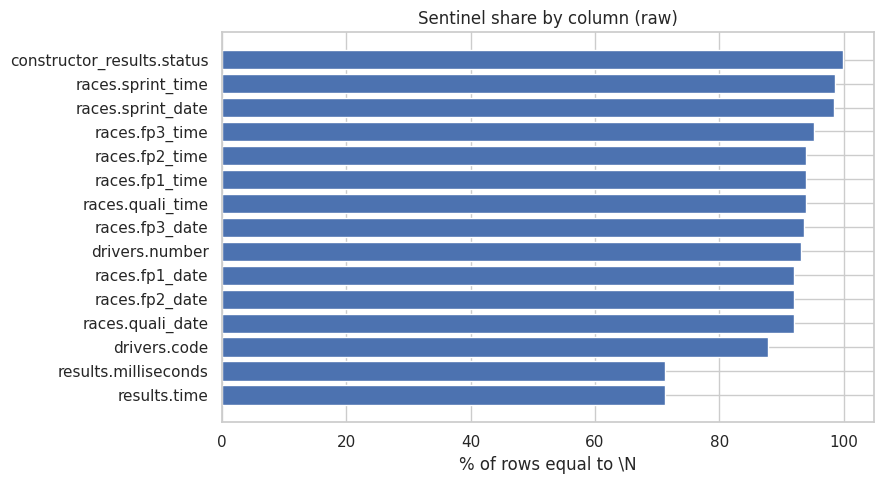

In [113]:
rows = []
for t, df in RAW.items():
    for c in df.columns:
        n = (df[c].astype(str) == r"\N").sum()
        if n:
            rows.append((t, c, n, round(100 * n / len(df), 1)))##calculates percentage of nulls
sentinel_report = (pd.DataFrame(rows, columns=["table","column","n_sentinel","pct"])
                   .sort_values("pct", ascending=False))
display(sentinel_report)

top = sentinel_report.head(15)
plt.figure(figsize=(9,5))
plt.barh(top.table + "." + top.column, top.pct); plt.gca().invert_yaxis()
plt.xlabel("% of rows equal to \\N"); plt.title("Sentinel share by column (raw)")
savefig("01_sentinels_raw")

### Audit 2: Checking Primary Keys

This cell checks whether each table has valid primary keys that uniquely identify its rows. It counts duplicate keys and missing key values, including values marked as `\N`. The final report shows whether each table passes the checks or has a problem that needs further investigation.

In [114]:
# AUDIT 2 — CHECK PRIMARY KEYS
# Project coverage: Data Cleaning & Auditing — primary-key validation.
# Each table has one or more columns that should uniquely identify its rows.
# This cell checks for duplicate primary keys and null/sentinel key values.

PKS = {"circuits":["circuitId"], "constructors":["constructorId"], "drivers":["driverId"],
       "races":["raceId"], "results":["resultId"], "status":["statusId"], "seasons":["year"],
       "qualifying":["qualifyId"], "driver_standings":["driverStandingsId"],
       "constructor_standings":["constructorStandingsId"],
       "constructor_results":["constructorResultsId"], "sprint_results":["resultId"],
       "pit_stops":["raceId","driverId","stop"], "lap_times":["raceId","driverId","lap"]}


##pass by every row and checks for /n or null values in primary keys
pk_rows = []
for t, k in PKS.items():
    df = RAW[t]
    n_dup  = int(df.duplicated(k).sum())
    n_null = int((df[k].isna() | df[k].astype(str).eq(r"\N")).any(axis=1).sum())  # catches \N too
    pk_rows.append((t, k, len(df), n_dup, n_null, "OK" if n_dup == 0 and n_null == 0 else "PROBLEM"))
pk_report = pd.DataFrame(pk_rows, columns=["table","pk","rows","duplicate_keys","null_keys","status"])
display(pk_report)

,table,pk,rows,duplicate_keys,null_keys,status
0,circuits,[circuitId],77,0,0,OK
1,constructors,[constructorId],212,0,0,OK
2,drivers,[driverId],861,0,0,OK
3,races,[raceId],1125,0,0,OK
4,results,[resultId],26759,0,0,OK
5,status,[statusId],139,0,0,OK
6,seasons,[year],75,0,0,OK
7,qualifying,[qualifyId],10494,0,0,OK
8,driver_standings,[driverStandingsId],34863,0,0,OK
9,constructor_standings,[constructorStandingsId],13391,0,0,OK


### Audit 3: Checking Foreign Keys

This cell checks whether IDs in related tables match existing IDs in their parent tables. For example, each `raceId` in the results table should exist in the races table. It counts **orphan rows**—rows containing references that do not match—and reports whether each relationship passes the check or has a problem.

In [115]:
# AUDIT 3 — CHECK FOREIGN KEYS
# Project coverage: Data Cleaning & Auditing — foreign-key reconciliation.
# Each listed child-table key should point to an existing key in its parent table.
# This cell counts orphan foreign-key values instead of relying on manual inspection.

FKS = [("results","raceId","races","raceId"), ("results","driverId","drivers","driverId"),
       ("results","constructorId","constructors","constructorId"), ("results","statusId","status","statusId"),
       ("races","circuitId","circuits","circuitId"), ("qualifying","raceId","races","raceId"),
       ("qualifying","driverId","drivers","driverId"), ("qualifying","constructorId","constructors","constructorId"),
       ("driver_standings","raceId","races","raceId"), ("driver_standings","driverId","drivers","driverId"),
       ("constructor_standings","raceId","races","raceId"),
       ("constructor_standings","constructorId","constructors","constructorId"),
       ("constructor_results","raceId","races","raceId"), ("constructor_results","constructorId","constructors","constructorId"),
       ("sprint_results","raceId","races","raceId"), ("sprint_results","driverId","drivers","driverId"),
       ("pit_stops","raceId","races","raceId"), ("pit_stops","driverId","drivers","driverId"),
       ("lap_times","raceId","races","raceId"), ("lap_times","driverId","drivers","driverId")]

fk_rows = []
for child, c, parent, p in FKS:
    orphans = int((~RAW[child][c].isin(RAW[parent][p])).sum())
    fk_rows.append((f"{child}.{c}", f"{parent}.{p}", len(RAW[child]), orphans, "OK" if orphans == 0 else "PROBLEM"))
fk_report = pd.DataFrame(fk_rows, columns=["child","parent","child_rows","orphan_rows","status"])
display(fk_report)

,child,parent,child_rows,orphan_rows,status
0,results.raceId,races.raceId,26759,0,OK
1,results.driverId,drivers.driverId,26759,0,OK
2,results.constructorId,constructors.constructorId,26759,0,OK
3,results.statusId,status.statusId,26759,0,OK
4,races.circuitId,circuits.circuitId,1125,0,OK
5,qualifying.raceId,races.raceId,10494,0,OK
6,qualifying.driverId,drivers.driverId,10494,0,OK
7,qualifying.constructorId,constructors.constructorId,10494,0,OK
8,driver_standings.raceId,races.raceId,34863,0,OK
9,driver_standings.driverId,drivers.driverId,34863,0,OK


### Initial EDA: Before Cleaning

This cell explores the raw data to understand its condition before cleaning. It plots the average number of drivers per race, the proportion of rows representing podium finishes, and duplicate race-driver records. It also checks how often qualifying data is available across seasons. These results provide a baseline for identifying data-quality issues and guiding the cleaning process.

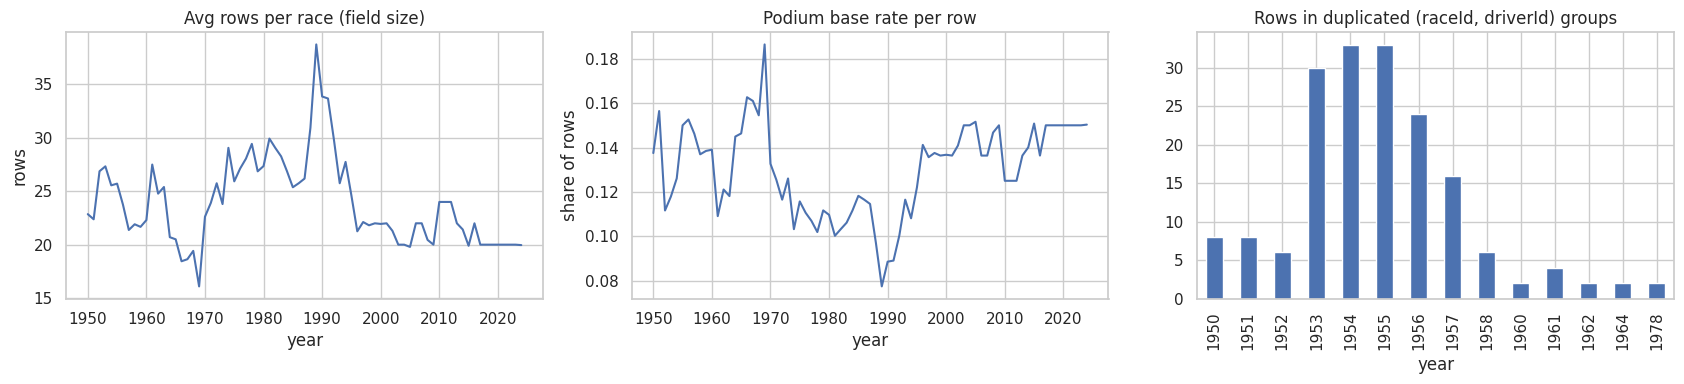

duplicate groups: 85 | rows involved: 176


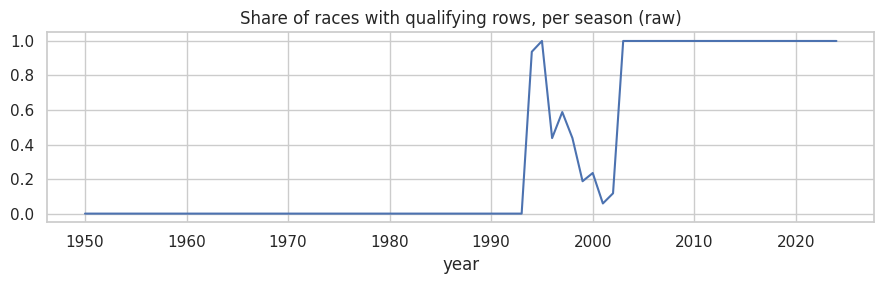

first season with qualifying data: 1994


In [116]:
# INITIAL EDA — BEFORE CLEANING
# Project coverage: Initial EDA before cleaning + duplicate-grain audit.
# We inspect field size, podium base rate, duplicate (raceId, driverId) rows,
# and the availability of qualifying data over the F1 seasons.
# These plots give us a baseline for comparing the data before and after cleaning.

res_raw = RAW["results"].merge(RAW["races"][["raceId","year"]], on="raceId")
res_raw["positionOrder"] = pd.to_numeric(res_raw["positionOrder"], errors="coerce")
res_raw["podium"] = (res_raw["positionOrder"] <= 3).astype(int)

dup_mask_raw = res_raw.duplicated(["raceId","driverId"], keep=False)
dup_raw = res_raw[dup_mask_raw]

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
res_raw.groupby(["year","raceId"]).size().groupby("year").mean().plot(ax=ax[0])
ax[0].set_title("Avg rows per race (field size)"); ax[0].set_ylabel("rows")
res_raw.groupby("year").podium.mean().plot(ax=ax[1])
ax[1].set_title("Podium base rate per row"); ax[1].set_ylabel("share of rows")
dup_raw.groupby("year").size().plot(kind="bar", ax=ax[2])
ax[2].set_title("Rows in duplicated (raceId, driverId) groups")
savefig("02_eda_before")

print("duplicate groups:", dup_raw.groupby(["raceId","driverId"]).ngroups, "| rows involved:", len(dup_raw))

# qualifying coverage per season
q_raw = RAW["qualifying"].merge(RAW["races"][["raceId","year"]], on="raceId")
cov = (RAW["races"].groupby("year").raceId.nunique().to_frame("races")
       .join(q_raw.groupby("year").raceId.nunique().rename("races_with_quali")).fillna(0))
cov["coverage"] = cov.races_with_quali / cov.races
cov.coverage.plot(figsize=(9,3), title="Share of races with qualifying rows, per season (raw)")
savefig("02_quali_coverage_raw")
print("first season with qualifying data:", cov[cov.races_with_quali > 0].index.min())

### Cleaning Step — Sentinels and Semantic Types

- **Handle missing values:** Convert `\N` into real `NaN` values so Pandas recognizes missing data.
- **Preserve raw data:** Create a separate cleaned copy called `CL`, leaving the original data unchanged.
- **Convert dates:** Convert race dates and driver birth dates into datetime format.
- **Convert lap times:** Convert qualifying and fastest lap times from strings (e.g., `1:27.452`) into seconds (`87.452`) for easier calculations.
- **Verify the cleaning:** Print data types, sample converted lap times, and the number of qualifying lap times that failed to convert.

In [117]:
# CL = cleaned copy. Same files, but \N is now real NaN.
CL = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv", na_values=[r"\N"]) for t in TABLES}

def lap_to_sec(s):
    # "1:27.452" -> 87.452 ; "58.123" -> 58.123 ; NaN stays NaN
    if pd.isna(s): return np.nan
    m = re.match(r"^(?:(\d+):)?(\d+(?:\.\d+)?)$", str(s).strip())
    return float(m.group(1) or 0) * 60 + float(m.group(2)) if m else np.nan

# dates -> datetime
CL["races"]["date"]   = pd.to_datetime(CL["races"]["date"])
CL["drivers"]["dob"]  = pd.to_datetime(CL["drivers"]["dob"])

# durations -> seconds
for c in ["q1","q2","q3"]:
    CL["qualifying"][c + "_s"] = CL["qualifying"][c].map(lap_to_sec)
CL["results"]["fastestLapTime_s"] = CL["results"]["fastestLapTime"].map(lap_to_sec)

# prove the conversion worked
print(CL["races"]["date"].dtype, CL["drivers"]["dob"].dtype)
print(CL["qualifying"][["q1","q1_s","q3","q3_s"]].dropna().head())
print("lap strings that failed to parse:",
      int((CL["qualifying"]["q1"].notna() & CL["qualifying"]["q1_s"].isna()).sum()))

datetime64[ns] datetime64[ns]
         q1    q1_s        q3    q3_s
0  1:26.572  86.572  1:26.714  86.714
1  1:26.103  86.103  1:26.869  86.869
2  1:25.664  85.664  1:27.079  87.079
3  1:25.994  85.994  1:27.178  87.178
4  1:25.960  85.960  1:27.236  87.236
lap strings that failed to parse: 0


### Build the Race-Driver Base Table and Inspect Duplicates

- **Merge tables:** Combine race results with race information and driver status to add context to each record.
- **Check duplicates:** Identify cases where the same driver has multiple rows for the same race (`raceId`, `driverId`).
- **Count duplicates:** Print the number of affected rows, duplicate groups, and the years in which duplicates occur.
- **Inspect examples:** Display the first 10 duplicate records, including race name, constructor, starting grid, finishing position, points, and race status.

**Purpose:** Detect duplicate driver-race records, which can occur in early F1 data because drivers sometimes shared cars. These must be investigated before building the final modeling table.

In [118]:
base = (CL["results"]
        .merge(CL["races"][["raceId","year","round","circuitId","name","date"]]
               .rename(columns={"name":"race_name"}), on="raceId")
        .merge(CL["status"], on="statusId"))

dups = base[base.duplicated(["raceId","driverId"], keep=False)]
print("rows involved:", len(dups), "| groups:", dups.groupby(["raceId","driverId"]).ngroups)
# print("years affected:", sorted(dups.year.unique()))
print("years affected:", sorted(dups.year.unique().tolist()))

# look at a few real examples
cols = ["race_name","year","driverId","constructorId","grid","positionOrder","points","status"]
display(dups.sort_values(["raceId","driverId"])[cols].head(10))

rows involved: 176 | groups: 85
years affected: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1960, 1961, 1962, 1964, 1978]


,race_name,year,driverId,constructorId,grid,positionOrder,points,status
13188,Italian Grand Prix,1978,229,54,0,26,0.0,Did not qualify
13191,Italian Grand Prix,1978,229,57,0,29,0.0,Did not prequalify
17362,United States Grand Prix,1964,373,172,1,7,0.0,Out of fuel
24298,United States Grand Prix,1964,373,172,1,12,0.0,Injection
17740,British Grand Prix,1962,465,172,0,22,0.0,Withdrew
17743,British Grand Prix,1962,465,97,0,25,0.0,Withdrew
17961,British Grand Prix,1961,475,102,20,19,0.0,Disqualified
17963,British Grand Prix,1961,475,172,5,21,0.0,Brakes
18062,United States Grand Prix,1961,418,172,11,17,0.0,Gearbox
24297,United States Grand Prix,1961,418,172,15,11,0.0,+8 Laps


### Fix the Required Grain: One Row per Driver per Race

- **Count original rows:** Save the number of rows before removing duplicates.
- **Prioritize valid grid positions:** Place rows with a real starting grid position (`grid != 0`) before rows with `grid == 0`.
- **Choose the best record:** Sort by race, driver, grid validity, and finishing position (`positionOrder`), then keep the first row for each driver in each race.
- **Remove duplicates:** Keep only one row per `(raceId, driverId)`.
- **Verify uniqueness:** Use `assert` to confirm that no duplicate driver-race pairs remain.
- **Print results:** Show how many rows were removed and how many remain.

**Purpose:** Ensure each driver has exactly one record per race before creating the machine learning dataset.

In [119]:
n_before = len(base)
base["_nogrid"] = (base.grid == 0).astype(int)
base = (base.sort_values(["raceId","driverId","_nogrid","positionOrder"])
            .drop_duplicates(["raceId","driverId"], keep="first")
            .drop(columns="_nogrid"))

assert not base.duplicated(["raceId","driverId"]).any(), "grain still broken"
print("rows removed:", n_before - len(base), "| final rows:", len(base))

rows removed: 91 | final rows: 26668


### Add Circuit Information and Check Early-F1 Edge Cases

- **Add circuit details:** Merge circuit names and countries into the base table.
- **Remove Indianapolis 500:** Identify and remove Indianapolis 500 records from 1950–1960 to exclude these races from the dataset.
- **Investigate `grid == 0`:** Count records with a zero starting grid and inspect their distribution by decade and race status to understand what these values mean.
- **Check missing positions:** Count missing finishing positions (`position`) and finishing-order values (`positionOrder`).

**Purpose:** Handle unusual historical F1 records carefully and document data-quality issues before modeling.

In [120]:
# (a) Indianapolis 500 (1950-1960)
base = base.merge(CL["circuits"][["circuitId","name","country"]]
                  .rename(columns={"name":"circuit_name","country":"circuit_country"}), on="circuitId")
indy = base.circuit_name.str.contains("Indianapolis", case=False) & (base.year <= 1960)
print("Indy 500 rows:", indy.sum(), "| races:", base[indy].raceId.nunique())
base = base[~indy]

# (b) what does grid == 0 mean? check, don't assume
g0 = base[base.grid == 0]
print("grid==0 rows:", len(g0), "of", len(base))
display(g0.groupby(g0.year // 10 * 10).size().to_frame("grid0_rows"))
display(g0.status.value_counts().head(10))

# (c) rows without a classified position
print("position missing:", base.position.isna().sum(), "| positionOrder missing:"
      , base.positionOrder.isna().sum())

Indy 500 rows: 381 | races: 11
grid==0 rows: 1635 of 26287


,grid0_rows
year,
1950,67
1960,197
1970,350
1980,571
1990,357
2000,8
2010,28
2020,57


status
Did not qualify       1012
Did not prequalify     330
Withdrew               163
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7
Engine                   6
Disqualified             6
Name: count, dtype: int64

position missing: 10717 | positionOrder missing: 0


### EDA — After Cleaning

- **Create the target variable:** Set `podium = 1` if a driver finishes in the top 3 (`positionOrder <= 3`), otherwise `0`.
- **Compare before vs. after cleaning:** Plot the average number of result rows per race and the podium rate for each year.
- **Analyze starting grid:** Plot the podium rate for the first 20 starting-grid positions to explore the relationship between starting position and podium success.
- **Save the plots:** Save the figure as `03_eda_after`.
- **Summarize cleaning impact:** Create a table comparing before and after cleaning, including total rows, duplicate records, unique races, unique drivers, missing values, and podium rate.

**Purpose:** Evaluate how cleaning affected the dataset and explore patterns in podium finishes before building machine learning models.

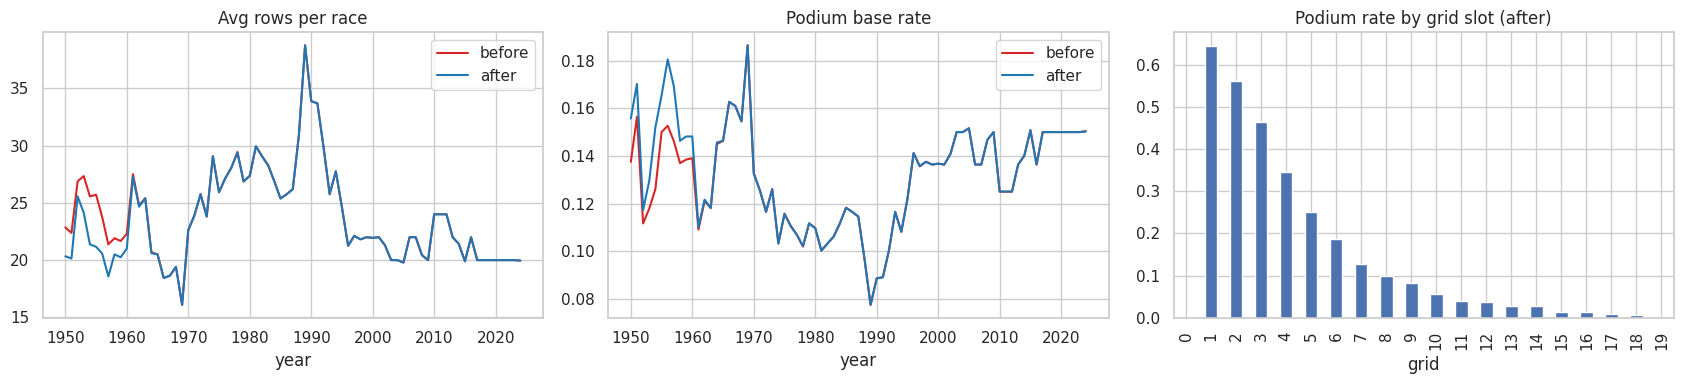

,metric,before,after
0,result rows,26759,26287.0000
1,"duplicate (raceId, driverId) rows",176,0.0000
2,unique races,1125,1114.0000
3,unique drivers,861,758.0000
4,\N sentinels in results (raw),122887,0.0000
5,NaN in results after cleaning,n/a,141394.0000
6,podium rate,0.1269,0.1278


In [121]:

base["podium"] = (base.positionOrder <= 3).astype(int)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for data, label, col in [(res_raw, "before", "tab:red"), (base, "after", "tab:blue")]:
    data.groupby(["year","raceId"]).size().groupby("year").mean().plot(ax=ax[0], label=label, color=col)
    data.groupby("year").podium.mean().plot(ax=ax[1], label=label, color=col)
ax[0].set_title("Avg rows per race"); ax[1].set_title("Podium base rate"); ax[0].legend(); ax[1].legend()
base.groupby("grid").podium.mean().head(20).plot(kind="bar", ax=ax[2], title="Podium rate by grid slot (after)")
savefig("03_eda_after")

summary = pd.DataFrame({
    "metric": ["result rows", "duplicate (raceId, driverId) rows", "unique races", "unique drivers",
               "\\N sentinels in results (raw)", "NaN in results after cleaning", "podium rate"],
    "before": [len(res_raw), int(res_raw.duplicated(["raceId","driverId"], keep=False).sum()),
               res_raw.raceId.nunique(), res_raw.driverId.nunique(),
               int(sentinel_report[sentinel_report.table == "results"].n_sentinel.sum()),
               "n/a", round(res_raw.podium.mean(), 4)],
    "after": [len(base), int(base.duplicated(["raceId","driverId"]).sum()),
              base.raceId.nunique(), base.driverId.nunique(),
              0, int(CL["results"].isna().sum().sum()), round(base.podium.mean(), 4)]})
display(summary)

### Build the Analytical Table for Questions 1–3

- **Prepare qualifying data:** Keep one qualifying record per driver per race and rename `position` to `quali_pos`.
- **Join driver information:** Add each driver's nationality.
- **Join constructor information:** Add each team's name.
- **Join qualifying position:** Add each driver's starting qualifying position to the base table.
- **Validate the joins:** Use `validate="m:1"` and assertions to ensure the joins do not multiply rows or create duplicate driver-race records.
- **Create the target:** Set `podium = 1` for a top-three finish and `0` otherwise.
- **Print a summary:** Display the table dimensions, podium rate, and proportion of rows with available qualifying positions.

**Purpose:** Build a reliable analytical dataset combining race results, driver nationality, constructor names, and qualifying positions for Questions 1–3.

In [122]:
from scipy.stats import spearmanr
from statsmodels.stats.proportion import proportion_confint
import statsmodels.formula.api as smf

# qualifying: one row per (raceId, driverId), checked in Objective 1
qual = (CL["qualifying"].sort_values(["raceId","driverId","qualifyId"])
        .drop_duplicates(["raceId","driverId"])[["raceId","driverId","position"]]
        .rename(columns={"position":"quali_pos"}))

df = (base
      .merge(CL["drivers"][["driverId","nationality"]], on="driverId", how="left", validate="m:1")
      .merge(CL["constructors"][["constructorId","name"]].rename(columns={"name":"constructor"}),
             on="constructorId", how="left", validate="m:1")
      .merge(qual, on=["raceId","driverId"], how="left", validate="m:1"))

assert len(df) == len(base), "a join multiplied or dropped rows"
assert not df.duplicated(["raceId","driverId"]).any()
df["podium"] = (df.positionOrder <= 3).astype(int)
print(df.shape, "| podium rate:", round(df.podium.mean(), 3), "| rows with quali_pos:", round(df.quali_pos.notna().mean(), 3))

(26287, 31) | podium rate: 0.128 | rows with quali_pos: 0.399


### Qualifying Coverage and Era Cutoff

- **Measure qualifying coverage:** Calculate the percentage of race-result rows with an available qualifying position for each season.
- **Plot coverage:** Create a graph showing how qualifying data availability changes over time.
- **Choose the cutoff year:** Find the first season where qualifying coverage reaches at least 90% and store it in `Q_START`.
- **Define eras:** Split the analysis into two periods: `Q_START–2013` and `2014+`.
- **Filter the data:** Keep seasons from `Q_START` onward and assign each row to its corresponding era.

**Purpose:** Ensure the analysis uses seasons with sufficiently complete qualifying data and compare results before and after the 2014 regulation era.

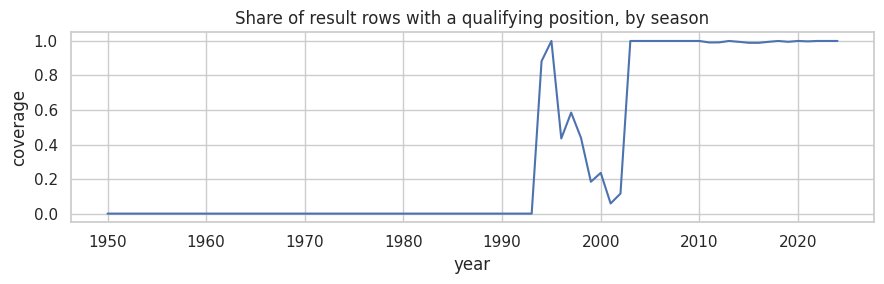

qualifying coverage >= 90% from: 1995


In [123]:
cov = df.groupby("year").quali_pos.apply(lambda s: s.notna().mean())
cov.plot(figsize=(9,3), title="Share of result rows with a qualifying position, by season")
plt.ylabel("coverage"); savefig("05_q1_quali_coverage")

Q_START = int(cov[cov >= 0.9].index.min())
ERA_OLD, ERA_NEW = f"{Q_START}-2013", "2014+"
print("qualifying coverage >= 90% from:", Q_START)

d = df[df.year >= Q_START].copy()
d["era"] = np.where(d.year >= 2014, ERA_NEW, ERA_OLD)

### Question 1 — Qualifying Front Row vs. Actual Grid Front Row

- **Filter valid data:** Keep only rows with an available qualifying position.
- **Define qualifying front row:** Identify drivers who qualified in positions 1–2.
- **Define actual grid front row:** Identify drivers who started the race from grid positions 1–2.
- **Compare both orders:** Create a cross-tabulation showing how qualifying positions compare with actual starting positions.
- **Check pit-lane starts:** Count drivers who qualified in the top two but had `grid == 0`, indicating a recorded zero grid position.

**Purpose:** Investigate whether the qualifying front row matches the actual starting front row, since penalties and other circumstances can change the starting order.

In [124]:
c = d[d.quali_pos.notna()]
display(pd.crosstab(c.quali_pos.le(2).rename("quali_front_row")
                    , c.grid.between(1, 2).rename("grid_front_row")))
print("qualified front row but started from the pit lane:", int(((c.quali_pos <= 2) & (c.grid == 0)).sum()))

grid_front_row,False,True
quali_front_row,,
False,9108,36
True,38,920


qualified front row but started from the pit lane: 2


### Question 1 — Circuit Front-Row-to-Podium Rates

- **`front_row_table()`:** For each circuit and era, counts front-row starts and podium finishes, calculates the podium rate, and computes Wilson confidence intervals to show uncertainty.
- **`compare()`:** Keeps circuits with at least 10 front-row starts in both eras, compares their podium rates, ranks them in each era, and calculates rank changes.
- **`dumbbell()`:** Creates a chart comparing each circuit's podium rate between the two eras, including confidence intervals for the newer era.
- **Run the analysis twice:** First using qualifying positions 1–2, then using actual grid positions 1–2.
- **Calculate Spearman correlation:** Measures how similarly circuits rank across the two eras.
- **Display and save results:** Prints the top 12 circuits and saves a comparison chart for each analysis.

**Purpose:** Determine how often front-row starters reach the podium at each circuit, whether conversion rates changed after 2014, and whether circuit rankings remained consistent.


Qualifying front row: 14 circuits kept of 42 | Spearman rank corr across eras = 0.34 (p=0.240)


era,1995-2013,2014+,n_old,n_new,rank_old,rank_new,rank_change
circuit_name,,,,,,,
Suzuka Circuit,0.750,0.889,24.0,18.0,1.0,1.0,0.0
Circuit de Monaco,0.643,0.850,28.0,20.0,6.0,2.0,4.0
Circuit de Spa-Francorchamps,0.591,0.818,22.0,22.0,11.0,3.0,8.0
Yas Marina Circuit,0.600,0.818,10.0,22.0,9.0,3.0,6.0
Circuit de Barcelona-Catalunya,0.607,0.818,28.0,22.0,8.0,3.0,5.0
Shanghai International Circuit,0.700,0.786,20.0,14.0,2.0,6.0,-4.0
Silverstone Circuit,0.667,0.750,30.0,24.0,3.0,7.0,-4.0
Autodromo Nazionale di Monza,0.667,0.727,24.0,22.0,3.0,8.0,-5.0
Circuit Gilles Villeneuve,0.542,0.722,24.0,18.0,13.0,9.0,4.0


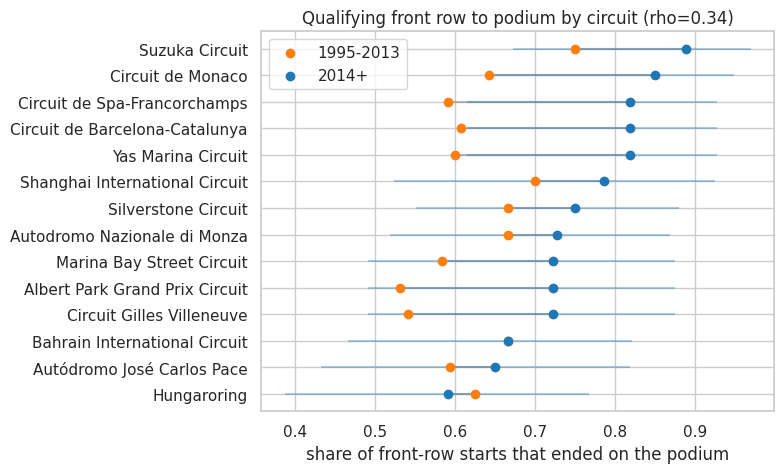


Grid front row: 15 circuits kept of 43 | Spearman rank corr across eras = -0.11 (p=0.684)


era,1995-2013,2014+,n_old,n_new,rank_old,rank_new,rank_change
circuit_name,,,,,,,
Suzuka Circuit,0.735,0.889,34.0,18.0,1.0,1.0,0.0
Yas Marina Circuit,0.600,0.864,10.0,22.0,10.0,2.0,8.0
Circuit de Monaco,0.658,0.850,38.0,20.0,4.0,3.0,1.0
Circuit de Barcelona-Catalunya,0.632,0.818,38.0,22.0,8.0,4.0,4.0
Circuit de Spa-Francorchamps,0.529,0.818,34.0,22.0,15.0,4.0,11.0
Autódromo José Carlos Pace,0.553,0.789,38.0,19.0,14.0,6.0,8.0
Shanghai International Circuit,0.650,0.786,20.0,14.0,6.0,7.0,-1.0
Circuit Gilles Villeneuve,0.556,0.778,36.0,18.0,12.0,8.0,4.0
Silverstone Circuit,0.632,0.750,38.0,24.0,8.0,9.0,-1.0


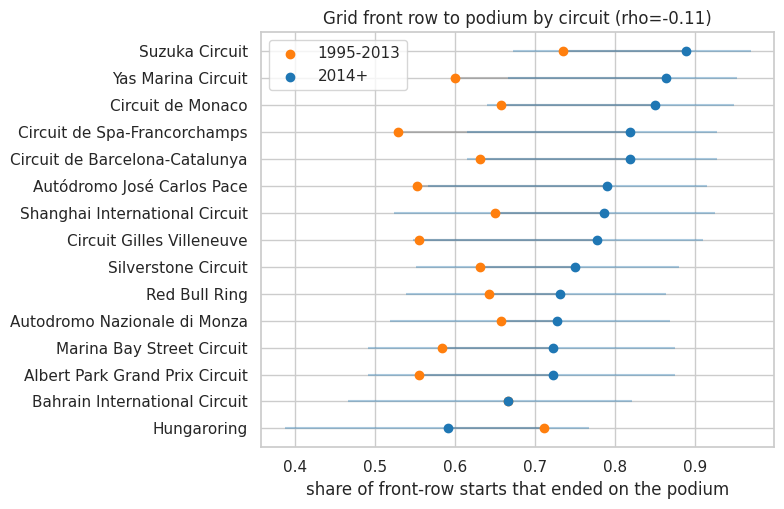

In [125]:
def front_row_table(d, col):
    x = d[d[col].between(1, 2)]                      # NaN and grid 0 drop out automatically
    t = (x.groupby(["circuit_name","era"])
           .agg(starts=("podium","size"), podiums=("podium","sum")).reset_index())
    t["rate"] = t.podiums / t.starts
    t["lo"], t["hi"] = proportion_confint(t.podiums, t.starts, method="wilson")
    return t

def compare(t, min_starts=10):
    n = t.pivot(index="circuit_name", columns="era", values="starts")
    keep = n[(n[[ERA_OLD, ERA_NEW]] >= min_starts).all(axis=1)].index
    piv = lambda v: t.pivot(index="circuit_name", columns="era", values=v).loc[keep, [ERA_OLD, ERA_NEW]]
    r, lo, hi = piv("rate"), piv("lo"), piv("hi")
    r["n_old"], r["n_new"] = n.loc[keep, ERA_OLD], n.loc[keep, ERA_NEW]
    r["lo_old"], r["hi_old"], r["lo_new"], r["hi_new"] = lo[ERA_OLD], hi[ERA_OLD], lo[ERA_NEW], hi[ERA_NEW]
    r["rank_old"] = r[ERA_OLD].rank(ascending=False, method="min")
    r["rank_new"] = r[ERA_NEW].rank(ascending=False, method="min")
    r["rank_change"] = r.rank_old - r.rank_new          # positive = moved up after 2014
    return r.sort_values(ERA_NEW, ascending=False)

def dumbbell(r, title, fname):
    r = r.sort_values(ERA_NEW); y = np.arange(len(r))
    fig, ax = plt.subplots(figsize=(8, max(4, 0.35 * len(r))))
    ax.hlines(y, r[ERA_OLD], r[ERA_NEW], color="grey", alpha=.5)
    ax.scatter(r[ERA_OLD], y, color="tab:orange", label=ERA_OLD, zorder=3)
    ax.scatter(r[ERA_NEW], y, color="tab:blue", label=ERA_NEW, zorder=3)
    ax.errorbar(r[ERA_NEW], y, xerr=[r[ERA_NEW]-r.lo_new, r.hi_new-r[ERA_NEW]], fmt="none", ecolor="tab:blue", alpha=.35)
    ax.set_yticks(y); ax.set_yticklabels(r.index)
    ax.set_xlabel("share of front-row starts that ended on the podium"); ax.set_title(title); ax.legend()
    savefig(fname)

Q1 = {}
for col, label in [("quali_pos", "Qualifying front row"), ("grid", "Grid front row")]:
    t = front_row_table(d, col)
    r = compare(t); Q1[col] = r
    rho, p = spearmanr(r[ERA_OLD], r[ERA_NEW])
    print(f"\n{label}: {len(r)} circuits kept of {t.circuit_name.nunique()} | Spearman rank corr across eras = {rho:.2f} (p={p:.3f})")
    display(r[[ERA_OLD, ERA_NEW, "n_old", "n_new", "rank_old", "rank_new", "rank_change"]].round(3).head(12))
    dumbbell(r, f"{label} to podium by circuit (rho={rho:.2f})", f"05_q1_{col}")

### Question 1 — Qualifying-Based vs. Grid-Based Ranking

- **Get the rankings:** Extract each circuit's podium-conversion rate for the `2014+` era, using qualifying positions and actual grid positions separately.
- **Find common circuits:** Keep only circuits that appear in both rankings.
- **Calculate Spearman correlation:** Measure how similar the two circuit rankings are.
- **Print the result:** Display the Spearman correlation rounded to two decimal places.

**Purpose:** Determine whether circuit rankings based on qualifying front-row positions are similar to rankings based on actual grid front-row positions, which may differ because of penalties or starting-grid changes.

In [126]:
a, b = Q1["quali_pos"][ERA_NEW], Q1["grid"][ERA_NEW]
common = a.index.intersection(b.index)
print("Qualifying-based vs grid-based ranking (2014+): Spearman =", round(spearmanr(a[common], b[common]).correlation, 2))

Qualifying-based vs grid-based ranking (2014+): Spearman = 0.84


### Question 2 — Define Home Race

- **Map nationalities to countries:** Convert driver nationalities into country names that match the circuit-country data.
- **Standardize country names:** Change `"United States"` to `"USA"` so the country names match.
- **Exclude invalid starting positions:** Keep drivers with `grid >= 1` and count the pit-lane/no-slot rows excluded.
- **Check unmapped nationalities:** Identify driver nationalities that could not be mapped to a country.
- **Remove incomplete records:** Exclude rows with missing driver or circuit countries.
- **Define home race:** Create `home = 1` when the driver's country matches the circuit country; otherwise, set `home = 0`.
- **Check country mismatches:** List mapped countries that do not match any circuit-country name and display the number of home-race rows by country.

**Purpose:** Identify drivers racing at circuits in their home country so their performance can be compared with their performance at other circuits.

In [127]:
NAT2COUNTRY = {"British":"UK","German":"Germany","Italian":"Italy","French":"France","Spanish":"Spain","Brazilian":"Brazil",
 "Australian":"Australia","Japanese":"Japan","Canadian":"Canada","Monegasque":"Monaco","Dutch":"Netherlands","Belgian":"Belgium",
 "Austrian":"Austria","Hungarian":"Hungary","Mexican":"Mexico","Portuguese":"Portugal","Argentine":"Argentina",
 "Argentinian":"Argentina","Swedish":"Sweden","Swiss":"Switzerland","South African":"South Africa","Malaysian":"Malaysia",
 "Chinese":"China","American":"USA","Finnish":"Finland","Russian":"Russia","Indian":"India","Danish":"Denmark",
 "Polish":"Poland","Venezuelan":"Venezuela","Colombian":"Colombia","Indonesian":"Indonesia","Thai":"Thailand",
              "New Zealander": "New Zealand","Irish": "Ireland","Chilean": "Chile","Rhodesian": "Rhodesia","Liechtensteiner": "Liechtenstein",
"Uruguayan": "Uruguay",
"East German": "East Germany",
"Czech": "Czech Republic",  
              }

df["circuit_country"] = df.circuit_country.replace(
    {"United States": "USA"}
)

print("circuit countries in the data:", sorted(df.circuit_country.dropna().unique()))

df["nationality"] = df["nationality"].str.strip()
df["driver_country"] = df["nationality"].map(NAT2COUNTRY)
# df["driver_country"] = df.nationality.map(NAT2COUNTRY)

h = df[df.grid >= 1].copy()                                  # actual grid starters; pit-lane starts (0) excluded
print("pit-lane / no-slot rows excluded:", int((df.grid == 0).sum()))
print("unmapped nationalities (excluded):\n",
      h[h.driver_country.isna()].nationality.value_counts().head(15))
h = h[h.driver_country.notna() & h.circuit_country.notna()].copy()
h["home"] = (h.driver_country == h.circuit_country).astype(int)

print("mapped countries with no matching circuit (naming mismatch?):"
      , sorted(set(NAT2COUNTRY.values()) - set(h.circuit_country)))
print("home rows:", int(h.home.sum()), "of", len(h))
display(h[h.home == 1].groupby("circuit_country").size().sort_values(ascending=False))

circuit countries in the data: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA']
pit-lane / no-slot rows excluded: 1635
unmapped nationalities (excluded):
 nationality
Argentine-Italian    2
American-Italian     1
Name: count, dtype: int64
mapped countries with no matching circuit (naming mismatch?): ['Chile', 'Colombia', 'Czech Republic', 'Denmark', 'East Germany', 'Finland', 'Indonesia', 'Ireland', 'Liechtenstein', 'New Zealand', 'Poland', 'Rhodesia', 'Thailand', 'Uruguay', 'Venezuela']
home rows: 1937 of 24649


circuit_country
UK              451
Italy           403
France          207
Germany         199
Brazil          114
USA             112
Spain            61
Belgium          60
Japan            53
South Africa     46
Argentina        44
Canada           32
Austria          29
Australia        27
Mexico           24
Netherlands      22
Switzerland      13
Sweden           12
Monaco            9
Russia            8
Portugal          5
Hungary           2
India             2
China             1
Malaysia          1
dtype: int64

### Question 2 — Control for Starting Position

- **Group grid positions:** Divide starting positions into five buckets: `1–3`, `4–6`, `7–10`, `11–15`, and `16+`.
- **Compare home vs. away:** Calculate the overall podium rate and average starting-grid position for home and away races.
- **Calculate rates by bucket:** For each grid bucket, count the starts and podium finishes for home and away drivers, then calculate their podium rates and Wilson confidence intervals.
- **Visualize the comparison:** Create a bar chart comparing home and away podium rates within each starting-position bucket, including uncertainty intervals.
- **Calculate expected home podiums:** Estimate how many podiums home drivers would have achieved if they had the same podium rates as away drivers starting in the same grid-position buckets.
- **Compare observed vs. expected:** Print the actual number of home podiums and the estimated number based on away-driver rates.

**Purpose:** Investigate whether home drivers perform better at home after accounting for starting position, since starting near the front naturally increases the chance of reaching the podium.

naive podium rate  home: 0.119 | away: 0.138
mean grid slot     home: 12.7 | away: 11.71


,grid_bucket,home,n,podiums,rate,lo,hi
0,1-3,0,3106,1725,0.555,0.538,0.573
1,1-3,1,229,131,0.572,0.507,0.634
2,4-6,0,3108,812,0.261,0.246,0.277
3,4-6,1,225,61,0.271,0.217,0.333
4,7-10,0,4123,385,0.093,0.085,0.103
5,7-10,1,337,25,0.074,0.051,0.107
6,11-15,0,5134,154,0.030,0.026,0.035
7,11-15,1,414,11,0.027,0.015,0.047
8,16+,0,7241,53,0.007,0.006,0.010
9,16+,1,732,2,0.003,0.001,0.010


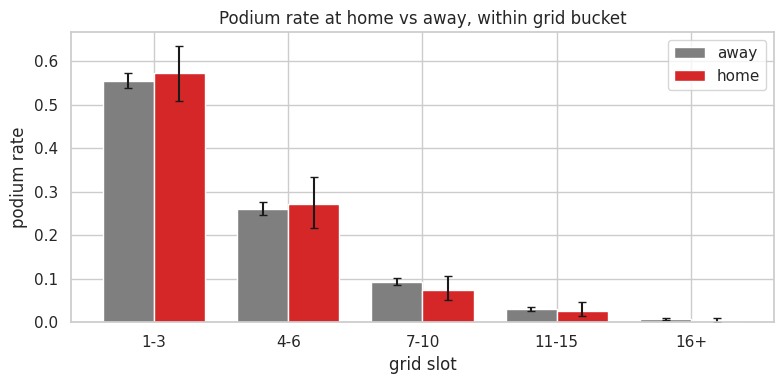

In [128]:
labels = ["1-3","4-6","7-10","11-15","16+"]
h["grid_bucket"] = pd.cut(h.grid, [0,3,6,10,15,100], labels=labels)

print("naive podium rate  home:", round(h[h.home==1].podium.mean(), 3), "| away:", round(h[h.home==0].podium.mean(), 3))
print("mean grid slot     home:", round(h[h.home==1].grid.mean(), 2), "| away:", round(h[h.home==0].grid.mean(), 2))

tab = (h.groupby(["grid_bucket","home"], observed=True)
         .agg(n=("podium","size"), podiums=("podium","sum")).reset_index())
tab["rate"] = tab.podiums / tab.n
tab["lo"], tab["hi"] = proportion_confint(tab.podiums, tab.n, method="wilson")
display(tab.round(3))

fig, ax = plt.subplots(figsize=(8, 4)); w = .38
for k, (flag, lab, col) in enumerate([(0, "away", "tab:grey"), (1, "home", "tab:red")]):
    s = tab[tab.home == flag].set_index("grid_bucket").reindex(labels)
    ax.bar(np.arange(len(labels)) + (k - .5) * w, s.rate, w, label=lab, color=col,
           yerr=[s.rate - s.lo, s.hi - s.rate], capsize=3)
ax.set_xticks(np.arange(len(labels))); ax.set_xticklabels(labels)
ax.set_xlabel("grid slot"); ax.set_ylabel("podium rate"); ax.set_title("Podium rate at home vs away, within grid bucket"); ax.legend()
savefig("05_q2_home_by_grid")

# direct standardisation: how many podiums would home starts have produced at the away drivers' rate in the same grid bucket?
away_rate = h[h.home == 0].groupby(h.grid_bucket.astype(str)).podium.mean()
hm = h[h.home == 1]
expected = hm.grid_bucket.astype(str).map(away_rate).sum()
# print(f"home podiums observed: {hm.podium.sum()} | expected from away rates in same grid buckets: {expected:.1f}")

### Question 2 — Logistic Regression with Grid Controls

- **Create `fit_home()`:** Fit a logistic regression model and extract the home effect as an odds ratio, its 95% confidence interval, p-value, and number of observations.
- **M0 — Naive:** Estimate the relationship between racing at home and achieving a podium without controlling for other factors.
- **M1 — Log grid:** Add the logarithm of the starting position to control for how grid position affects podium chances.
- **M2 — Grid buckets:** Control for starting position using five groups: 1–3, 4–6, 7–10, 11–15, and 16+.
- **M3 — Grid and season:** Control for starting position and season, accounting for changes in F1 across different years.
- **Clustered standard errors:** Account for repeated observations of the same driver across multiple races.
- **Display and visualize results:** Show the odds ratio and confidence interval for each model. The dashed vertical line at 1 represents no association between racing at home and podium chances.

**Purpose:** Test whether a home-race advantage exists and whether the estimated relationship changes after controlling for starting position and season.

,model,odds_ratio,ci_low,ci_high,p_value,n
0,M0 naive,0.843,0.709,1.002,0.053,24649
1,M1 + log(grid),0.937,0.764,1.149,0.532,24649
2,M2 + grid buckets,0.965,0.797,1.169,0.718,24649
3,M3 + grid + season effects,0.917,0.742,1.132,0.419,24649


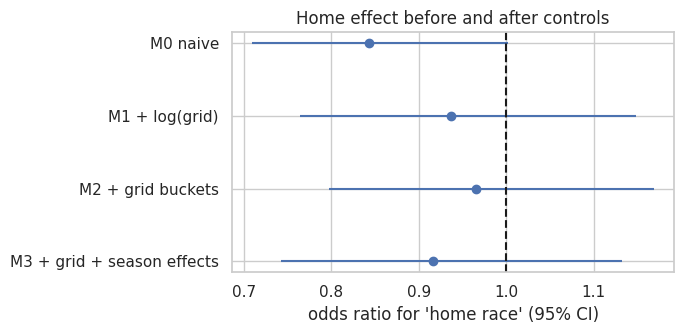

In [129]:
 # del C
if "C" in globals():
    del C

def fit_home(formula, label):
    m = smf.logit(formula, data=h).fit(disp=0, cov_type="cluster", cov_kwds={"groups": h["driverId"].values})
    ci = np.exp(m.conf_int().loc["home"])
    return {"model": label, "odds_ratio": np.exp(m.params["home"]), "ci_low": ci[0], "ci_high": ci[1],
            "p_value": m.pvalues["home"], "n": int(m.nobs)}

res2 = pd.DataFrame([
    fit_home("podium ~ home",                              "M0 naive"),
    fit_home("podium ~ home + np.log(grid)",               "M1 + log(grid)"),
    fit_home("podium ~ home + C(grid_bucket)",             "M2 + grid buckets"),
    fit_home("podium ~ home + np.log(grid) + C(year)",     "M3 + grid + season effects"),
])
display(res2.round(3))

plt.figure(figsize=(7, 3.5))
plt.errorbar(res2.odds_ratio, range(len(res2)), xerr=[res2.odds_ratio - res2.ci_low, res2.ci_high - res2.odds_ratio], fmt="o")
plt.axvline(1, color="k", ls="--"); plt.yticks(range(len(res2)), res2.model); plt.gca().invert_yaxis()
plt.xlabel("odds ratio for 'home race' (95% CI)"); plt.title("Home effect before and after controls"); savefig("05_q2_home_oddsratio")

### Question 3 — Classify Mechanical vs. Non-Mechanical Retirements

- **Define keyword lists:** Create lists of keywords for mechanical failures, accidents or driver-related incidents, and ambiguous statuses.
- **Create `classify()`:** Assign each F1 status to one of seven categories: `finished`, `regulation`, `no_start`, `accident_driver`, `mechanical`, `ambiguous`, or `other`.
- **Apply classification:** Use the function to classify every status description and store the result in a new `group` column.
- **Count recent statuses:** Count how often each status occurred in races from 2014 onward.
- **Combine and sort results:** Merge the status categories with their counts, then organize them by category and frequency.
- **Display the review table:** Show each original status, its assigned category, and its frequency since 2014 to help identify possible classification errors.

**Purpose:** Prepare a consistent classification of F1 race statuses so mechanical and non-mechanical retirements can be compared in Question 3. Ambiguous cases are kept separate so their impact on the final results can be tested.

In [130]:
MECH_KEYS = ["engine","gearbox","transmission","hydraulic","brake","power unit","turbo","electrical","electronics",
 "suspension","clutch","oil","water","overheat","fuel pressure","fuel system","fuel pump","fuel leak","exhaust",
 "drivetrain","differential","mechanical","technical","power loss","cooling","energy recovery","mgu","throttle",
 "driveshaft","steering","battery","radiator","vibration","pneumatic","misfire","spark plug","ignition"]
ACCIDENT_KEYS = ["collision","accident","spun off","crash","damage"]
AMBIGUOUS_KEYS = ["puncture","tyre","tire","wheel","wing","undertray","debris","retired","illness","unwell","safety","seat","fuel"]

def classify(s):
    t = str(s).lower()
    if t == "finished" or t.startswith("+"):                 return "finished"
    if any(k in t for k in ["disqualif","excluded"]):         return "regulation"
    if any(k in t for k in ["did not","withdrew"]):           return "no_start"
    if any(k in t for k in ACCIDENT_KEYS):                    return "accident_driver"
    if any(k in t for k in MECH_KEYS) or re.search(r"\bers\b", t): return "mechanical"
    if any(k in t for k in AMBIGUOUS_KEYS):                   return "ambiguous"
    return "other"

st = CL["status"].copy(); st["group"] = st.status.map(classify)
cnt = df[df.year >= 2014].statusId.value_counts().rename("n_2014plus")
review = st.merge(cnt, left_on="statusId", right_index=True).sort_values(["group","n_2014plus"], ascending=[True, False])
pd.set_option("display.max_rows", 200)
display(review[["status","group","n_2014plus"]])

,status,group,n_2014plus
3,Collision,accident_driver,150
2,Accident,accident_driver,85
127,Collision damage,accident_driver,59
19,Spun off,accident_driver,11
134,Damage,accident_driver,2
30,Retired,ambiguous,50
35,Wheel,ambiguous,11
28,Puncture,ambiguous,7
26,Tyre,ambiguous,4
137,Undertray,ambiguous,4


### Question 3 — Define Time Periods and Create the Race-Start Table

- **Filter the years:** Keep F1 race records from 2014 to 2024.
- **Classify race statuses:** Apply the `classify()` function to assign each status to a category, such as mechanical, accident-related, or finished.
- **Create two periods:** Divide the data into `2014–2021` and `2022–2024` to compare mechanical-retirement rates across the two periods.
- **Inspect constructor names:** Display each constructor's first year, last year, and number of records to identify teams that changed names over time.
- **Combine team lineages:** Group known constructor-name changes under a common `team` name, such as Toro Rosso, AlphaTauri, and RB, so their records can be analyzed together.
- **Exclude non-starts:** Remove records classified as `no_start` because those cars did not actually participate in the race. These records should not count in the denominator when calculating mechanical-retirement rates.
- **Validate the data:** Use an assertion to check that the race-start records and excluded non-start records add up to the original number of rows.

**Purpose:** Prepare a consistent dataset for comparing mechanical-retirement rates between 2014–2021 and 2022–2024, using actual race starts as the denominator.

In [131]:
d3 = df[df.year.between(2014, 2024)].copy()
d3["status_group"] = d3.status.map(classify)
d3["period"] = np.where(d3.year <= 2021, "2014-2021", "2022-2024")

print(d3.groupby("constructor").year.agg(["min","max","size"]).sort_values("size", ascending=False))   # check names before mapping
LINEAGE = {"Toro Rosso":"Toro Rosso / AlphaTauri / RB", "AlphaTauri":"Toro Rosso / AlphaTauri / RB", "RB F1 Team":"Toro Rosso / AlphaTauri / RB",
           "Force India":"Force India / Racing Point / Aston Martin", "Racing Point":"Force India / Racing Point / Aston Martin",
           "Aston Martin":"Force India / Racing Point / Aston Martin",
           "Sauber":"Sauber / Alfa Romeo", "Alfa Romeo":"Sauber / Alfa Romeo",
           "Lotus F1":"Lotus F1 / Renault / Alpine", "Renault":"Lotus F1 / Renault / Alpine", "Alpine F1 Team":"Lotus F1 / Renault / Alpine",
           "Marussia":"Marussia / Manor", "Manor Marussia":"Marussia / Manor"}
d3["team"] = d3.constructor.map(LINEAGE).fillna(d3.constructor)

starts = d3[d3.status_group != "no_start"].copy()            # a race start = the car actually took part
assert len(starts) + (d3.status_group == "no_start").sum() == len(d3)
print("rows:", len(d3), "| race starts:", len(starts), "| did-not-start rows excluded:", int((d3.status_group == "no_start").sum()))

                 min   max  size
constructor                     
Mercedes        2014  2024   456
Red Bull        2014  2024   456
McLaren         2014  2024   456
Ferrari         2014  2024   456
Williams        2014  2024   455
Haas F1 Team    2016  2024   380
Sauber          2014  2024   248
Toro Rosso      2014  2019   242
Alfa Romeo      2019  2023   208
Force India     2014  2018   200
Renault         2016  2020   200
Alpine F1 Team  2021  2024   180
Aston Martin    2021  2024   180
AlphaTauri      2020  2023   166
Manor Marussia  2015  2016    78
Lotus F1        2014  2015    76
Racing Point    2019  2020    76
RB F1 Team      2024  2024    48
Caterham        2014  2014    34
Marussia        2014  2014    31
rows: 4626 | race starts: 4612 | did-not-start rows excluded: 14


### Question 3 — Calculate Mechanical-Retirement Rates

- **Create `mech_rates()`:** Calculate the number of race starts, mechanical retirements, and mechanical-retirement rate for each team in each time period.
- **Define two classification approaches:** The *strict definition* counts only mechanical statuses, while the *broad definition* also includes ambiguous statuses to test how uncertain cases affect the results.
- **Calculate retirement rates:** Divide the number of mechanical retirements by the total race starts for each team and period.
- **Calculate confidence intervals:** Use Wilson confidence intervals to estimate uncertainty around each team's retirement rate.
- **Set a minimum sample size:** Require at least 40 race starts before including a team in the main comparison, reducing the influence of rates based on very few starts.
- **Visualize the results:** Create separate horizontal bar charts for 2014–2021 and 2022–2024, showing strict mechanical-retirement rates with confidence intervals.
- **Display the top five teams:** For each period, list the five teams with the highest strict mechanical-retirement rates, including their starts, retirements, rates, and confidence intervals.
- **Compare periods:** Calculate the change in mechanical-retirement rate for teams appearing in both periods. A positive change indicates a higher rate in 2022–2024, while a negative change indicates a lower rate.

**Purpose:** Identify teams with the highest mechanical-retirement rates, compare reliability between the two periods, and assess whether the conclusions change when ambiguous statuses are included.

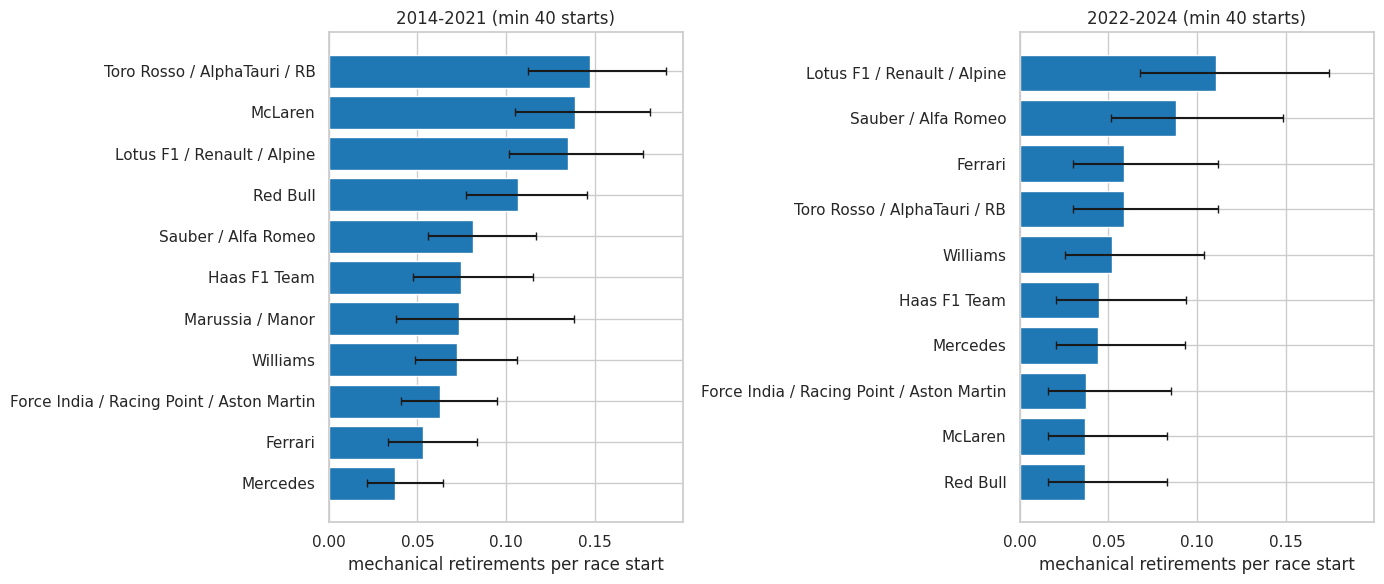


Top 5, 2014-2021, strict definition


,team,starts,mech,rate,lo,hi
18,Toro Rosso / AlphaTauri / RB,320,47,0.147,0.112,0.190
10,McLaren,318,44,0.138,0.105,0.181
7,Lotus F1 / Renault / Alpine,319,43,0.135,0.102,0.177
14,Red Bull,319,34,0.107,0.077,0.145
16,Sauber / Alfa Romeo,320,26,0.081,0.056,0.116



Top 5, 2022-2024, strict definition


,team,starts,mech,rate,lo,hi
8,Lotus F1 / Renault / Alpine,136,15,0.110,0.068,0.174
17,Sauber / Alfa Romeo,136,12,0.088,0.051,0.148
19,Toro Rosso / AlphaTauri / RB,136,8,0.059,0.030,0.112
2,Ferrari,136,8,0.059,0.030,0.112
21,Williams,134,7,0.052,0.026,0.104


period,2014-2021,2022-2024,change
team,,,
McLaren,0.138,0.037,-0.102
Toro Rosso / AlphaTauri / RB,0.147,0.059,-0.088
Red Bull,0.107,0.037,-0.070
Haas F1 Team,0.075,0.044,-0.030
Force India / Racing Point / Aston Martin,0.063,0.038,-0.025
Lotus F1 / Renault / Alpine,0.135,0.110,-0.025
Williams,0.072,0.052,-0.020
Ferrari,0.053,0.059,0.006
Mercedes,0.038,0.044,0.007


In [132]:
def mech_rates(starts, groups, label):
    x = starts.assign(mech=starts.status_group.isin(groups).astype(int))
    t = x.groupby(["team","period"]).agg(starts=("mech","size"), mech=("mech","sum")).reset_index()
    t["rate"] = t.mech / t.starts
    t["lo"], t["hi"] = proportion_confint(t.mech, t.starts, method="wilson")
    t["definition"] = label
    return t

strict = mech_rates(starts, {"mechanical"}, "strict")
broad  = mech_rates(starts, {"mechanical","ambiguous"}, "broad")
MIN_STARTS = 40

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, period in zip(axes, ["2014-2021", "2022-2024"]):
    x = strict[(strict.period == period) & (strict.starts >= MIN_STARTS)].sort_values("rate")
    ax.barh(x.team, x.rate, xerr=[x.rate - x.lo, x.hi - x.rate], capsize=3, color="tab:blue")
    ax.set_title(f"{period} (min {MIN_STARTS} starts)"); ax.set_xlabel("mechanical retirements per race start")
savefig("05_q3_mech_by_period")

for period in ["2014-2021", "2022-2024"]:
    print(f"\nTop 5, {period}, strict definition")
    display(strict[(strict.period == period) & (strict.starts >= MIN_STARTS)].sort_values("rate", ascending=False).head(5)[["team","starts","mech","rate","lo","hi"]].round(3))

# teams in both periods: change in rate
both = strict.pivot(index="team", columns="period", values="rate").dropna()
both["change"] = both["2022-2024"] - both["2014-2021"]
display(both.sort_values("change").round(3))

### Question 3 — Sensitivity Checks

**1. Compare strict vs. broad rankings**
- Loop through the two periods: 2014–2021 and 2022–2024.
- `strict`: counts only confirmed mechanical retirements.
- `broad`: counts mechanical retirements plus ambiguous statuses.
- Keep teams that appear in both results.
- Calculate **Spearman correlation** to check whether team rankings/rates are similar under both definitions.
- Correlation closer to **1** means the results are more similar; closer to **0** means a weaker ranking relationship.

**2. Visualize the status mix**
- `pd.crosstab()` calculates the share of each status group in each period.
- `normalize="index"` converts the counts into proportions that add up to 1 (100%) per period.
- A stacked bar chart compares the proportions of finished races, mechanical retirements, accidents, ambiguous statuses, and other groups.
- This helps show how much the results depend on how statuses are classified.

**3. Calculate the league-wide mechanical-retirement rate**
- Group the strict results by period.
- Add up all mechanical retirements and divide by all race starts in that period.
- `.round(4)` rounds the rates to four decimal places.
- `.to_dict()` prints the results as a dictionary.

**Purpose:** Check whether the team comparisons are robust to ambiguous classifications, understand the overall status distribution, and calculate the overall mechanical-retirement rate for each period.

2014-2021 Spearman strict vs broad: 0.94
2022-2024 Spearman strict vs broad: 0.91


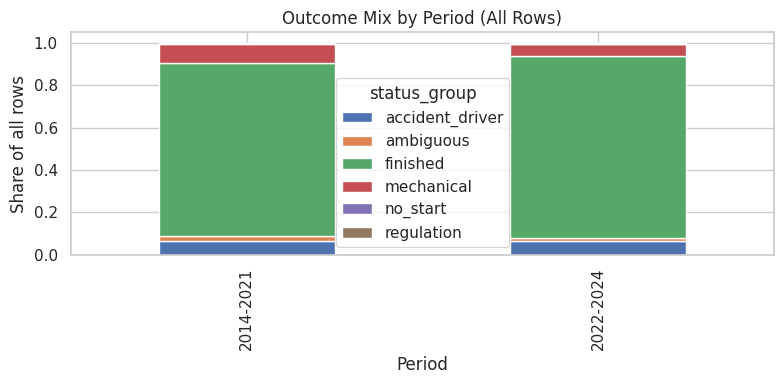

League-wide mechanical-retirement rate:
{'2014-2021': 0.0921, '2022-2024': 0.0569}


In [133]:
for period in ["2014-2021", "2022-2024"]:
    s = strict[
        (strict.period == period) & (strict.starts >= MIN_STARTS)
    ].set_index("team")["rate"]

    b = broad[
        (broad.period == period) & (broad.starts >= MIN_STARTS)
    ].set_index("team")["rate"]

    # Compare only teams included in both sets of results.
    common = s.index.intersection(b.index)

    correlation = spearmanr(s.loc[common], b.loc[common]).correlation

    print(
        period,
        "Spearman strict vs broad:",
        round(correlation, 2)
    )


# 2. Visualize the share of each status group in each period.
# Note: This chart uses all rows in d3, including no-start entries.

comp = pd.crosstab(
    d3["period"],
    d3["status_group"],
    normalize="index"
)

comp.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 4),
    title="Outcome Mix by Period (All Rows)"
)

plt.ylabel("Share of all rows")
plt.xlabel("Period")
plt.tight_layout()
savefig("05_q3_status_mix")


# 3. Calculate the league-wide mechanical-retirement rate.
# Sum mechanical retirements and race starts across all teams in each period.
# Rate = total mechanical retirements / total race starts.

league_totals = (
    strict.groupby("period")[["mech", "starts"]]
    .sum()
)

league_rates = (
    league_totals["mech"] / league_totals["starts"]
).round(4)

print("League-wide mechanical-retirement rate:")
print(league_rates.to_dict())


## Data Preparation and Feature Engineering



### Code Summary — Prepare Qualifying Times and Home Flag

- **Import libraries:** Load machine-learning models, preprocessing tools, and evaluation metrics for later modeling.
- **Prepare qualifying times (`qt`):** Sort qualifying records, keep one record per driver per race, and select Q1, Q2, and Q3 times.
- **Merge data (`mt_raw`):** Add qualifying times to the main dataset using `raceId` and `driverId`, keeping all original rows.
- **Validate the merge:** Check that the number of rows remains unchanged and no race-driver combination is duplicated.
- **Map driver nationality:** Use `NAT2COUNTRY` to convert each driver's nationality into a country.
- **Create the home flag:** `1` = driver racing in their country; `0` = driver racing outside their country; `NaN` = country unknown.
- **Print dataset information:** Show the dataset dimensions and the proportion of rows with a known home flag.

**Purpose:** Prepare the F1 dataset with qualifying-time features and a home-race indicator for later analysis and machine-learning models.

In [134]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

# qualifying times (q1/q2/q3 in seconds, cleaned in Objective 1)
qt = (CL["qualifying"].sort_values(["raceId","driverId","qualifyId"])
      .drop_duplicates(["raceId","driverId"])[["raceId","driverId","q1_s","q2_s","q3_s"]])

mt_raw = df.merge(qt, on=["raceId","driverId"], how="left", validate="m:1")
assert len(mt_raw) == len(df) and not mt_raw.duplicated(["raceId","driverId"]).any()

# home flag: NaN (unknown) when nationality can't be mapped, so unknown is not treated as "away"
drv_country = mt_raw.nationality.map(NAT2COUNTRY)
mt_raw["home"] = np.where(drv_country.notna(), (drv_country == mt_raw.circuit_country).astype(float), np.nan)
print(mt_raw.shape, "| home known for", round(mt_raw.home.notna().mean(), 3), "of rows")

(26287, 36) | home known for 1.0 of rows


### Code Summary — Create Train, Validation, and Test Splits

- **Assign data splits:** Use seasons up to 2019 for training, 2020–2021 for validation, and 2022 onward for testing.
- **Summarize each split (`sz`):** Calculate the number of rows, number of unique races, first and last season, and podium rate for each split.
- **Calculate yearly podium rates (`rate`):** For each season, calculate the proportion of drivers who finished in the top three.
- **Assign colors:** Blue = training, orange = validation, green = testing.
- **Plot the results:** Create a bar chart showing the podium rate for each season, with colors indicating its data split.
- **Save the plot:** Save the chart as `06_split`.

**Purpose:** Verify the chronological train/validation/test split and compare podium rates across seasons to identify potential differences between the datasets.

,rows,races,first_year,last_year,podium_rate
split,,,,,
train,23308,965,1950,2017,0.125
val,1620,81,2018,2021,0.150
test,1359,68,2022,2024,0.150


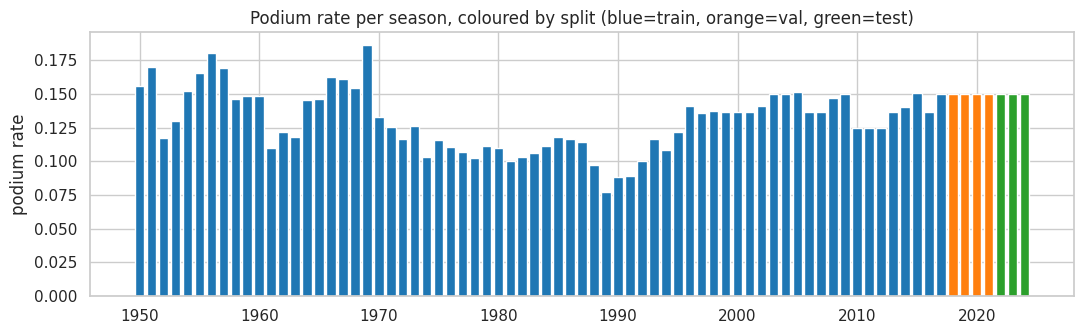

In [135]:
mt_raw["split"] = np.select([mt_raw.year <= 2017, mt_raw.year.between(2018, 2021)], ["train","val"], default="test")

sz = (mt_raw.groupby("split").agg(rows=("raceId","size"), races=("raceId","nunique"),
      first_year=("year","min"), last_year=("year","max"), podium_rate=("positionOrder", lambda s: (s <= 3).mean()))
      .loc[["train","val","test"]])
display(sz.round(3))

rate = mt_raw.assign(p=(mt_raw.positionOrder <= 3)).groupby("year").p.mean()
col = {"train":"tab:blue","val":"tab:orange","test":"tab:green"}
spl = mt_raw.groupby("year").split.first()
plt.figure(figsize=(11,3.5)); plt.bar(rate.index, rate.values, color=[col[s] for s in spl.loc[rate.index]])
plt.title("Podium rate per season, coloured by split (blue=train, orange=val, green=test)"); plt.ylabel("podium rate")
savefig("06_split")

### Code Summary — Audit Features for Data Leakage

- **Define forbidden features (`FORBIDDEN`):** List columns that must not be used as prediction inputs because they contain race outcomes or information unavailable before the race starts.
- **Create the feature audit table (`audit`):** Record each data feature, its source table, whether it is allowed at the prediction cutoff, and the reason.
- **Identify allowed features:** Use information available before the race, such as starting grid position, qualifying times, driver nationality, circuit country, and race calendar information.
- **Exclude race outcomes:** Remove finishing positions, points earned in the race, laps completed, race times, fastest-lap information, and podium labels from the input features.
- **Handle retirement information carefully:** Current-race status cannot be used to predict the same race because it reveals how the race ended. Status from previous races may be used if constructed correctly.
- **Handle standings carefully:** Stored driver and constructor standings are usually updated after a race. Rebuild them using only previous races if they are needed as pre-race features.
- **Review sprint results:** Sprint results can affect the Sunday starting grid in some seasons, but the grid already captures that information in this project. Sprint results are excluded to keep the feature set simple and consistent.

**Purpose:** Prevent data leakage by ensuring the model uses only information available before the race starts, so its evaluation reflects realistic podium prediction.

In [136]:
FORBIDDEN = ["positionOrder","position","positionText","points","laps","time","milliseconds","fastestLap","rank",
             "fastestLapTime","fastestLapTime_s","fastestLapSpeed","statusId","status","finished","mech_dnf","podium"]
audit = pd.DataFrame([
 ("grid", "results", "YES", "fixed after qualifying and penalties, before the start"),
 ("quali_pos, q1_s, q2_s, q3_s", "qualifying", "YES", "session finished before the race"),
 ("nationality, circuit country", "drivers, circuits", "YES", "known from the entry list and calendar"),
 ("round, field entries", "races, results", "YES", "calendar and entry list"),
 ("positionOrder, position, positionText", "results", "NO", "is the target or a restatement of it"),
 ("points, laps, time, milliseconds, fastestLap*", "results", "NO", "race outcomes"),
 ("status / statusId", "results, status", "NO for this race", "why the race ended; usable only for PAST races"),
 ("pit_stops, lap_times", "pit_stops, lap_times", "NO", "recorded during the race"),
 ("driver_standings / constructor_standings", "standings", "NO as stored", "values are AFTER the race; rebuilt as 'before' from past points"),
 ("sprint_results", "sprint_results", "judgement call", "2021-22 sprint set the Sunday grid, but it is already in grid; excluded to stay simple and consistent"),
], columns=["data","table","allowed at cutoff?","reason"])
display(audit)

,data,table,allowed at cutoff?,reason
0,grid,results,YES,"fixed after qualifying and penalties, before t..."
1,"quali_pos, q1_s, q2_s, q3_s",qualifying,YES,session finished before the race
2,"nationality, circuit country","drivers, circuits",YES,known from the entry list and calendar
3,"round, field entries","races, results",YES,calendar and entry list
4,"positionOrder, position, positionText",results,NO,is the target or a restatement of it
5,"points, laps, time, milliseconds, fastestLap*",results,NO,race outcomes
6,status / statusId,"results, status",NO for this race,why the race ended; usable only for PAST races
7,"pit_stops, lap_times","pit_stops, lap_times",NO,recorded during the race
8,driver_standings / constructor_standings,standings,NO as stored,values are AFTER the race; rebuilt as 'before'...
9,sprint_results,sprint_results,judgement call,"2021-22 sprint set the Sunday grid, but it is ..."


### Code Summary — Feature Engineering Using Past Race Data

- **Group features (`FEATURE_GROUPS`):** Organize prediction features into six categories: grid, qualifying, driver form, constructor form, standings, and race context.

- **Select features (`FEATURES`):** Combine all feature groups into one list and check that no forbidden race-outcome features are included.

- **Create `add_features()`:** Build new prediction features from race data sorted chronologically by date, race, and driver.

- **Create helper labels:**
  - `podium`: 1 if the driver finished in the top 3, otherwise 0.
  - `finished`: 1 if the driver finished the race, otherwise 0.
  - `mech_dnf`: 1 if the driver retired because of a mechanical problem, otherwise 0.
  - These helper columns are used to calculate historical features, not as direct prediction inputs.

- **Grid features:**
  - `field_size`: Number of drivers listed in the race dataset for that race.
  - `is_pitlane`: 1 if the driver starts from the pit lane, otherwise 0.
  - `grid_eff`: Effective starting position, adjusted to place pit-lane starters behind the last grid position.
  - `rel_grid`: Effective grid position divided by field size.
  - `front_row`: 1 if the driver starts in the first two positions, otherwise 0.

- **Qualifying features:**
  - `quali_pos`: Driver's qualifying position.
  - `quali_missing`: 1 if qualifying position is missing, otherwise 0.
  - `grid_minus_quali`: Effective grid position minus qualifying position. A positive value can indicate the driver started further back than their qualifying position.
  - `q1_gap_pct`: Percentage by which the driver's Q1 time is slower than the fastest Q1 time in that race.

- **Driver-form features:**
  - `drv_podium_rate`: Driver's podium rate over their previous five race entries.
  - `drv_avg_finish`: Driver's average finishing position over their previous five race entries.
  - `drv_dnf_rate`: Driver's rate of not finishing over their previous five race entries.
  - `drv_races_before`: Number of previous race entries for the driver in the dataset.
  - `drv_career_podium_rate`: Driver's podium rate across all their previous race entries.

- **Constructor-form features:**
  - `con_podium_rate`: Constructor's average podium rate over its previous five race entries, using the team's results aggregated by race.
  - `con_avg_finish`: Constructor's average finishing position over its previous five race entries.
  - `con_mech_dnf_rate`: Constructor's mechanical-retirement rate over its previous ten race entries.
  - `con_pts_before`: Constructor's total points earned earlier in the current season, before the current race.

- **Standings features:**
  - `drv_pts_before`: Driver's total points earned earlier in the current season, before the current race.
  - `drv_pts_rel`: Driver's pre-race points divided by the highest driver's pre-race points in that race's field.
  - `drv_rank_before`: Driver's rank based on points earned before the current race.
  - `con_pts_rel`: Constructor's pre-race points divided by the highest constructor's pre-race points in that race's field.

- **Race-context features:**
  - `round`: Race number within the season.
  - `home`: Indicator for whether the driver's nationality matches the circuit's country, as defined by the existing code.
  - `field_size`: Number of drivers listed for the race. This feature is also included in the grid group.

- **Prevent data leakage:** Use `shift(1)` so historical rolling calculations exclude the current race. Rebuild standings from earlier race points instead of using post-race standings.

- **Merge and validate:** Merge constructor features into the driver-race dataset and check that no race-driver combinations are duplicated and the number of rows remains unchanged.

- **Inspect the features:** Print the dataset dimensions and descriptive statistics for the selected features.

- **Run feature engineering (`d = add_features(mt_raw)`):** Apply the function to the original dataset and save the updated dataset, containing the original columns plus the calculated features, in `d`.

**Purpose:** Create meaningful pre-race features from grid position, qualifying performance, past driver and constructor performance, standings, and race context to predict whether a driver will finish on the podium.

In [137]:
FEATURE_GROUPS = {
 "grid":             ["grid_eff","is_pitlane","rel_grid","front_row"],
 "qualifying":       ["quali_pos","quali_missing","grid_minus_quali","q1_gap_pct"],
 "driver_form":      ["drv_podium_rate","drv_avg_finish","drv_dnf_rate","drv_races_before","drv_career_podium_rate"],
 "constructor_form": ["con_podium_rate","con_avg_finish","con_mech_dnf_rate"],
 "standings":        ["drv_pts_rel","drv_rank_before","con_pts_rel"],
 "context":          ["field_size","round","home"],
}
FEATURES = [c for g in FEATURE_GROUPS.values() for c in g]
assert not set(FORBIDDEN) & set(FEATURES)

def add_features(raw, w_drv=5, w_con=5, w_mech=10):
    d = raw.sort_values(["date","raceId","driverId"]).reset_index(drop=True).copy()
    # row-level helpers: only ever used through shift(1) below
    d["podium"]   = (d.positionOrder <= 3).astype(int)
    d["finished"] = (d.status.eq("Finished") | d.status.str.startswith("+", na=False)).astype(int)
    d["mech_dnf"] = (d.status.map(classify) == "mechanical").astype(int)
    roll = lambda s, n: s.shift(1).rolling(n, min_periods=1).mean()     # shift(1): current race never included

    # --- grid group
    d["field_size"] = d.groupby("raceId").driverId.transform("size")
    d["is_pitlane"] = (d.grid == 0).astype(int)
    d["grid_eff"]   = d.grid.where(d.grid > 0, d.field_size + 1)        # pit-lane start = one slot behind the last car
    d["rel_grid"]   = d.grid_eff / d.field_size
    d["front_row"]  = (d.grid_eff <= 2).astype(int)

    # --- qualifying group
    d["quali_missing"]    = d.quali_pos.isna().astype(int)
    d["grid_minus_quali"] = d.grid_eff - d.quali_pos                    # >0: pushed back by penalty
    d["q1_gap_pct"]       = (d.q1_s / d.groupby("raceId").q1_s.transform("min") - 1) * 100

    # --- driver form (past races only)
    g = d.groupby("driverId", sort=False)
    d["drv_podium_rate"]        = g.podium.transform(lambda s: roll(s, w_drv))
    d["drv_avg_finish"]         = g.positionOrder.transform(lambda s: roll(s, w_drv))
    d["drv_dnf_rate"]           = g.finished.transform(lambda s: 1 - roll(s, w_drv))
    d["drv_races_before"]       = g.cumcount()
    d["drv_career_podium_rate"] = g.podium.transform(lambda s: s.shift(1).expanding().mean())

    # --- constructor form: aggregate the team's cars per race FIRST, then roll over past races
    cr = (d.groupby(["constructorId","raceId"], as_index=False)
            .agg(date=("date","first"), year=("year","first"), c_podium=("podium","mean"),
                 c_finish=("positionOrder","mean"), c_mech=("mech_dnf","mean"), c_pts=("points","sum"))
            .sort_values(["constructorId","date","raceId"]))
    cg = cr.groupby("constructorId", sort=False)
    cr["con_podium_rate"]   = cg.c_podium.transform(lambda s: roll(s, w_con))
    cr["con_avg_finish"]    = cg.c_finish.transform(lambda s: roll(s, w_con))
    cr["con_mech_dnf_rate"] = cg.c_mech.transform(lambda s: roll(s, w_mech))
    cr["con_pts_before"]    = cr.groupby(["year","constructorId"]).c_pts.transform(lambda s: s.cumsum().shift(1)).fillna(0)
    d = d.merge(cr[["constructorId","raceId","con_podium_rate","con_avg_finish","con_mech_dnf_rate","con_pts_before"]],
                on=["constructorId","raceId"], how="left", validate="m:1")
    d = d.sort_values(["date","raceId","driverId"]).reset_index(drop=True)

    # --- standings BEFORE the race, rebuilt from past race points (the standings table is post-race)
    d["drv_pts_before"] = d.groupby(["year","driverId"]).points.transform(lambda s: s.cumsum().shift(1)).fillna(0)
    mx = d.groupby("raceId").drv_pts_before.transform("max")
    d["drv_pts_rel"]     = np.where(mx > 0, d.drv_pts_before / mx.replace(0, np.nan), 0.0)   # share of leader's points
    d["drv_rank_before"] = d.groupby("raceId").drv_pts_before.rank(ascending=False, method="min").where(mx > 0)
    cmx = d.groupby("raceId").con_pts_before.transform("max")
    d["con_pts_rel"]     = np.where(cmx > 0, d.con_pts_before / cmx.replace(0, np.nan), 0.0)
    return d

d = add_features(mt_raw)
assert not d.duplicated(["raceId","driverId"]).any() and len(d) == len(mt_raw)
print(d.shape)
display(d[FEATURES].describe().T.round(3))

(26287, 60)


,count,mean,std,min,25%,50%,75%,max
grid_eff,26287.0,12.994,8.137,1.000,6.000,12.000,18.000,40.000
is_pitlane,26287.0,0.062,0.242,0.000,0.000,0.000,0.000,1.000
rel_grid,26287.0,0.529,0.300,0.026,0.273,0.520,0.773,1.643
front_row,26287.0,0.084,0.278,0.000,0.000,0.000,0.000,1.000
quali_pos,10494.0,11.196,6.260,1.000,6.000,11.000,16.000,28.000
quali_missing,26287.0,0.601,0.490,0.000,0.000,1.000,1.000,1.000
grid_minus_quali,10494.0,0.024,1.584,-9.000,0.000,0.000,0.000,23.000
q1_gap_pct,10338.0,1.947,9.264,0.000,0.715,1.345,2.358,922.862
drv_podium_rate,25529.0,0.130,0.232,0.000,0.000,0.000,0.200,1.000
drv_avg_finish,25529.0,12.582,5.495,1.000,9.000,12.400,15.600,39.000


### Code Summary — Data Leakage Tests

- **Test 1 — First-race history:** Check that each driver's first race has a missing (`NaN`) historical podium rate because no previous race data is available.

- **Test 2 — Recalculate and compare:** Randomly select 300 rows and manually recalculate driver and constructor podium rates using the previous five races. Compare the manually calculated values with the existing features to check their correctness.

- **Select random rows:** Use `np.random.default_rng(42)` to select 300 different rows reproducibly, so the same sample can be tested again.

- **Check driver podium rate:** Calculate the mean of the driver's podium indicators from their previous five race entries and compare it with `drv_podium_rate`.

- **Check constructor podium rate:** Calculate the constructor's average podium indicator across its previous five races and compare it with `con_podium_rate`.

- **Test 3 — Change race outcomes:** Select one race and modify its finishing positions, points, and statuses. Recalculate the features using `add_features()` and check whether the selected race's features remain unchanged.

- **Check the results:** Use assertions to raise an error if a test fails. If all tests pass, print `"ALL LEAKAGE TESTS PASSED"`.

**Purpose:** Check that historical podium features are calculated correctly and that changing a race's outcomes does not change that race's pre-race prediction features, helping detect data leakage.

In [138]:
# Test 1: a driver's first race must have no history
assert d.groupby("driverId").head(1).drv_podium_rate.isna().all()

# Test 2: recompute features by brute force for random rows and compare
rng = np.random.default_rng(42)
for i in rng.choice(len(d), 300, replace=False):
    r = d.iloc[i]
    past = d[(d.driverId == r.driverId) & (d.date < r.date)].tail(5)
    exp = past.podium.mean() if len(past) else np.nan
    assert (np.isnan(exp) and np.isnan(r.drv_podium_rate)) or np.isclose(exp, r.drv_podium_rate)
    cp = d[(d.constructorId == r.constructorId) & (d.date < r.date)].groupby("raceId", sort=False).podium.mean().tail(5)
    expc = cp.mean() if len(cp) else np.nan
    assert (np.isnan(expc) and np.isnan(r.con_podium_rate)) or np.isclose(expc, r.con_podium_rate)

# Test 3 (strongest): rewrite one race's outcome. Features of THAT race must not change.
R = mt_raw.raceId.unique()[len(mt_raw.raceId.unique()) // 2]
m = mt_raw.copy(); k = m.raceId == R
m.loc[k, ["positionOrder","points"]] = [99, 0]; m.loc[k, "status"] = "Engine"
d2 = add_features(m); mask = d.raceId == R
pd.testing.assert_frame_equal(d.loc[mask, FEATURES], d2.loc[mask, FEATURES])
print("ALL LEAKAGE TESTS PASSED")

ALL LEAKAGE TESTS PASSED


### Code Summary — Exploratory Feature Analysis

- **Select training data (`tr`):** Keep only the training rows to analyze the features without using validation or test data.

- **Select qualifying-era data (`ev`):** Keep training rows from `Q_START` onward, when qualifying information is available more consistently.

- **5a — Univariate strength and coverage:** Evaluate each feature individually to see how well it distinguishes podium finishers from non-podium finishers.
  - `coverage`: Percentage of training rows with a non-missing value for the feature.
  - `univariate_auc`: Measures the feature's ability to distinguish podium outcomes; values closer to 1 indicate stronger separation after accounting for direction.
  - `spearman_vs_podium`: Measures the direction and strength of the feature's rank-based relationship with podium outcomes.
  - Display a table and bar chart ranking features by their individual predictive strength.

- **5b — Feature relationship shapes:** Divide six selected features into up to ten groups based on their values, then plot the average feature value against the podium rate in each group. This helps reveal whether higher or lower feature values are associated with more podium finishes.

- **5c — Missingness by season:** Calculate the proportion of missing values for each feature in each season and display a heatmap. This helps identify missing-data patterns and assess the need for missing-value indicators or imputation.

- **5d — Feature redundancy:** Calculate Spearman correlations between features and display a correlation heatmap. Identify pairs with an absolute correlation greater than 0.85, indicating that they may contain similar information.

**Purpose:** Understand which features have predictive signals, how their values relate to podium outcomes, how much data is missing, and whether some features are highly correlated before building the prediction models.

,group,feature,coverage,univariate_auc,spearman_vs_podium
4,qualifying,quali_pos,0.323,0.903,-0.482
0,grid,grid_eff,1.000,0.891,-0.448
2,grid,rel_grid,1.000,0.885,-0.441
17,standings,drv_rank_before,0.932,0.853,-0.404
13,constructor_form,con_podium_rate,0.988,0.831,0.416
7,qualifying,q1_gap_pct,0.317,0.828,-0.393
8,driver_form,drv_podium_rate,0.968,0.814,0.442
12,driver_form,drv_career_podium_rate,0.968,0.814,0.375
14,constructor_form,con_avg_finish,0.988,0.809,-0.355
9,driver_form,drv_avg_finish,0.968,0.806,-0.354


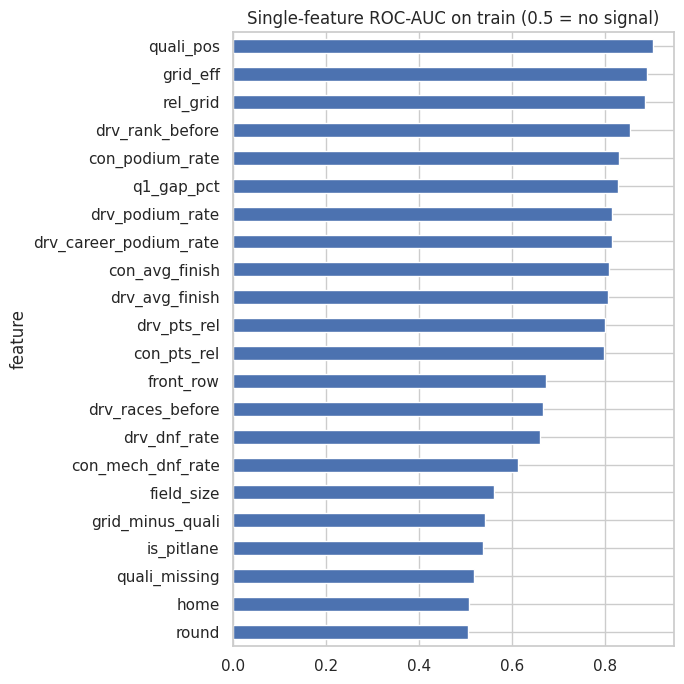

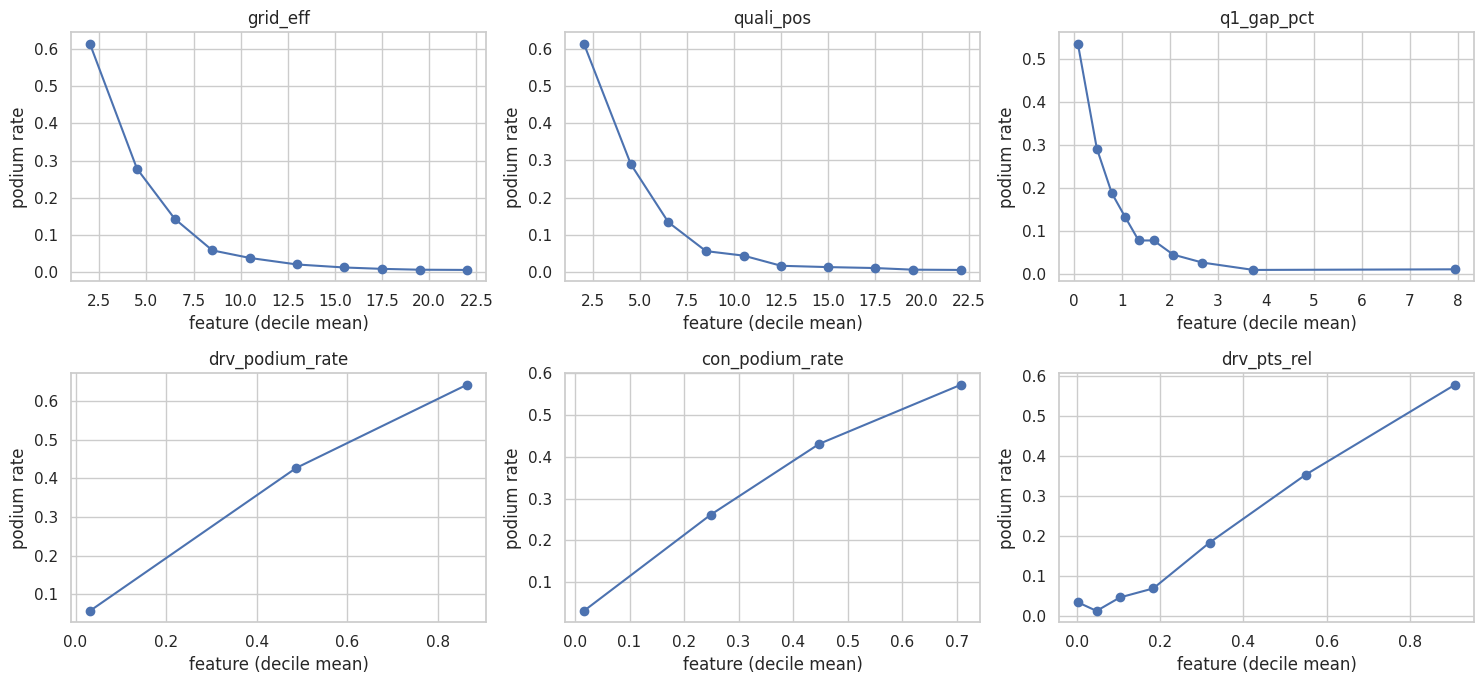

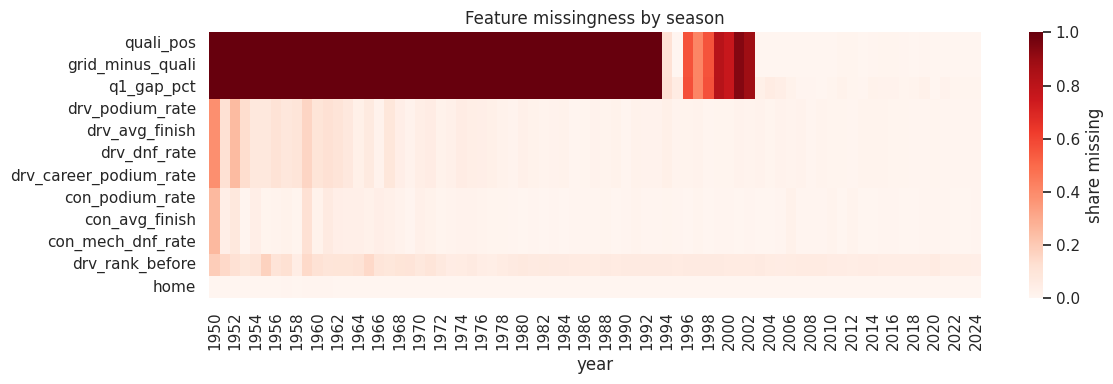

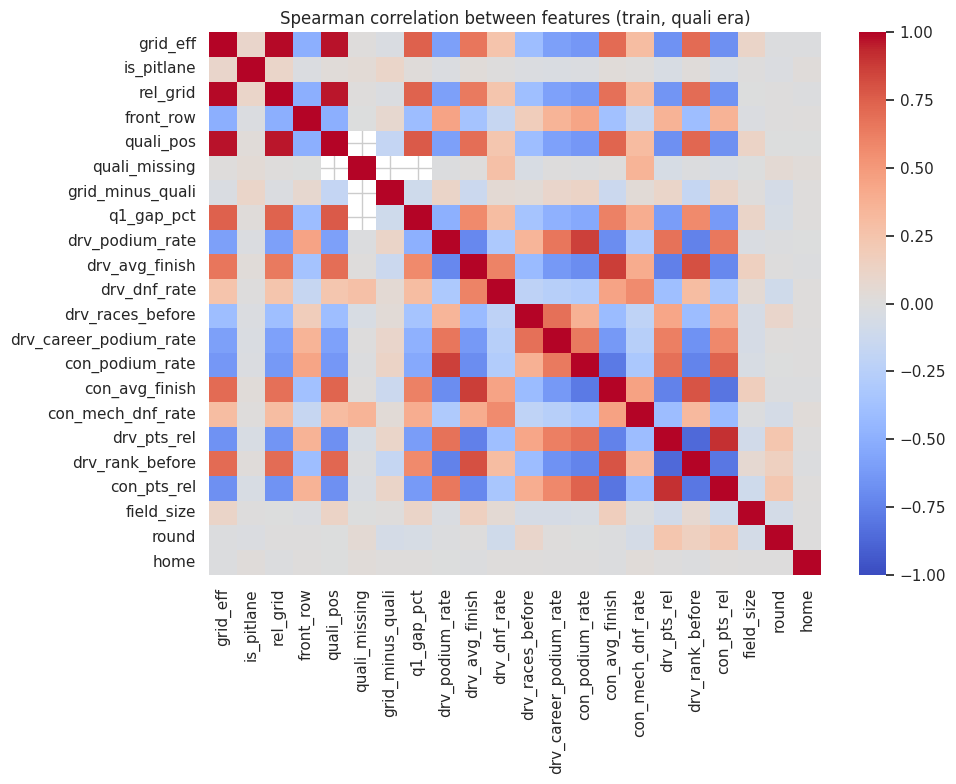

highly redundant pairs (|rho| > 0.85):


,feature_a,feature_b,rho
0,grid_eff,rel_grid,0.99
1,grid_eff,quali_pos,0.97
2,rel_grid,quali_pos,0.96
3,drv_podium_rate,con_podium_rate,0.86
4,drv_avg_finish,con_avg_finish,0.87
5,drv_pts_rel,drv_rank_before,-0.86
6,drv_pts_rel,con_pts_rel,0.91


In [139]:
tr = d[d.split == "train"]
ev = tr[tr.year >= Q_START]     # era where qualifying exists

# 5a. univariate strength + coverage
rows = []
for grp, cols in FEATURE_GROUPS.items():
    for f in cols:
        x = tr[[f, "podium"]].dropna()
        if x[f].nunique() > 1:
            a = roc_auc_score(x.podium, x[f])
            rows.append((grp, f, round(len(x)/len(tr), 3), round(max(a, 1-a), 3), round(x[f].corr(x.podium, method="spearman"), 3)))
uni = pd.DataFrame(rows, columns=["group","feature","coverage","univariate_auc","spearman_vs_podium"]).sort_values("univariate_auc", ascending=False)
display(uni)
uni.set_index("feature").univariate_auc.sort_values().plot(kind="barh", figsize=(7,7), title="Single-feature ROC-AUC on train (0.5 = no signal)")
savefig("06_univariate")

# 5b. shape of the relationship: podium rate by decile of the feature
plot_f = ["grid_eff","quali_pos","q1_gap_pct","drv_podium_rate","con_podium_rate","drv_pts_rel"]
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a_, f in zip(ax.ravel(), plot_f):
    x = ev[[f, "podium"]].dropna()
    b = pd.qcut(x[f], 10, duplicates="drop")
    g_ = x.groupby(b, observed=True).agg(feat=(f, "mean"), rate=("podium", "mean"))
    a_.plot(g_.feat, g_.rate, marker="o"); a_.set_title(f); a_.set_xlabel("feature (decile mean)"); a_.set_ylabel("podium rate")
savefig("06_feature_shapes")

# 5c. missingness by season: justifies flags and imputation
miss = d[[c for c in FEATURES if d[c].isna().any()]].isna().groupby(d.year).mean()
plt.figure(figsize=(12,4)); sns.heatmap(miss.T, cmap="Reds", vmin=0, vmax=1, cbar_kws={"label":"share missing"})
plt.title("Feature missingness by season"); savefig("06_missingness")

# 5d. redundancy
cm = ev[FEATURES].corr(method="spearman")
plt.figure(figsize=(10,8)); sns.heatmap(cm, cmap="coolwarm", center=0, vmin=-1, vmax=1); plt.title("Spearman correlation between features (train, quali era)")
savefig("06_feature_corr")
pairs = [(a, b, round(cm.loc[a, b], 2)) for i, a in enumerate(cm.index) for b in cm.columns[i+1:] if abs(cm.loc[a, b]) > 0.85]
print("highly redundant pairs (|rho| > 0.85):"); display(pd.DataFrame(pairs, columns=["feature_a","feature_b","rho"]))

## Predictive modeling tasks


### Code Summary — Quick Model Evaluation and Bootstrap Confidence Intervals

- **Define data splits (`split_of`):** Assign races from 2019 and earlier to training, 2020–2021 to validation, and 2022 onward to testing.

- **Create `quick_eval()`:** Train and evaluate simple, fixed machine learning models to compare different feature sets without changing model settings.

- **Select training data:** Use training rows from 1996 onward by default and use the validation set to evaluate model performance.

- **Train two models:**
  - `hgb`: Histogram-based Gradient Boosting, which learns nonlinear patterns and interactions between features.
  - `lr`: Logistic Regression, which provides a simpler, more linear baseline. Missing values are filled using the training median, and features are standardized.

- **Calculate PR-AUC (`*_pr`):** Measure how well the model identifies and ranks podium finishers, which are the minority class.

- **Calculate ROC-AUC (`*_roc`):** Measure how well the model distinguishes podium finishers from non-podium finishers.

- **Create `boot_pr()`:** Estimate a confidence interval for PR-AUC using bootstrap resampling. Randomly sample validation predictions with replacement 200 times and calculate PR-AUC for each sample.

- **Calculate the confidence interval:** Return the 2.5th and 97.5th percentiles of the bootstrap scores, giving an approximate 95% interval for PR-AUC.

**Purpose:** Compare feature sets using consistent model settings and estimate the uncertainty in PR-AUC, helping determine whether a feature set performs well on validation data.

In [140]:
def split_of(d): return np.select([d.year <= 2017, d.year.between(2018, 2021)], ["train","val"], default="test")

def quick_eval(d, feats, start=1996, models=("hgb","lr")):
    # fixed, deliberately simple models so differences come from the FEATURES, not from tuning
    trn = d[(d.split == "train") & (d.year >= start)]; val = d[d.split == "val"]; out = {}
    for m in models:
        mdl = (HistGradientBoostingClassifier(max_iter=200, learning_rate=.05, max_depth=3, early_stopping=False, random_state=42)
               if m == "hgb" else make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=3000)))
        mdl.fit(trn[feats], trn.podium); p = mdl.predict_proba(val[feats])[:, 1]
        out[f"{m}_pr"], out[f"{m}_roc"] = average_precision_score(val.podium, p), roc_auc_score(val.podium, p)
    return out

def boot_pr(y, p, n=200):
    r = np.random.default_rng(0); y, p = np.asarray(y), np.asarray(p); s = []
    for _ in range(n):
        i = r.integers(0, len(y), len(y)); s.append(average_precision_score(y[i], p[i]))
    return np.percentile(s, [2.5, 97.5])

## Feature Group Buildup Analysis

- **Feature group order:** Defines the order in which grid, qualifying, driver form, constructor form, standings, and context features are added.

- **`rows, cur = [], []`:** Creates an empty list to store results and another to collect the features added so far.

- **Feature accumulation:** Adds one feature group at a time while keeping all previously added groups.

- **`quick_eval(d, cur)`:** Trains and evaluates Histogram Gradient Boosting (HGB) and Logistic Regression (LR) using the accumulated features. It calculates validation PR-AUC and ROC-AUC for both models.

- **Store results:** Records the newly added feature group, total number of features, and evaluation scores for each step.

- **Create results table:** Converts the collected results into a DataFrame and displays the scores rounded to four decimal places.

- **Plot validation PR-AUC:** Draws a graph showing how HGB and LR performance changes as more feature groups are added.

- **Save the graph:** Saves the plot as `06_E1_buildup`.

**Purpose:** Determine how adding different feature groups affects the models' ability to predict F1 podium finishes and identify which groups improve validation performance.

**Note:** The active code does not calculate the bootstrap confidence interval shown in the commented-out section. It also does not complete all Part 4 requirements, such as neural network evaluation, F1 scores, training metrics, and final test evaluation.

,hgb_pr,hgb_roc,lr_pr,lr_roc,n_features
added_group,,,,,
grid,0.6683,0.9179,0.6684,0.9178,4
qualifying,0.6877,0.9281,0.7060,0.9251,8
driver_form,0.7016,0.9339,0.7170,0.9322,13
constructor_form,0.6942,0.9367,0.7180,0.9338,16
standings,0.6953,0.9377,0.7176,0.9340,19
context,0.6955,0.9369,0.7163,0.9340,22


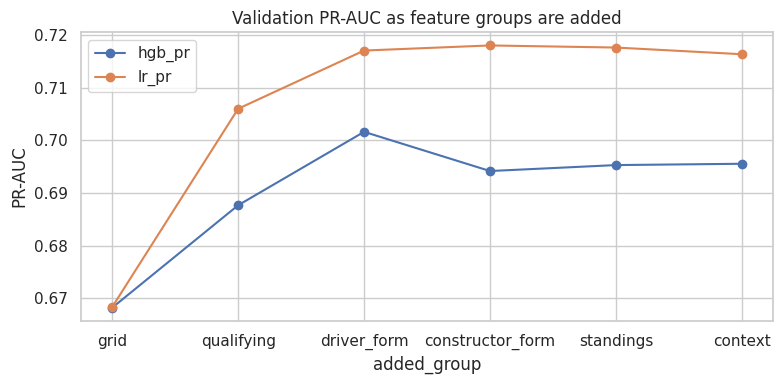

In [141]:

order = ["grid", "qualifying", "driver_form", "constructor_form", "standings", "context"]
rows, cur = [], []

for g in order:
    cur = cur + FEATURE_GROUPS[g]
    r = quick_eval(d, cur)
    r["added_group"], r["n_features"] = g, len(cur)
    rows.append(r)

E1 = pd.DataFrame(rows).set_index("added_group")
display(E1.round(4))

E1[["hgb_pr", "lr_pr"]].plot(
    marker="o",
    figsize=(8,4),
    title="Validation PR-AUC as feature groups are added"
)
plt.ylabel("PR-AUC")
savefig("06_E1_buildup")

## E2 – Testing Different Form Windows

**Purpose:** To determine how many previous races should be used to calculate driver and constructor form features.

- **`rows = []`**: Creates an empty list to store experiment results.
- **`for w in [3, 5, 10, 20]`**: Tests four window sizes: the previous 3, 5, 10, and 20 races.
- **`add_features(mt_raw, w_drv=w, w_con=w)`**: Creates driver-form and constructor-form features using the selected window size.
- **`dw["split"] = split_of(dw)`**: Assigns rows to the training, validation, and test sets.
- **`quick_eval(dw, FEATURES)`**: Trains two models (HGB and LR) and evaluates their validation PR-AUC and ROC-AUC scores.
- **`r["window"] = w; rows.append(r)`**: Stores the window size and its evaluation results.
- **`pd.DataFrame(rows).set_index("window")`**: Converts the results into a table, with each window size as a row.
- **`E2[["hgb_pr", "lr_pr"]].plot(...)`**: Plots validation PR-AUC against the window size for both models.
- **`savefig("06_E2_window")`**: Saves the resulting graph.

**Training:** The models are trained inside `quick_eval()` using `.fit()`. Since there are four window sizes and two models, the experiment performs **8 model fits**.

**Interpretation:** The experiment identifies which window size gives the best validation performance. A shorter window reflects recent performance, while a longer window includes more historical results. More races do not necessarily produce better predictions.

**Project requirement:** Supports feature-engineering and preprocessing experiments by testing the effect of different historical form windows on model performance.



Window = 10: HGB PR-AUC = 0.7058, LR PR-AUC = 0.7234. Both models achieve their highest PR-AUC scores, indicating that using the previous 10 races gives the best results for identifying podium finishers.

,hgb_pr,hgb_roc,lr_pr,lr_roc
window,,,,
3,0.7021,0.9365,0.7149,0.9335
5,0.6955,0.9369,0.7163,0.9340
10,0.7058,0.9388,0.7234,0.9366
20,0.7047,0.9382,0.7229,0.9374


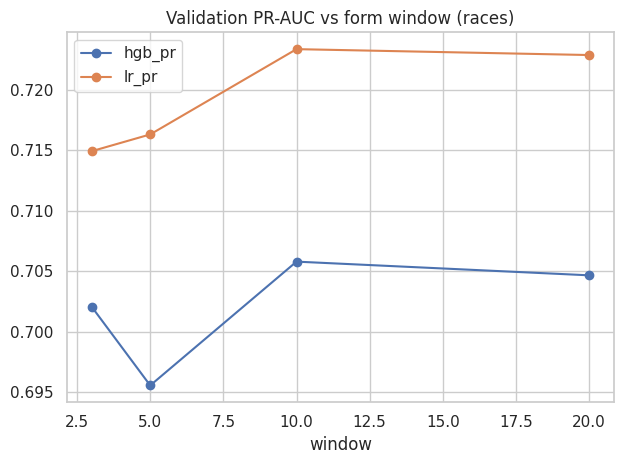

In [142]:
rows = []
for w in [3, 5, 10, 20]:
    dw = add_features(mt_raw, w_drv=w, w_con=w); dw["split"] = split_of(dw)
    r = quick_eval(dw, FEATURES); r["window"] = w; rows.append(r)
E2 = pd.DataFrame(rows).set_index("window"); display(E2.round(4))
E2[["hgb_pr","lr_pr"]].plot(marker="o", title="Validation PR-AUC vs form window (races)"); savefig("06_E2_window")

## E3 – Qualifying Feature Preprocessing Experiment

**Purpose:** Test how different ways of handling missing qualifying information affect model performance.

- **Create alternative dataset (`dB`)**:
  - Copy the original dataset.
  - Replace missing `quali_pos` values with `grid_eff`.
    - Reason: If qualifying is missing, use the actual starting position as an approximate indicator of performance.
  - Replace missing `grid_minus_quali` values with `0`.
    - Reason: If qualifying position is unavailable, assume there was no known grid penalty difference.

- **Experiment A — Keep missing values + missing flags**
  - Uses the original feature set.
  - Missing qualifying values remain as `NaN`.
  - The model pipeline handles missing values using imputation.
  - The `quali_missing` feature tells the model that the qualifying information was unavailable.

- **Experiment B — Fill missing qualifying values**
  - Uses the modified dataset `dB`.
  - Missing qualifying positions are replaced using grid position.
  - Tests whether manually filling missing values improves prediction.

- **Experiment C — Remove qualifying features**
  - Removes all qualifying-related features:
    - `quali_pos`
    - `quali_missing`
    - `grid_minus_quali`
    - `q1_gap_pct`
  - Tests how much predictive power comes from qualifying information.

- **`quick_eval()`**
  - Trains and evaluates HGB and Logistic Regression for each experiment.
  - Calculates validation PR-AUC and ROC-AUC.

- **Create results table (`E3`)**
  - Compares the three preprocessing approaches.

**Purpose in the project:**  
This experiment justifies the handling of missing qualifying data and shows whether qualifying information contributes meaningful predictive value. It satisfies the requirement to report preprocessing-order/feature-engineering experiments before selecting the final feature pipeline.

**Expected interpretation:**
- If A performs best → keeping missing values with a missing indicator is the most reliable approach.
- If B performs best → filling missing qualifying values improves prediction.
- If C performs much worse → qualifying features provide important information for podium prediction.

In [143]:
dB = d.copy(); dB["quali_pos"] = dB.quali_pos.fillna(dB.grid_eff); dB["grid_minus_quali"] = dB.grid_minus_quali.fillna(0)
no_q = [f for f in FEATURES if f not in FEATURE_GROUPS["qualifying"]]
E3 = pd.DataFrame({
  "A: keep NaN + missing flag (imputed in the pipeline)": quick_eval(d, FEATURES),
  "B: fill quali_pos with grid, no gap fill":             quick_eval(dB, FEATURES),
  "C: drop all qualifying features":                      quick_eval(d, no_q)}).T
display(E3.round(4))

,hgb_pr,hgb_roc,lr_pr,lr_roc
A: keep NaN + missing flag (imputed in the pipeline),0.6955,0.9369,0.7163,0.9340
"B: fill quali_pos with grid, no gap fill",0.6933,0.9367,0.7166,0.9340
C: drop all qualifying features,0.6910,0.9362,0.7162,0.9331


## E4 – Testing Different Training Start Years

**Purpose:** To determine which starting year for the training data gives the best validation performance.

- **`rows = []`**: Creates an empty list to store the results.
- **`for s in [1950, 1980, 1996, 2003]`**: Tests four different training start years: 1950, 1980, 1996, and 2003.
- **`quick_eval(d, FEATURES, start=s)`**: Trains HGB and Logistic Regression using training data from the selected start year onward, then evaluates their PR-AUC and ROC-AUC on the validation set.
- **`r["train_start"] = s`**: Stores the starting year alongside the evaluation results.
- **`r["n_train"] = int(((d.split == "train") & (d.year >= s)).sum())`**: Counts the training rows available from that starting year onward.
- **`rows.append(r)`**: Adds the results to the list.
- **`pd.DataFrame(rows).set_index("train_start")`**: Combines the results into a table indexed by the training start year.
- **`display(E4.round(4))`**: Displays the results rounded to four decimal places.

**Training:** The models are retrained for each of the four starting years. Since two models are evaluated each time, this experiment performs **8 model fits**.

**Interpretation:** Starting earlier provides more training data but includes older F1 seasons. Starting later provides less data but may better reflect modern F1 conditions. Compare the validation scores and `n_train` to determine the most suitable training period.

**Project requirement:** Supports the preprocessing and modeling experiments by investigating how the training period affects prediction performance. The validation set is used for comparison; the test set should remain untouched until final evaluation.

In [144]:
rows = []
for s in [1950, 1980, 1996, 2003]:
    r = quick_eval(d, FEATURES, start=s); r["train_start"] = s
    r["n_train"] = int(((d.split == "train") & (d.year >= s)).sum()); rows.append(r)
E4 = pd.DataFrame(rows).set_index("train_start"); display(E4.round(4))

,hgb_pr,hgb_roc,lr_pr,lr_roc,n_train
train_start,,,,,
1950,0.7037,0.9369,0.7163,0.9336,23308
1980,0.6995,0.9373,0.7175,0.9338,15853
1996,0.6955,0.9369,0.7163,0.9340,8517
2003,0.7087,0.9390,0.7209,0.9342,5991


## E5 – Testing Different Transformations of Grid Position

**Purpose:** To determine whether transforming grid position using a logarithm improves Logistic Regression's prediction performance.

- **`d["log_grid"] = np.log(d.grid_eff)`**: Creates a new feature by applying the natural logarithm to `grid_eff`. This changes the scale of the grid-position values.
- **Experiment A — `grid_eff (raw)`**:
  - Uses the original grid-position feature.
  - Tests Logistic Regression using `grid_eff` without transformation.
- **Experiment B — `log(grid_eff)`**:
  - Uses only the logarithm-transformed grid position.
  - Tests whether the transformed feature improves prediction performance.
- **Experiment C — `both`**:
  - Uses both the original and logarithm-transformed grid-position features.
  - Tests whether combining both versions provides additional useful information.
- **`quick_eval(d, ..., models=("lr",))`**: Trains Logistic Regression for each experiment and calculates validation PR-AUC and ROC-AUC.
- **`pd.DataFrame(...).T`**: Combines the three experiments into a comparison table, with each experiment as a row.
- **`display(E5.round(4))`**: Displays the results rounded to four decimal places.

**Training:** Logistic Regression is trained three times, once for each feature configuration. Each model is evaluated on the same validation set.

**Interpretation:**
- If `log(grid_eff)` performs better than raw `grid_eff`, the transformation may help Logistic Regression learn the relationship between starting position and podium probability.
- If `grid_eff (raw)` performs better, the original feature works better without transformation.
- If `both` performs best, using both versions may provide additional predictive information.

**Important:** Grid positions must be positive for the logarithm to be defined. If `grid_eff` contains zero or negative values, the transformation needs to be adjusted before running this experiment.

**Project requirement:** Supports feature-engineering and preprocessing experiments by comparing raw, transformed, and combined feature representations.

In [145]:
d["log_grid"] = np.log(d.grid_eff)
E5 = pd.DataFrame({"grid_eff (raw)": quick_eval(d, ["grid_eff"], models=("lr",)),
                   "log(grid_eff)": quick_eval(d, ["log_grid"], models=("lr",)),
                   "both":          quick_eval(d, ["grid_eff","log_grid"], models=("lr",))}).T
display(E5.round(4))

,lr_pr,lr_roc
grid_eff (raw),0.6684,0.9178
log(grid_eff),0.6684,0.9178
both,0.6684,0.9178


# Summary of Feature Engineering and Preprocessing Experiments

 ## E1 – Feature Group Buildup

Adding features was generally beneficial, especially when adding qualifying and driver-form information. Both HGB and Logistic Regression improved as these feature groups were introduced. HGB achieved its best PR-AUC of 0.7016 after adding driver form, while Logistic Regression achieved its best PR-AUC of 0.7180 after adding constructor form. However, adding standings and context did not consistently improve performance. Overall, the experiment shows that **gradually adding relevant feature groups is a useful approach, but the best feature set depends on the model**. Including more features is not always better, so the final feature set should be selected based on validation performance.

## E2 – Form Window Selection

A window of 10 previous races achieved the highest PR-AUC for both HGB (0.7058) and Logistic Regression (0.7234). This suggests that using 10 races provides a useful balance between recent performance and longer-term form. Using 20 races did not improve PR-AUC further.

## E3 – Handling Missing Qualifying Data

Keeping missing qualifying values with a missing indicator produced the best HGB PR-AUC (0.6955). Filling missing qualifying positions using grid position produced similar results, while removing qualifying features reduced HGB PR-AUC to 0.6910. Therefore, qualifying information provides useful predictive value, and keeping missingness information is a reasonable preprocessing choice.

## E4 – Training Start Year

Starting training in 2003 produced the highest validation PR-AUC for both HGB (0.7087) and Logistic Regression (0.7209). However, this setting used only 5,991 training rows, compared with 23,308 rows when training started in 1950. Although the more recent data achieved better validation scores, starting in 1950 provides a much larger historical dataset and allows the model to learn from more F1 seasons.

Since the project aims to use historical F1 data, I prefer to retain an earlier training start year rather than automatically choosing 2003 based only on validation performance. The final starting year should balance predictive performance with historical coverage. I will compare the results and document this trade-off when selecting the final model.

## E5 – Grid Position Transformation

This experiment compares raw grid position, logarithm-transformed grid position, and both features together. The results showed no difference.


## Overall Conclusion

The experiments show that podium prediction benefits from relevant qualifying information and historical driver performance. Gradually adding feature groups improved validation performance, particularly when qualifying and driver-form features were introduced. However, adding more features did not always improve results, so the final feature set should be selected based on validation performance.

A 10-race form window achieved the highest PR-AUC for both HGB and Logistic Regression in E2. In E4, starting training in 2003 produced the highest validation PR-AUC, but this involved using fewer training examples. Since the project aims to make use of historical F1 data, I prefer to retain an earlier training start year to include more seasons, while acknowledging that more historical data does not necessarily lead to better predictions.

For the final model, I will use the experiments to guide feature selection and preprocessing decisions, while balancing predictive performance with historical coverage. All features will use only information available before each race to prevent data leakage. Finally, the selected model will be evaluated on the untouched test set covering 2022 onward to assess its ability to predict podium finishes in later F1 seasons.

## M1 – Same Rows and Features for Every Model

This experiment ensures that all models use the same training, validation, and test datasets and the same features, making the comparison fair.

- **Training set:** Used to train the models, starting from 1980.
- **Validation set:** Used to compare models and select the best probability threshold for the F1-score.
- **Test set:** Used for the final evaluation on later races.

The features (`X`) contain the information used to predict podium finishes, while the target (`y`) indicates whether a driver finished in the top three.

A shared scoring function evaluates each model using three metrics:

- **ROC-AUC:** Measures how well the model ranks podium drivers above non-podium drivers.
- **PR-AUC:** Measures how well the model identifies podium drivers, which are the minority class.
- **F1-score:** Balances precision and recall using a probability threshold selected on the validation set.

Overall, this approach ensures a consistent and fair comparison between models. The test set remains separate from model training and threshold selection, providing an unbiased final evaluation.

In [146]:
# PART 4 - M1: SAME ROWS AND FEATURES FOR EVERY MODEL, PLUS ONE SCORING FUNCTION
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_recall_curve

TRAIN_START = 1980            # replace with the value you choose from E4
TARGET = "podium"

trn = d[(d.split == "train") & (d.year >= TRAIN_START)]
val = d[d.split == "val"]
tst = d[d.split == "test"]

X = {"train": trn[FEATURES], "val": val[FEATURES], "test": tst[FEATURES]}
y = {"train": trn[TARGET],   "val": val[TARGET],   "test": tst[TARGET]}
print({s: (len(X[s]), round(y[s].mean(), 3)) for s in X})     # rows and podium rate

def best_threshold(y_true, p):
    # the probability cut-off that gives the best F1 (computed on VALIDATION only)
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[np.argmax(f1[:-1])])

RESULTS = {}
def score(model, name, splits=("train", "val")):
    thr = best_threshold(y["val"], model.predict_proba(X["val"])[:, 1])   # threshold from val only
    rows = []
    for s in splits:
        p = model.predict_proba(X[s])[:, 1]
        rows.append(dict(model=name, split=s, roc_auc=roc_auc_score(y[s], p),
                         pr_auc=average_precision_score(y[s], p),
                         f1=f1_score(y[s], p >= thr), threshold=thr))
    RESULTS[name] = pd.DataFrame(rows)
    return RESULTS[name].round(4)

{'train': (15853, np.float64(0.123)), 'val': (1620, np.float64(0.15)), 'test': (1359, np.float64(0.15))}


## M4a – Clipping and Log Transformation for Logistic Regression and Neural Network

This code preprocesses the `q1_gap_pct` feature before it is used by Logistic Regression and the Neural Network.

**Purpose:** Reduce the effect of extreme values and make the feature easier for the models to learn from.

### 1. Create the `ClipLogQ1` transformer

- `fit()`: Finds the 99th percentile of `q1_gap_pct` using the training data only. This value becomes the maximum allowed value (`cap_`).
- `transform()`: Clips values to the range from 0 to the learned maximum, then applies `log1p()` to reduce the effect of large values.
- `self.j_`: Finds the position of `q1_gap_pct` in the feature list so the correct column is transformed.

### 2. Create the Logistic Regression pipeline

The `make_lr()` function combines four steps:

1. **ClipLogQ1:** Clips extreme values and applies the logarithmic transformation.
2. **SimpleImputer:** Replaces missing values with the median.
3. **StandardScaler:** Scales features to comparable ranges.
4. **LogisticRegression:** Trains the model to predict whether a driver finishes on the podium.

The parameter `C` controls regularization, and `max_iter=3000` allows the model more iterations to converge.

### Overall purpose

This pipeline ensures that preprocessing is applied consistently. The clipping limit is learned from the training data and then reused on validation and test data, helping prevent data leakage.

In [147]:
# PART 4 - M4a: CLIP + LOG TRANSFORM FOR q1_gap_pct (used by LR and NN only)
from sklearn.base import BaseEstimator, TransformerMixin

class ClipLogQ1(BaseEstimator, TransformerMixin):
    def __init__(self, col="q1_gap_pct", features=None):
        self.col = col; self.features = features
    def fit(self, X, y=None):
        self.j_ = list(self.features).index(self.col)                       # column position
        self.cap_ = np.nanpercentile(np.asarray(X, dtype=float)[:, self.j_], 99)   # learned on TRAIN only
        return self
    def transform(self, X):
        A = np.array(X, dtype=float, copy=True)
        A[:, self.j_] = np.log1p(np.clip(A[:, self.j_], 0, self.cap_))
        return A

def make_lr(C=1.0):
    return make_pipeline(ClipLogQ1(features=FEATURES), SimpleImputer(strategy="median"),
                         StandardScaler(), LogisticRegression(C=C, max_iter=3000))

## M2 – Baseline Logistic Regression

**Purpose:** Train a Logistic Regression model, select the best regularization setting using validation data, evaluate its performance, and identify the most influential features.

### 1. Create the Logistic Regression Pipeline

The pipeline contains three steps:

- **SimpleImputer:** Replaces missing feature values with the median.
- **StandardScaler:** Scales features to comparable ranges.
- **LogisticRegression:** Learns to predict whether a driver finishes in the top three.

The parameter `C` controls regularization. A smaller `C` means stronger regularization, while a larger `C` means weaker regularization.

### 2. Tune the Regularization Parameter

The code trains four models using `C = 0.01, 0.1, 1, 10`.

Each model is evaluated on the validation dataset using PR-AUC. The model with the highest validation PR-AUC is selected because it performs best at identifying and ranking podium drivers among these tested settings.

### 3. Train the Final Baseline Model

The code selects the best value of `C` using `idxmax()` and trains a new Logistic Regression model using the training dataset and that value.

### 4. Evaluate the Model

The `score()` function calculates ROC-AUC, PR-AUC, and F1-score on the training and validation datasets. The F1-score uses a probability threshold selected from the validation data.

### 5. Examine Feature Coefficients

The code extracts the learned coefficient for each feature and sorts them by absolute size.

- **Positive coefficient:** Higher feature values are associated with a higher predicted podium probability.
- **Negative coefficient:** Higher feature values are associated with a lower predicted podium probability.
- **Larger absolute coefficient:** A stronger relationship in the model on the standardized feature scale.

### Overall Purpose

M2 establishes Logistic Regression as a baseline model. It selects a regularization setting using validation PR-AUC, evaluates prediction performance, and examines feature coefficients to understand the relationships learned by the model.

In [148]:
# PART 4 - M2: BASELINE LOGISTIC REGRESSION
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

def make_lr(C=1.0):
    return make_pipeline(SimpleImputer(strategy="median"),
                         StandardScaler(),
                         LogisticRegression(C=C, max_iter=3000))

# choose the regularisation strength C on VALIDATION only
rows = []
for C in [0.01, 0.1, 1, 10]:
    m = make_lr(C).fit(X["train"], y["train"])
    rows.append(dict(C=C, val_pr=average_precision_score(y["val"], m.predict_proba(X["val"])[:, 1])))
tune_lr = pd.DataFrame(rows).set_index("C"); display(tune_lr.round(4))

best_C = tune_lr.val_pr.idxmax()
lr = make_lr(best_C).fit(X["train"], y["train"])
print("chosen C:", best_C)
display(score(lr, "Logistic regression (baseline)"))

# readable coefficients (features are standardised, so sizes are comparable)
coef = pd.Series(lr[-1].coef_[0], index=FEATURES).sort_values(key=abs, ascending=False)
display(coef.round(3).to_frame("coefficient"))

,val_pr
C,
0.01,0.7149
0.10,0.7174
1.00,0.7175
10.00,0.7175


chosen C: 1.0


,model,split,roc_auc,pr_auc,f1,threshold
0,Logistic regression (baseline),train,0.9200,0.6097,0.6006,0.3518
1,Logistic regression (baseline),val,0.9338,0.7175,0.7243,0.3518


,coefficient
rel_grid,-1.034
grid_eff,-0.658
is_pitlane,-0.418
drv_dnf_rate,0.350
con_avg_finish,-0.284
drv_avg_finish,-0.264
drv_rank_before,-0.209
con_pts_rel,0.196
drv_podium_rate,0.185
drv_career_podium_rate,0.155


## M3: Gradient Boosting — Tuned on Validation Data

**1. Define the model:** The `make_hgb()` function creates a HistGradientBoostingClassifier with different values for `max_depth`, `learning_rate`, and `max_iter`. Other parameters, such as `min_samples_leaf=50` and `l2_regularization=1.0`, remain fixed to help control overfitting.

**2. Train 12 configurations:** The `itertools.product()` function generates all combinations of the three parameters:

- `max_depth`: 2, 3, 5
- `learning_rate`: 0.03, 0.1
- `max_iter`: 150, 400

Total configurations = 3 × 2 × 2 = 12.

**3. Evaluate each configuration:** Each model is trained using the training data. Its training PR-AUC (`train_pr`) and validation PR-AUC (`val_pr`) are calculated to measure how well it identifies and ranks podium drivers.

**4. Select the best configuration:** The results are sorted by validation PR-AUC in descending order. The configuration with the highest validation PR-AUC is selected using `tune_hgb.iloc[0]`.

**5. Retrain the selected model:** A new Gradient Boosting model is trained on the training data using the selected parameter values.

**6. Evaluate the selected model:** The `score()` function calculates ROC-AUC and PR-AUC using predicted probabilities, and F1-score using a threshold selected to maximize validation F1-score. Results are reported for the training and validation sets.

**Conclusion:** The purpose of M3 is to find the best Gradient Boosting configuration based on validation PR-AUC and evaluate its performance. The test set remains unused until the final evaluation.

In [149]:
# PART 4 - M3: GRADIENT BOOSTING, TUNED ON VALIDATION ONLY
import itertools
from sklearn.ensemble import HistGradientBoostingClassifier

def make_hgb(max_depth, learning_rate, max_iter):
    return HistGradientBoostingClassifier(
        max_depth=max_depth, learning_rate=learning_rate, max_iter=max_iter,
        min_samples_leaf=50, l2_regularization=1.0,
        early_stopping=False, random_state=42)

rows = []
for depth, lr_, it in itertools.product([2, 3, 5], [0.03, 0.1], [150, 400]):
    m = make_hgb(depth, lr_, it).fit(X["train"], y["train"])
    rows.append(dict(max_depth=depth, learning_rate=lr_, max_iter=it,
                     train_pr=average_precision_score(y["train"], m.predict_proba(X["train"])[:, 1]),
                     val_pr=average_precision_score(y["val"], m.predict_proba(X["val"])[:, 1])))
tune_hgb = pd.DataFrame(rows).sort_values("val_pr", ascending=False).reset_index(drop=True)
display(tune_hgb.round(4))

b = tune_hgb.iloc[0]
hgb = make_hgb(int(b.max_depth), b.learning_rate, int(b.max_iter)).fit(X["train"], y["train"])
display(score(hgb, "Gradient boosting"))

,max_depth,learning_rate,max_iter,train_pr,val_pr
0,5,0.03,150,0.6888,0.7131
1,2,0.10,150,0.6430,0.7126
2,2,0.03,150,0.6231,0.7119
3,3,0.10,150,0.6804,0.7082
4,2,0.10,400,0.6798,0.7074
5,2,0.03,400,0.6384,0.7055
6,5,0.03,400,0.7541,0.7035
7,5,0.10,150,0.7759,0.7034
8,3,0.03,400,0.6664,0.7017
9,3,0.03,150,0.6380,0.6999


,model,split,roc_auc,pr_auc,f1,threshold
0,Gradient boosting,train,0.9437,0.6888,0.6441,0.4014
1,Gradient boosting,val,0.9368,0.7131,0.7229,0.4014


## M4b: Shallow Neural Network — Tuned on Validation Data

**1. Define the neural network:** The `make_nn()` function creates a pipeline consisting of `ClipLogQ1`, `SimpleImputer`, `StandardScaler`, and `MLPClassifier`. The transformer clips and log-transforms `q1_gap_pct`, the imputer fills missing values, the scaler standardizes the features, and the neural network learns to predict podium outcomes.

**2. Test nine configurations:** The code tests three network architectures: `(16,)`, `(32,)`, and `(32, 16)`, representing one hidden layer with 16 neurons, one hidden layer with 32 neurons, and two hidden layers with 32 and 16 neurons, respectively. Each architecture is tested with three `alpha` values: `0.001`, `0.01`, and `0.1`, giving 3 × 3 = 9 configurations.

**3. Train each configuration three times:** Each configuration is trained using random seeds 42, 43, and 44. This accounts for differences caused by random weight initialization and makes the comparison more reliable.

**4. Calculate the performance metrics:** For each run, the code calculates training PR-AUC, validation PR-AUC, and the number of iterations used. It then calculates the average training PR-AUC (`train_pr`), average validation PR-AUC (`val_pr`), standard deviation of validation PR-AUC (`val_std`), and maximum number of iterations (`iterations`) across the three runs.

**5. Select the best configuration:** The configurations are sorted by average validation PR-AUC in descending order. The configuration with the highest average validation PR-AUC is selected.

**6. Train the final network:** The selected architecture and `alpha` value are used to train a new neural network on the training data with random seed 42. The `score()` function then calculates ROC-AUC, PR-AUC, and F1-score for the training and validation sets. The threshold used for F1-score is selected by maximizing validation F1-score.

**7. Check seed stability:** The selected configuration is trained five additional times using seeds 0–4. The mean and standard deviation of validation PR-AUC are reported to assess how much performance varies due to random initialization.

**Conclusion:** M4b tests different shallow neural network architectures and regularization strengths, selects the configuration with the highest average validation PR-AUC, and checks the stability of its results across random seeds. The test set remains unused until the final evaluation.

In [150]:
# PART 4 - M4b: SHALLOW NEURAL NETWORK (1-2 hidden layers), TUNED ON VALIDATION ONLY
import warnings
from sklearn.neural_network import MLPClassifier

def make_nn(hidden, alpha, seed=42):
    return make_pipeline(ClipLogQ1(features=FEATURES), SimpleImputer(strategy="median"), StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, learning_rate_init=1e-3,
                                       max_iter=300, early_stopping=False, random_state=seed))

warnings.filterwarnings("ignore")      # hides convergence warnings; we check the iterations column ourselves
SEEDS = [42, 43, 44]                   # each setting is trained 3 times from different random weights
rows = []
for hidden, alpha in itertools.product([(16,), (32,), (32, 16)], [1e-3, 1e-2, 1e-1]):
    tr, va, it = [], [], []
    for s in SEEDS:
        m = make_nn(hidden, alpha, s).fit(X["train"], y["train"])
        tr.append(average_precision_score(y["train"], m.predict_proba(X["train"])[:, 1]))
        va.append(average_precision_score(y["val"],   m.predict_proba(X["val"])[:, 1]))
        it.append(m[-1].n_iter_)
    rows.append(dict(hidden=str(hidden), alpha=alpha,
                     train_pr=np.mean(tr), val_pr=np.mean(va), val_std=np.std(va),
                     iterations=int(np.max(it))))
tune_nn = pd.DataFrame(rows).sort_values("val_pr", ascending=False).reset_index(drop=True)
display(tune_nn.round(4))

b = tune_nn.iloc[0]
nn = make_nn(eval(b.hidden), b.alpha).fit(X["train"], y["train"])      # final network: seed 42
display(score(nn, "Neural network"))

# seed stability of the chosen setup (5 seeds)
sv = [average_precision_score(y["val"], make_nn(eval(b.hidden), b.alpha, s).fit(X["train"], y["train"]).predict_proba(X["val"])[:, 1])
      for s in range(5)]
print(f"validation PR-AUC over 5 seeds: {np.mean(sv):.4f} +/- {np.std(sv):.4f}")

,hidden,alpha,train_pr,val_pr,val_std,iterations
0,"(32,)",0.001,0.6599,0.7224,0.0051,197
1,"(32,)",0.100,0.6453,0.7200,0.0041,114
2,"(16,)",0.001,0.6432,0.7198,0.0016,140
3,"(16,)",0.010,0.6425,0.7190,0.0034,140
4,"(32,)",0.010,0.6604,0.7185,0.0035,197
5,"(16,)",0.100,0.6377,0.7148,0.0062,101
6,"(32, 16)",0.100,0.6803,0.7105,0.0074,206
7,"(32, 16)",0.010,0.7282,0.6994,0.0052,300
8,"(32, 16)",0.001,0.7324,0.6970,0.0090,300


,model,split,roc_auc,pr_auc,f1,threshold
0,Neural network,train,0.9330,0.6598,0.6302,0.3865
1,Neural network,val,0.9376,0.7188,0.7166,0.3865


validation PR-AUC over 5 seeds: 0.7136 +/- 0.0107


## M5 – Final Model Comparison

**Purpose:** Compare Logistic Regression, Gradient Boosting, and the Neural Network, then evaluate their final performance on the test set.

1. **Score the models:** The `score()` function evaluates each model on the training, validation, and test sets using ROC-AUC, PR-AUC, and F1. The classification threshold is selected using validation data and kept fixed for the test set.

2. **Create the comparison table:** `pd.concat()` combines the results, while `pivot()` organizes the metrics by model and dataset. The table is displayed and saved as `model_comparison.csv`.

3. **Calculate the confidence interval:** Bootstrap resampling estimates a 95% confidence interval for each model's test PR-AUC. This helps measure the uncertainty in the performance estimate.

4. **Calculate the random baseline:** `y["test"].mean()` calculates the proportion of actual podium finishes in the test set. This serves as a reference for evaluating PR-AUC.

5. **Select the best model:** The code selects the model with the highest validation PR-AUC. The test set is not used to choose the winner, preserving its role as an independent evaluation set.

6. **Plot the results:**
   - **Precision-recall curve:** Compares precision and recall for the three models on the test set at different thresholds.
   - **PR-AUC bar chart:** Compares each model's PR-AUC across the training, validation, and test sets.

7. **Save the figure:** `savefig("07_model_comparison")` saves the model comparison plots.

**Key takeaway:** Validation data is used to select the best model, while test data provides the final evaluation of its ability to predict podium finishes on unseen races.

roc_auc                  pr_auc          \
                                 train     val    test   train     val   
model                                                                    
Gradient boosting               0.9437  0.9368  0.9380  0.6888  0.7131   
Logistic regression (baseline)  0.9200  0.9338  0.9386  0.6097  0.7175   
Neural network                  0.9330  0.9376  0.9304  0.6598  0.7188   

                                            f1                  
                                  test   train     val    test  
model                                                           
Gradient boosting               0.7171  0.6441  0.7229  0.6598  
Logistic regression (baseline)  0.7172  0.6006  0.7243  0.6972  
Neural network                  0.6920  0.6302  0.7166  0.6620

,test_pr,ci_low,ci_high
model,,,
Logistic regression (baseline),0.7172,0.6575,0.7862
Gradient boosting,0.7171,0.6559,0.7774
Neural network,0.6920,0.6333,0.7549


random-guess PR-AUC (= test podium rate): 0.15
best by validation PR-AUC: Neural network


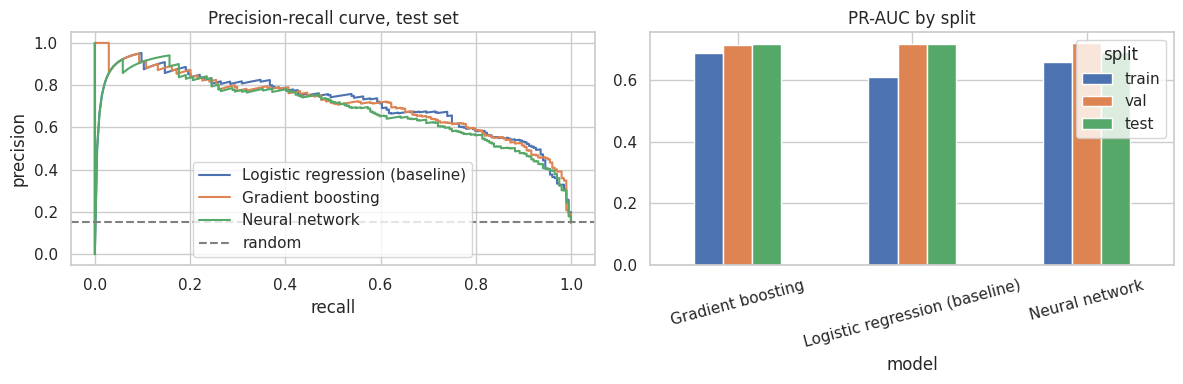

In [151]:
# PART 4 - M5: FINAL COMPARISON, THE ONLY CELL THAT SCORES THE TEST SET
FINAL = {"Logistic regression (baseline)": lr,
         "Gradient boosting": hgb,
         "Neural network": nn}

for name, mdl in FINAL.items():
    score(mdl, name, splits=("train", "val", "test"))      # threshold still comes from validation

comparison = pd.concat(RESULTS.values(), ignore_index=True)
table = comparison.pivot(index="model", columns="split", values=["roc_auc", "pr_auc", "f1"])
table = table.reindex(columns=pd.MultiIndex.from_product([["roc_auc", "pr_auc", "f1"], ["train", "val", "test"]]))
display(table.round(4))
table.round(4).to_csv("model_comparison.csv")

# how noisy is the test PR-AUC? bootstrap 95% interval (boot_pr is defined in the E1 cells)
rows = []
for name, mdl in FINAL.items():
    p = mdl.predict_proba(X["test"])[:, 1]
    lo, hi = boot_pr(y["test"], p)
    rows.append(dict(model=name, test_pr=average_precision_score(y["test"], p), ci_low=lo, ci_high=hi))
display(pd.DataFrame(rows).set_index("model").round(4))
print("random-guess PR-AUC (= test podium rate):", round(y["test"].mean(), 3))

# the model we would pick is chosen by VALIDATION, not by test
best_name = max(FINAL, key=lambda k: RESULTS[k].set_index("split").loc["val", "pr_auc"])
print("best by validation PR-AUC:", best_name)

# plots
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, mdl in FINAL.items():
    prec, rec, _ = precision_recall_curve(y["test"], mdl.predict_proba(X["test"])[:, 1])
    ax[0].plot(rec, prec, label=name)
ax[0].axhline(y["test"].mean(), color="grey", ls="--", label="random")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision-recall curve, test set"); ax[0].legend()
comparison.pivot(index="model", columns="split", values="pr_auc")[["train", "val", "test"]].plot(kind="bar", ax=ax[1])
ax[1].set_title("PR-AUC by split"); ax[1].tick_params(axis="x", rotation=15)
savefig("07_model_comparison")

## A1 – Feature-Group Ablation

**Purpose:** Identify which groups of features help the F1 podium prediction models perform better. The experiments use validation data only, keeping the test set untouched.

1. **ClipLogQ1 transformer:** Clips extreme `q1_gap_pct` values and applies a logarithmic transformation. If this feature is removed during an experiment, the transformer skips it.

2. **Load the best settings:** `HB` and `NB` retrieve the best Gradient Boosting and Neural Network hyperparameters previously selected using validation data.

3. **Build the models:** The `build()` function creates Logistic Regression, Gradient Boosting, or Neural Network models using a specified set of features.

4. **Calculate validation scores:** `val_scores()` trains each model on the training set and evaluates it on the validation set using PR-AUC and ROC-AUC. The Neural Network runs three times with different random seeds, and its scores are averaged.

5. **Run the ablation experiments:**
   - **All features:** Establishes the baseline performance.
   - **Drop one group:** Removes one feature group while keeping the others to measure how performance changes.
   - **Only one group:** Uses only one feature group to evaluate how predictive it is by itself.

6. **Calculate performance changes:** `pr_change` is the difference between the validation PR-AUC after removing a group and the all-features baseline.
   - Negative change: Removing the group hurts performance, suggesting the group is helpful.
   - Near-zero change: Removing the group has little effect.
   - Positive change: Removing the group improves performance.

7. **Create the tables:**
   - `drop_tbl` shows the change in validation PR-AUC after removing each group.
   - `only_tbl` shows the validation PR-AUC when each group is used alone.

8. **Interpret the graphs:**
   - **Drop one group:** Bars to the left of zero indicate decreased PR-AUC after removal, while bars to the right indicate increased PR-AUC.
   - **Only this group:** Longer bars indicate higher PR-AUC when a group is used alone.

9. **Save the results:** The experiments are saved in `ablation_results.csv`, and the graphs are saved using `savefig("08_ablation")`.

**Key takeaway:** Feature-group ablation helps identify which groups contribute useful predictive information, which groups add little value, and which groups may reduce performance. It measures predictive usefulness, not causation.

All features, validation:


,val_pr,val_roc
model,,
Logistic regression,0.7155,0.9336
Gradient boosting,0.7131,0.9368
Neural network,0.7224,0.9372


Drop one group: PR-AUC change (negative = group helped)


model,Logistic regression,Gradient boosting,Neural network
group,,,
constructor_form,-0.0019,0.0019,-0.0018
context,0.0003,0.0035,-0.0021
driver_form,-0.0158,0.0043,-0.0179
grid,-0.0144,-0.0013,-0.0118
qualifying,0.0017,-0.0005,0.0044
standings,0.0011,0.0041,-0.0082


Only this group: validation PR-AUC


model,Logistic regression,Gradient boosting,Neural network
group,,,
constructor_form,0.5725,0.5795,0.5708
context,0.1495,0.1441,0.1500
driver_form,0.6385,0.6041,0.6319
grid,0.6683,0.6680,0.6684
qualifying,0.7048,0.6797,0.7070
standings,0.6200,0.6241,0.6259


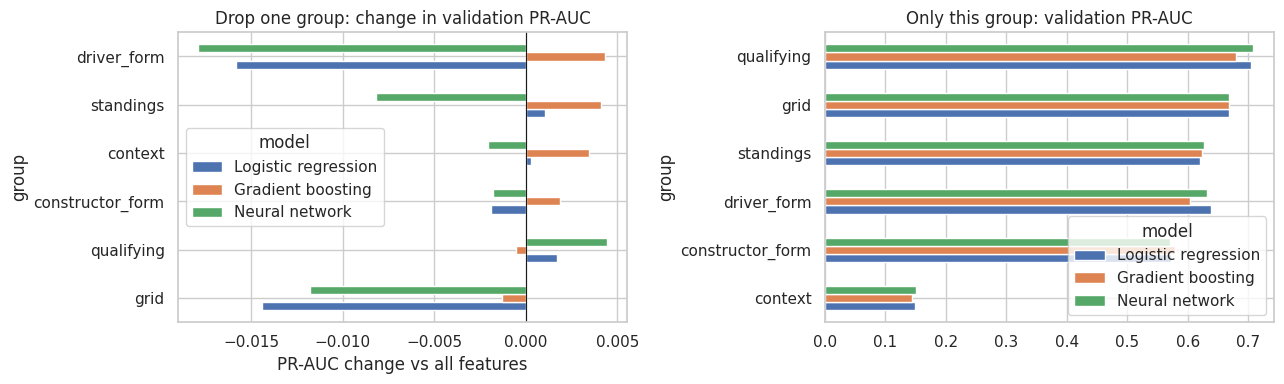

In [152]:
# PART 5 - A1: FEATURE-GROUP ABLATION (validation only)
class ClipLogQ1(BaseEstimator, TransformerMixin):
    def __init__(self, col="q1_gap_pct", features=None):
        self.col = col; self.features = features
    def fit(self, X, y=None):
        feats = list(self.features)
        self.j_ = feats.index(self.col) if self.col in feats else None     # None = column was ablated away
        if self.j_ is not None:
            self.cap_ = np.nanpercentile(np.asarray(X, dtype=float)[:, self.j_], 99)
        return self
    def transform(self, X):
        A = np.array(X, dtype=float, copy=True)
        if self.j_ is not None:
            A[:, self.j_] = np.log1p(np.clip(A[:, self.j_], 0, self.cap_))
        return A

HB = tune_hgb.iloc[0]; NB = tune_nn.iloc[0]          # best settings found on validation in M3 and M4b
def build(kind, feats, seed=42):
    pre = [ClipLogQ1(features=feats), SimpleImputer(strategy="median"), StandardScaler()]
    if kind == "Logistic regression":
        return make_pipeline(*pre, LogisticRegression(C=best_C, max_iter=3000))
    if kind == "Gradient boosting":
        return HistGradientBoostingClassifier(max_depth=int(HB.max_depth), learning_rate=HB.learning_rate,
                   max_iter=int(HB.max_iter), min_samples_leaf=50, l2_regularization=1.0,
                   early_stopping=False, random_state=seed)
    return make_pipeline(*pre, MLPClassifier(hidden_layer_sizes=eval(NB.hidden), alpha=NB.alpha,
                   learning_rate_init=1e-3, max_iter=300, early_stopping=False, random_state=seed))

def val_scores(kind, feats):
    seeds = [42, 43, 44] if kind == "Neural network" else [42]      # NN starts from random weights: average 3 runs
    pr, roc = [], []
    for s in seeds:
        m = build(kind, feats, s).fit(X["train"][feats], y["train"])
        p = m.predict_proba(X["val"][feats])[:, 1]
        pr.append(average_precision_score(y["val"], p)); roc.append(roc_auc_score(y["val"], p))
    return np.mean(pr), np.mean(roc)

MODELS = ["Logistic regression", "Gradient boosting", "Neural network"]
GROUPS = {g: [f for f in fs if f in FEATURES] for g, fs in FEATURE_GROUPS.items()}   # only features still in use
GROUPS = {g: fs for g, fs in GROUPS.items() if fs}

rows = []
for kind in MODELS:
    full_pr, full_roc = val_scores(kind, FEATURES)
    rows.append(dict(model=kind, setting="all features", group="-", n_features=len(FEATURES), val_pr=full_pr, val_roc=full_roc))
    for g, fs in GROUPS.items():
        keep = [f for f in FEATURES if f not in fs]                  # drop this group
        pr, roc = val_scores(kind, keep)
        rows.append(dict(model=kind, setting="drop group", group=g, n_features=len(keep), val_pr=pr, val_roc=roc))
        pr, roc = val_scores(kind, fs)                               # keep only this group
        rows.append(dict(model=kind, setting="only group", group=g, n_features=len(fs), val_pr=pr, val_roc=roc))
abl = pd.DataFrame(rows)

full = abl[abl.setting == "all features"].set_index("model")
abl["pr_change"]  = abl.val_pr  - abl.model.map(full.val_pr)
abl["roc_change"] = abl.val_roc - abl.model.map(full.val_roc)

drop_tbl = abl[abl.setting == "drop group"].pivot(index="group", columns="model", values="pr_change")[MODELS]
only_tbl = abl[abl.setting == "only group"].pivot(index="group", columns="model", values="val_pr")[MODELS]
print("All features, validation:");                              display(full[["val_pr", "val_roc"]].round(4))
print("Drop one group: PR-AUC change (negative = group helped)"); display(drop_tbl.round(4))
print("Only this group: validation PR-AUC");                      display(only_tbl.round(4))
abl.round(4).to_csv("ablation_results.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
drop_tbl.sort_values(MODELS[1]).plot(kind="barh", ax=ax[0]); ax[0].axvline(0, color="k", lw=.8)
ax[0].set_title("Drop one group: change in validation PR-AUC"); ax[0].set_xlabel("PR-AUC change vs all features")
only_tbl.sort_values(MODELS[1]).plot(kind="barh", ax=ax[1]); ax[1].set_title("Only this group: validation PR-AUC")
savefig("08_ablation")

## Feature-Group Ablation: Conclusions

The feature-group ablation experiment was conducted to understand how different groups of features contribute to F1 podium prediction. Three models were evaluated: Logistic Regression, Gradient Boosting, and a Neural Network. We compared their validation performance using all features, after removing one feature group at a time, and when using each group individually. PR-AUC was the main metric used to compare the experiments.

### 1. Performance Using All Features

When all feature groups were included, the Neural Network achieved the highest validation PR-AUC of **0.7224**, followed by Logistic Regression at **0.7155** and Gradient Boosting at **0.7131**. The Neural Network also achieved the highest validation ROC-AUC of **0.9372**. These results show that all three models can achieve strong predictive performance using the complete feature set.

### 2. Effect of Removing Feature Groups

The drop-group experiments showed that the importance of each feature group varies between models.

- **Driver form:** Removing this group reduced PR-AUC by 0.0158 for Logistic Regression and 0.0179 for the Neural Network, indicating that driver form provides useful predictive information for these models. However, removing it slightly improved Gradient Boosting's score.
- **Grid:** Removing grid information reduced PR-AUC for all three models, although the decrease for Gradient Boosting was small. This suggests that grid position contributes useful information to the prediction task.
- **Constructor form and context:** Their effects were generally small and varied between models.
- **Qualifying:** Removing qualifying features slightly improved Logistic Regression and the Neural Network, while having almost no effect on Gradient Boosting. This suggests that qualifying information may overlap with information provided by other feature groups or interact differently with each model.
- **Standings:** Removing standings slightly improved Logistic Regression and Gradient Boosting, but reduced Neural Network performance by 0.0082.

Overall, the results indicate that feature-group usefulness is model-dependent. A group that improves one model may have little benefit or even reduce validation performance for another.

### 3. Performance Using Only One Feature Group

When each feature group was evaluated independently, **qualifying was the strongest standalone group for all three models**. Its validation PR-AUC ranged from 0.6797 for Gradient Boosting to 0.7070 for the Neural Network.

Grid information was the second-strongest standalone group, achieving PR-AUC values of approximately 0.668 across the three models. Driver form and standings also provided useful predictive information when used independently.

In contrast, context had the lowest standalone performance, with PR-AUC values around 0.14–0.15. This indicates that context alone provides limited ability to distinguish podium finishers from non-podium finishers. However, its low standalone performance does not necessarily mean it is useless when combined with other feature groups.

### 4. Final Decision

Based on the ablation results, **we decided to retain all feature groups for the final modelling approach**. The complete feature set achieved the highest validation PR-AUC for the Neural Network, and no individual feature group outperformed the complete feature set for any of the three models.

Although removing certain groups produced small improvements for some models, these changes varied between models and may not represent meaningful improvements. Retaining all feature groups also allows the models to use complementary information from qualifying performance, grid position, driver form, constructor form, standings, and race context.

The ablation results therefore support keeping the complete feature set as a reasonable overall choice rather than removing groups based on small validation-score differences. These conclusions are based on validation performance and do not establish that every feature group is independently useful. The test set should remain reserved for the final evaluation of the selected models.

# X1 — Permutation Importance

**Purpose:** Identify which individual features and feature groups the trained models rely on most when predicting F1 podium finishes, using validation PR-AUC.

### 1. Individual Feature Importance

- **Models:** Gradient Boosting, Logistic Regression, and Neural Network.
- `permutation_importance()` shuffles each feature 20 times and measures the drop in validation PR-AUC.
- `mean`: Average PR-AUC drop across repetitions.
- `std`: Standard deviation of the drops.
- Features are ranked by mean importance, and the top 10 are displayed.
- A bar chart displays the top 12 features for each model.

**Interpretation:**
- Positive importance: Shuffling the feature reduces PR-AUC, suggesting it helps the model.
- Near-zero importance: Shuffling has little effect.
- Negative importance: Shuffling improves PR-AUC in this experiment.

### 2. Grouped Permutation Importance

This experiment shuffles all features in a group together instead of shuffling individual features.

**Steps:**
1. Calculate the original validation PR-AUC.
2. Shuffle the rows of all features in one group together.
3. Recalculate PR-AUC and measure the drop.
4. Repeat 20 times and calculate the mean and standard deviation.
5. Compare the importance of different groups across all three models.

The results are displayed in a table and a horizontal bar chart.

### 3. Difference from Feature-Group Ablation

- **Ablation:** Removes a feature group and retrains the model to measure the effect on performance.
- **Permutation importance:** Keeps the trained model fixed and shuffles validation features to measure how much the model relies on them.

### Conclusion

Permutation importance helps identify which features and feature groups contribute most to the validation predictions of Logistic Regression, Gradient Boosting, and the Neural Network. Larger positive PR-AUC drops indicate greater predictive reliance. However, correlated features can affect these results, and importance does not imply causation. All comparisons use the validation set; the test set remains reserved for final evaluation.

Gradient boosting


,mean,std
rel_grid,0.0765,0.0201
grid_eff,0.0593,0.0173
drv_career_podium_rate,0.0219,0.0041
quali_pos,0.0111,0.0089
drv_rank_before,0.0107,0.0083
con_avg_finish,0.0074,0.0059
con_pts_rel,0.0061,0.0069
con_podium_rate,0.0055,0.0051
drv_races_before,0.0039,0.0084
drv_podium_rate,0.0022,0.0028


Logistic regression


,mean,std
rel_grid,0.1416,0.0255
grid_eff,0.0363,0.0150
drv_career_podium_rate,0.0152,0.0085
con_avg_finish,0.0104,0.0060
drv_avg_finish,0.0101,0.0065
drv_podium_rate,0.0090,0.0072
quali_pos,0.0090,0.0071
drv_rank_before,0.0076,0.0065
grid_minus_quali,0.0072,0.0059
drv_dnf_rate,0.0069,0.0082


Neural network


,mean,std
rel_grid,0.0690,0.0182
drv_races_before,0.0205,0.0103
drv_podium_rate,0.0186,0.0089
front_row,0.0184,0.0095
drv_pts_rel,0.0181,0.0080
grid_eff,0.0146,0.0098
is_pitlane,0.0130,0.0084
drv_career_podium_rate,0.0116,0.0062
quali_pos,0.0109,0.0071
con_avg_finish,0.0107,0.0067


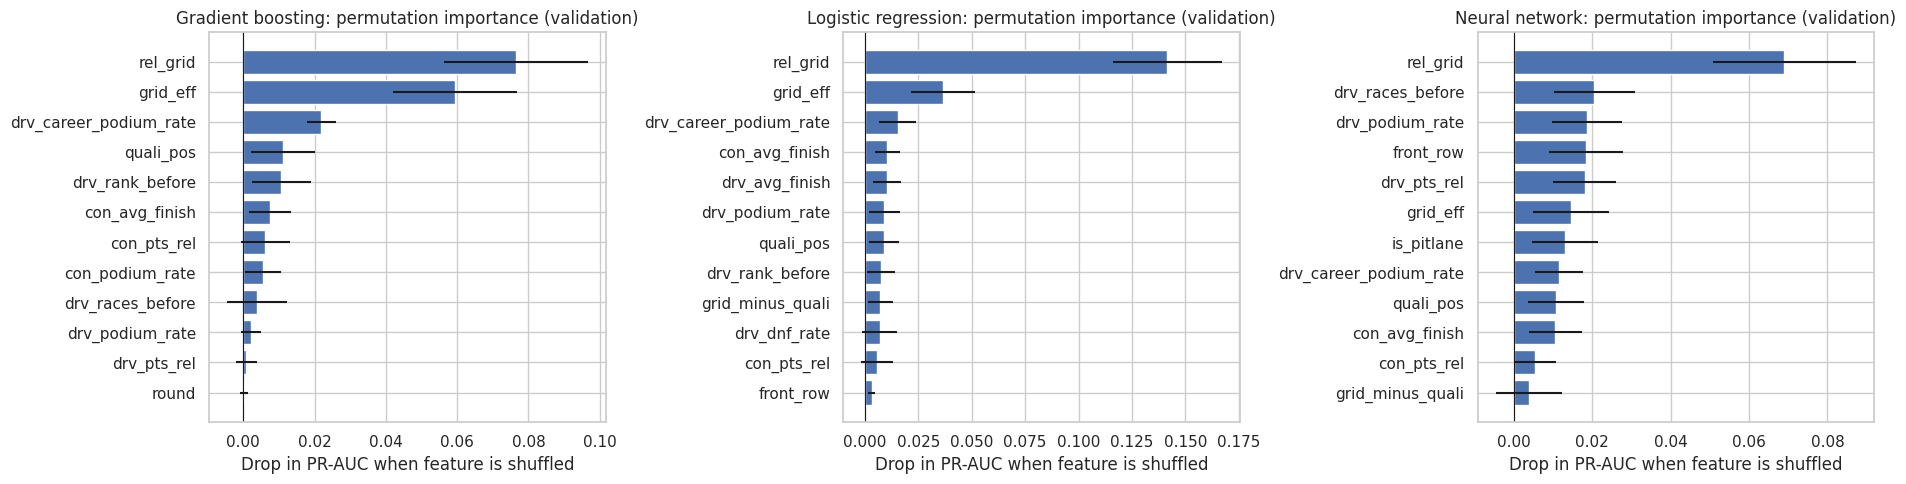

,Gradient boosting,Logistic regression,Neural network
grid,0.2660,0.2794,0.2517
qualifying,0.0093,0.0178,0.0187
driver_form,0.0108,0.0707,0.0344
constructor_form,0.0084,0.0013,0.0058
standings,0.0236,0.0112,0.0184
context,0.0001,0.0024,0.0017


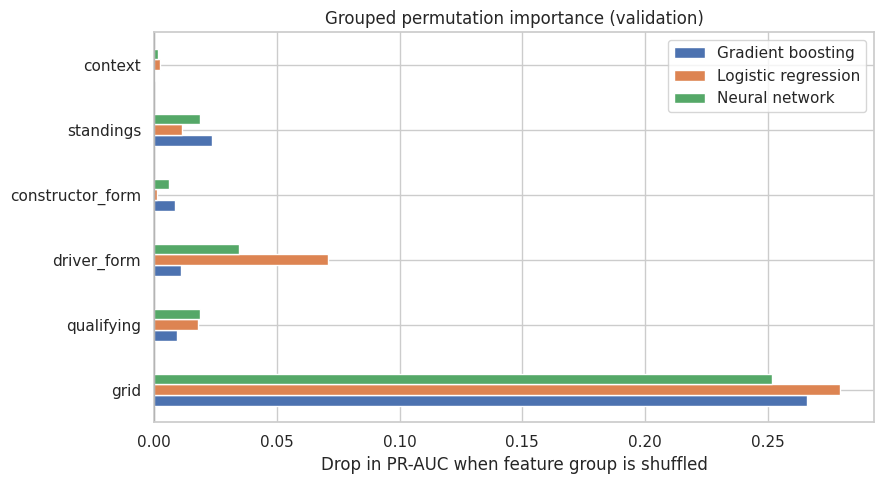

In [153]:

# PART 6 - X1: PERMUTATION IMPORTANCE (validation set)
from sklearn.inspection import permutation_importance

XAI_MODELS = {
    "Gradient boosting": hgb,
    "Logistic regression": lr,
    "Neural network": nn
}

# INDIVIDUAL FEATURE IMPORTANCE
pi = {}

for name, mdl in XAI_MODELS.items():
    r = permutation_importance(
        mdl, X["val"], y["val"],
        scoring="average_precision",
        n_repeats=20, random_state=42, n_jobs=-1
    )

    pi[name] = pd.DataFrame(
        {"mean": r.importances_mean, "std": r.importances_std},
        index=FEATURES
    )

    print(name)
    display(pi[name].sort_values("mean", ascending=False).head(10).round(4))

TOP = 12
fig, ax = plt.subplots(1, len(XAI_MODELS), figsize=(19, 5))

for a, (name, t) in zip(ax, pi.items()):
    t = t.sort_values("mean", ascending=False).head(TOP).iloc[::-1]
    a.barh(t.index, t["mean"], xerr=t["std"])
    a.axvline(0, color="k", lw=.8)
    a.set_title(f"{name}: permutation importance (validation)")
    a.set_xlabel("Drop in PR-AUC when feature is shuffled")

plt.tight_layout()
savefig("09_permutation_importance")


# GROUPED PERMUTATION IMPORTANCE
# Shuffle a whole feature group together
def grouped_perm(model, Xv, yv, groups, n_repeats=20, seed=42):
    rng = np.random.default_rng(seed)
    base = average_precision_score(
        yv, model.predict_proba(Xv)[:, 1]
    )
    out = {}

    for g, cols in groups.items():
        drops = []

        for _ in range(n_repeats):
            Xp = Xv.copy()
            Xp[cols] = Xv[cols].to_numpy()[
                rng.permutation(len(Xv))
            ]

            drops.append(
                base - average_precision_score(
                    yv, model.predict_proba(Xp)[:, 1]
                )
            )

        out[g] = (np.mean(drops), np.std(drops))

    return pd.DataFrame(out, index=["mean", "std"]).T


gp = {
    name: grouped_perm(mdl, X["val"], y["val"], GROUPS)
    for name, mdl in XAI_MODELS.items()
}

gtab = pd.concat(
    {name: result["mean"] for name, result in gp.items()},
    axis=1
)

display(gtab.round(4))

gtab.plot(kind="barh", figsize=(9, 5))
plt.axvline(0, color="k", lw=.8)
plt.title("Grouped permutation importance (validation)")
plt.xlabel("Drop in PR-AUC when feature group is shuffled")
plt.tight_layout()
savefig("10_grouped_permutation")


## X2 — SHAP Global Explanation

**Purpose:** Explain how Gradient Boosting, Logistic Regression, and the Neural Network make podium predictions and identify the most influential features.

### 1. Data Preparation
- `bg`: Selects 100 training rows as background reference data.
- `X_explain`: Selects up to 800 validation rows to explain.
- `explain_model`: Selects each trained model in turn.

### 2. SHAP Calculation
- `predict_podium()`: Returns the selected model's predicted podium probabilities.
- `explainer`: Creates a SHAP explainer using the permutation algorithm.
- `shap_vals`: Calculates each feature's contribution to each prediction for each model.

**SHAP values** show how much each feature pushes a prediction higher or lower relative to the baseline prediction.

### 3. Additivity Check
- `base_values`: The baseline prediction for the model being explained.
- `gap`: Checks whether the baseline plus all SHAP contributions matches the model's prediction. A very small gap indicates a close match.

### 4. Outputs
For each model:
- **Mean |SHAP| table:** Ranks features by average contribution magnitude.
- **SHAP bar plot:** Shows the most influential features overall.
- **SHAP beeswarm plot:** Shows how features affect individual predictions and whether they push predictions higher or lower.
- **Grouped SHAP table and plot:** Compares feature groups by summing the absolute SHAP contributions of their features.

### Conclusion
SHAP allows us to compare which features influence Gradient Boosting, Logistic Regression, and the Neural Network most. Larger absolute SHAP values indicate stronger influence, while positive and negative values indicate whether a feature pushes a prediction higher or lower. SHAP explains model predictions but does not prove causation.


==================== Gradient boosting ====================


PermutationExplainer explainer: 801it [00:41, 14.68it/s]                         

Max additivity gap: 9.5e-05
Baseline podium probability: 0.105

Mean absolute SHAP importance:


,mean |SHAP|
rel_grid,0.0482
grid_eff,0.0430
drv_career_podium_rate,0.0211
con_podium_rate,0.0126
con_pts_rel,0.0121
con_avg_finish,0.0110
drv_rank_before,0.0101
drv_races_before,0.0075
drv_podium_rate,0.0071
quali_pos,0.0070


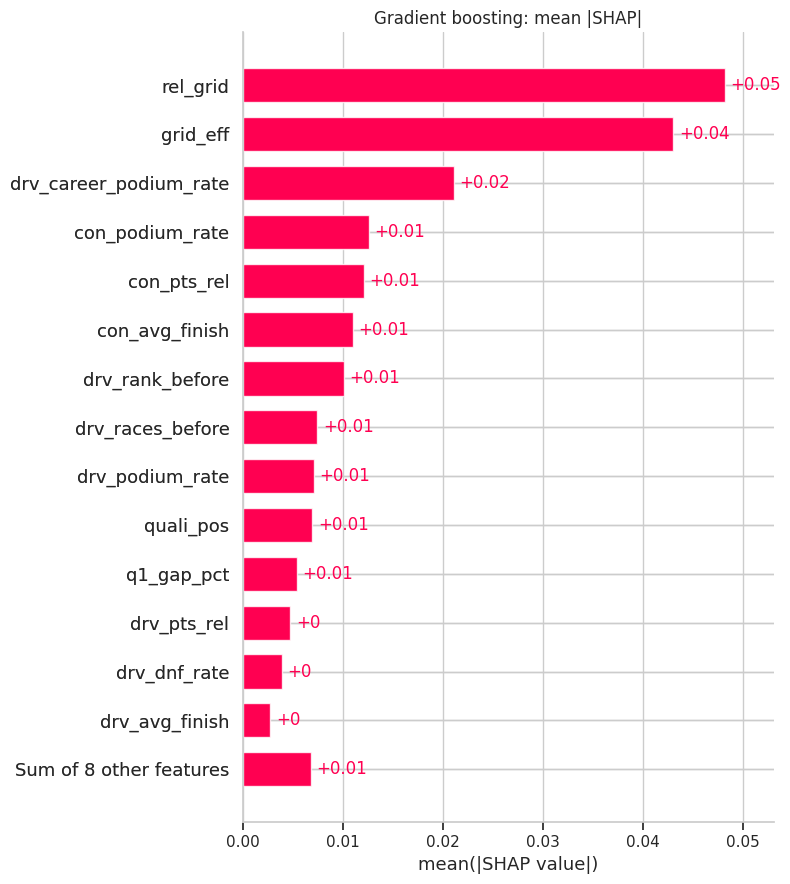

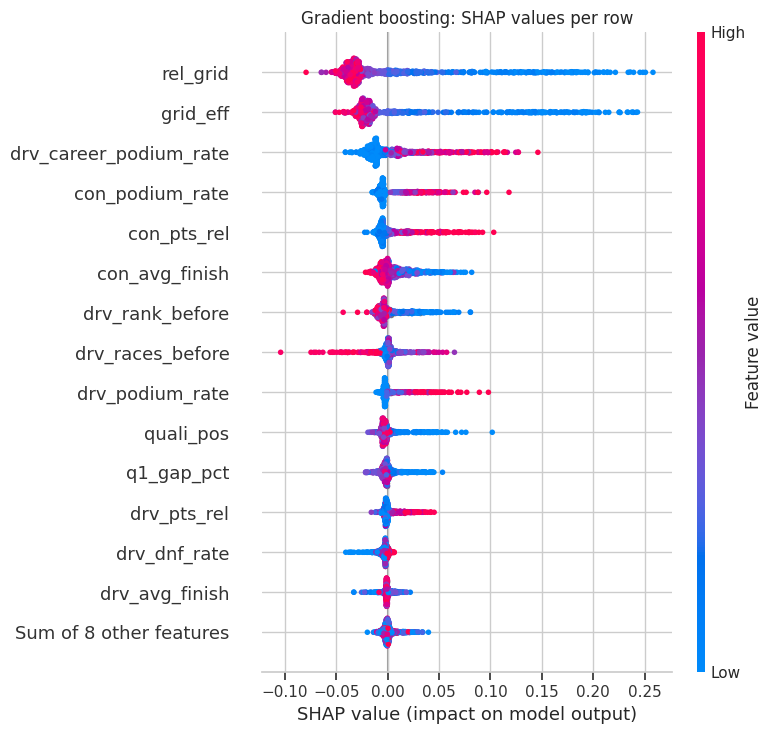


Grouped SHAP importance:


,sum of mean |SHAP|
grid,0.0915
driver_form,0.0424
standings,0.0270
constructor_form,0.0259
qualifying,0.0131
context,0.0037


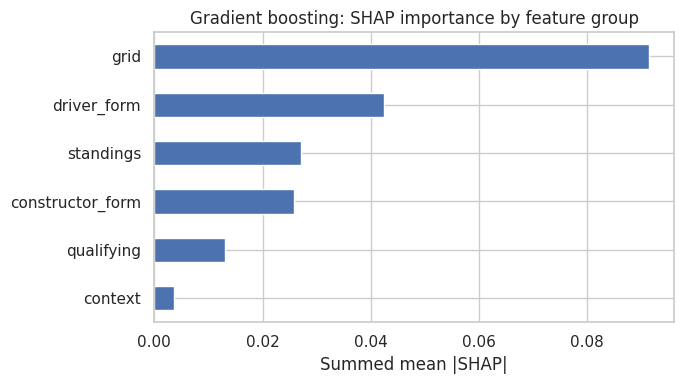


==================== Logistic regression ====================
Max additivity gap: 0.0
Baseline podium probability: 0.113

Mean absolute SHAP importance:


,mean |SHAP|
rel_grid,0.0573
grid_eff,0.0321
drv_dnf_rate,0.0221
drv_podium_rate,0.0173
con_avg_finish,0.0167
con_pts_rel,0.0165
drv_avg_finish,0.0154
drv_career_podium_rate,0.0136
drv_rank_before,0.0130
quali_pos,0.0127


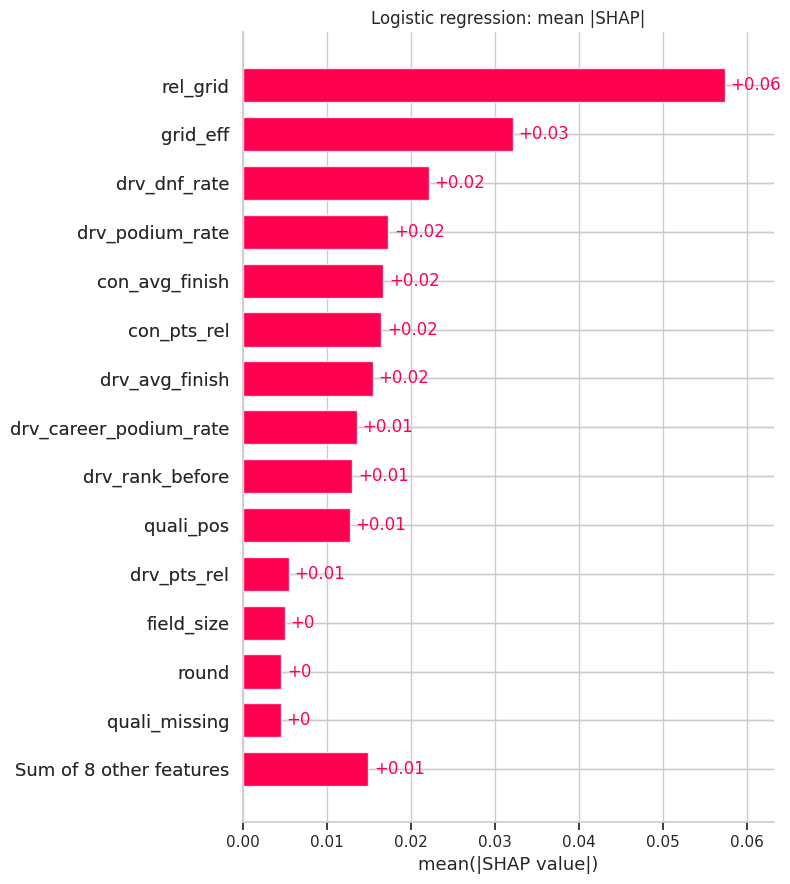

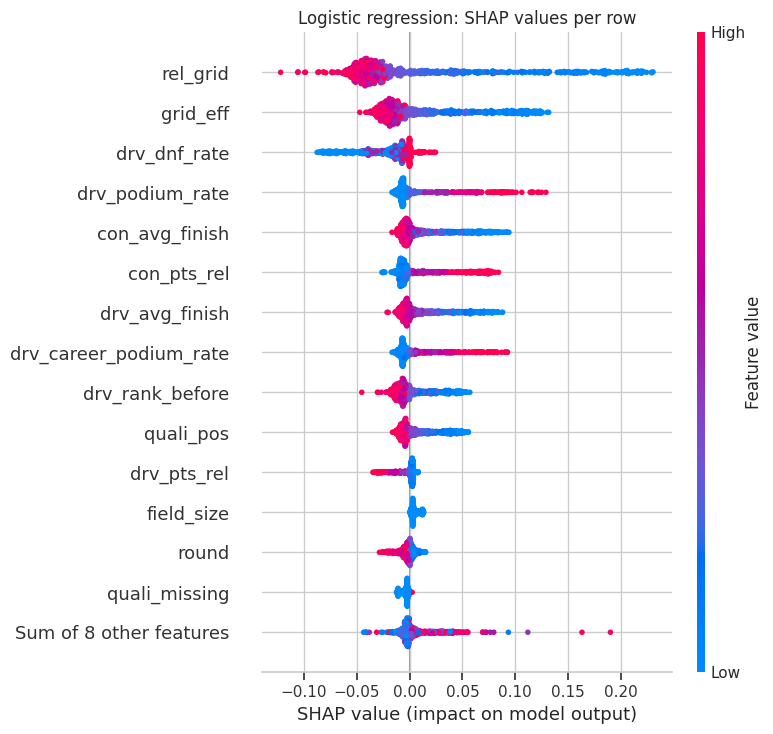


Grouped SHAP importance:


,sum of mean |SHAP|
grid,0.0941
driver_form,0.0726
standings,0.0350
qualifying,0.0216
constructor_form,0.0181
context,0.0100


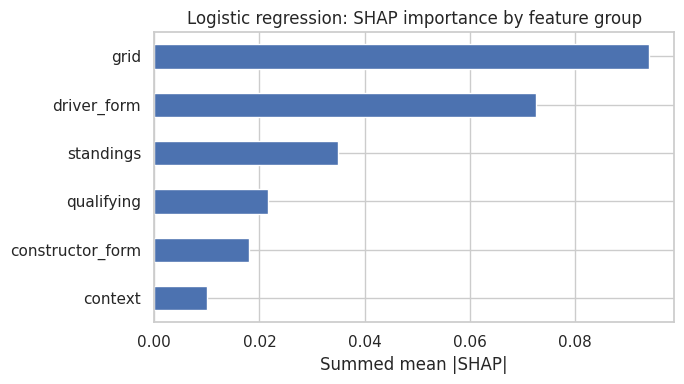


==================== Neural network ====================
Max additivity gap: 0.0
Baseline podium probability: 0.115

Mean absolute SHAP importance:


,mean |SHAP|
rel_grid,0.0542
grid_eff,0.0308
con_pts_rel,0.0246
drv_career_podium_rate,0.0218
quali_pos,0.0196
con_avg_finish,0.0187
drv_podium_rate,0.0171
quali_missing,0.0151
front_row,0.0139
drv_races_before,0.0134


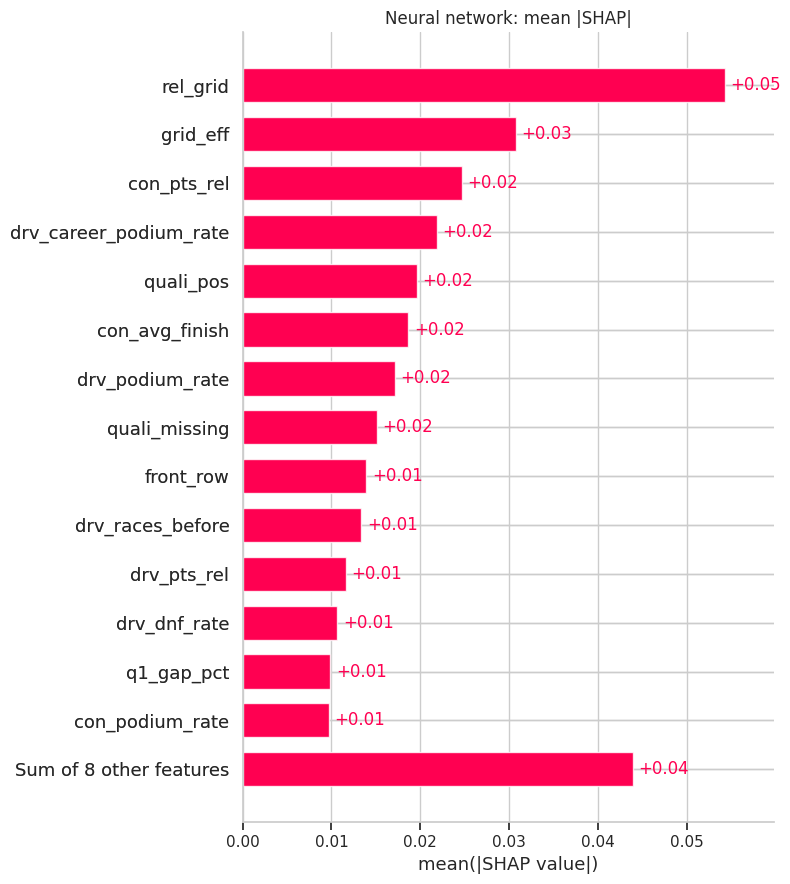

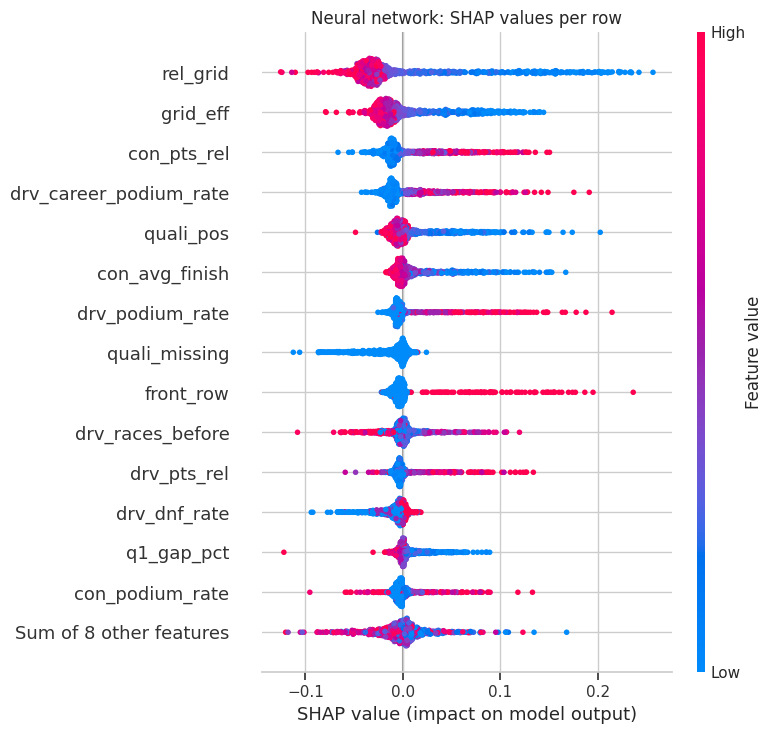


Grouped SHAP importance:


,sum of mean |SHAP|
grid,0.1013
driver_form,0.0692
qualifying,0.0480
standings,0.0424
constructor_form,0.0347
context,0.0193


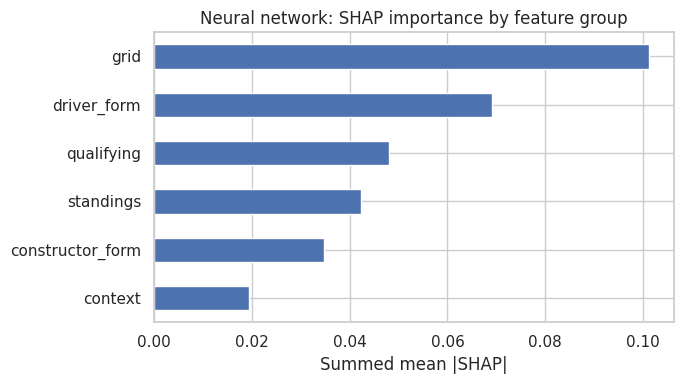


Feature importance comparison:


,Gradient boosting,Logistic regression,Neural network
rel_grid,0.0482,0.0573,0.0542
grid_eff,0.0430,0.0321,0.0308
drv_career_podium_rate,0.0211,0.0136,0.0218
con_podium_rate,0.0126,0.0012,0.0097
con_pts_rel,0.0121,0.0165,0.0246
con_avg_finish,0.0110,0.0167,0.0187
drv_rank_before,0.0101,0.0130,0.0062
drv_races_before,0.0075,0.0042,0.0134
drv_podium_rate,0.0071,0.0173,0.0171
quali_pos,0.0070,0.0127,0.0196



Feature-group importance comparison:


,Gradient boosting,Logistic regression,Neural network
grid,0.0915,0.0941,0.1013
driver_form,0.0424,0.0726,0.0692
standings,0.0270,0.0350,0.0424
constructor_form,0.0259,0.0181,0.0347
qualifying,0.0131,0.0216,0.0480
context,0.0037,0.0100,0.0193


In [154]:

# PART 6 - X2: SHAP GLOBAL EXPLANATION (validation rows)
import shap

XAI_MODELS = {
    "Gradient boosting": hgb,
    "Logistic regression": lr,
    "Neural network": nn
}

bg = X["train"].sample(100, random_state=42)
X_explain = X["val"].sample(min(800, len(X["val"])), random_state=42)


def predict_podium(model, Z):
    Z = pd.DataFrame(Z, columns=FEATURES)
    return model.predict_proba(Z)[:, 1]


# Run SHAP separately for each model
shap_results = {}
shap_importances = {}
group_importances = {}

for name, model in XAI_MODELS.items():

    print(f"\n{'=' * 20} {name} {'=' * 20}")

    # SHAP prediction function for the current model
    predict_fn = lambda Z, m=model: predict_podium(m, Z)

    explainer = shap.Explainer(
        predict_fn, bg,
        algorithm="permutation",
        seed=42
    )

    shap_vals = explainer(
        X_explain,
        max_evals=4 * len(FEATURES) + 1
    )

    shap_results[name] = shap_vals

    # Check additivity
    predictions = predict_podium(model, X_explain)
    gap = np.abs(
        shap_vals.values.sum(axis=1)
        + shap_vals.base_values
        - predictions
    ).max()

    print("Max additivity gap:", round(float(gap), 6))
    print(
        "Baseline podium probability:",
        round(float(np.mean(shap_vals.base_values)), 3)
    )

    # Individual feature importance
    shap_imp = pd.Series(
        np.abs(shap_vals.values).mean(axis=0),
        index=FEATURES
    ).sort_values(ascending=False)

    shap_importances[name] = shap_imp

    print("\nMean absolute SHAP importance:")
    display(shap_imp.round(4).to_frame("mean |SHAP|"))

    # SHAP bar plot
    shap.plots.bar(shap_vals, max_display=15, show=False)
    plt.title(f"{name}: mean |SHAP|")
    savefig(f"11_shap_bar_{name.lower().replace(' ', '_')}")

    # SHAP beeswarm plot
    shap.plots.beeswarm(shap_vals, max_display=15, show=False)
    plt.title(f"{name}: SHAP values per row")
    savefig(f"12_shap_beeswarm_{name.lower().replace(' ', '_')}")

    # Group-level SHAP importance
    group_imp = pd.Series({
        g: np.abs(
            shap_vals.values[:, [FEATURES.index(f) for f in fs]]
        ).sum(axis=1).mean()
        for g, fs in GROUPS.items()
    }).sort_values(ascending=False)

    group_importances[name] = group_imp

    print("\nGrouped SHAP importance:")
    display(group_imp.round(4).to_frame("sum of mean |SHAP|"))

    # Group-level plot
    group_imp.sort_values().plot(kind="barh", figsize=(7, 4))
    plt.title(f"{name}: SHAP importance by feature group")
    plt.xlabel("Summed mean |SHAP|")
    savefig(f"13_shap_groups_{name.lower().replace(' ', '_')}")


# Compare feature importance across all three models
shap_comparison = pd.concat(shap_importances, axis=1)
print("\nFeature importance comparison:")
display(shap_comparison.round(4))

# Compare feature-group importance across all three models
group_comparison = pd.concat(group_importances, axis=1)
print("\nFeature-group importance comparison:")
display(group_comparison.round(4))


## X3 — Local Explanations (SHAP Waterfall + LIME)

**Purpose:** Explain individual podium predictions by examining specific race cases using SHAP and LIME.

### 1. Select the Cases
- `p_val`: Stores each validation row's predicted podium probability.
- `cases`: Selects three examples:
  - **A — Confident hit:** Actual podium finish with the highest predicted probability.
  - **B — Surprise podium:** Actual podium finish with the lowest predicted probability.
  - **C — False alarm:** No podium finish but the highest predicted probability.
- `info`: Displays each selected driver's race, year, starting grid, finishing position, and predicted probability.

### 2. Local SHAP Waterfall Plots
- Explains cases A and B individually.
- `base_values`: Starting prediction before feature contributions.
- Positive SHAP values push the prediction higher; negative values push it lower.
- The waterfall plot shows how the features combine to produce the final prediction.

### 3. LIME Explanation
- Explains case B, the surprise podium.
- Missing values are filled using training-set medians.
- `LimeTabularExplainer`: Creates a local explanation by generating perturbed examples around the selected row.
- `exp.as_list()`: Displays the most influential feature rules and their LIME weights.
- `exp.score`: Measures how well LIME's local linear model approximates the original model around that case.
- The LIME plot visualizes the local feature contributions.

### Conclusion
SHAP Waterfall explains how individual features contribute to a specific prediction, while LIME approximates the model's behavior around one example. Using both helps investigate why the model correctly predicts a podium finish or makes a surprising prediction.

,case,race_name,year,grid,positionOrder,driver,p_podium
23708,"A: confident hit (podium, highest probability)",Abu Dhabi Grand Prix,2018,1,1,Lewis Hamilton,0.896
24120,"B: surprise podium (podium, lowest probability)",Brazilian Grand Prix,2019,20,3,Carlos Sainz,0.004
23928,"C: false alarm (no podium, highest probability)",German Grand Prix,2019,1,9,Lewis Hamilton,0.880


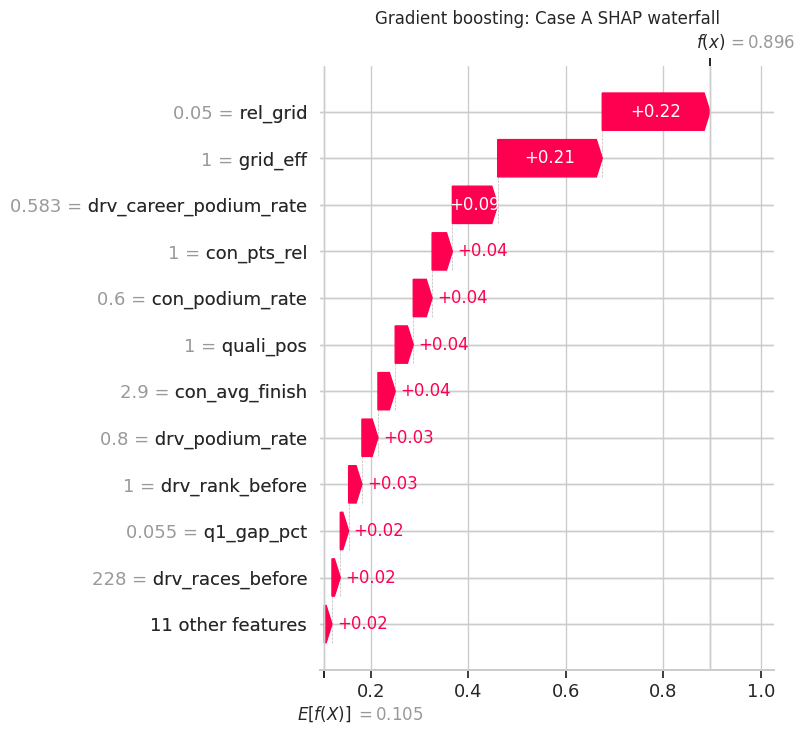


Case A:
Baseline probability: 0.1048
SHAP reconstructed prediction: 0.8957
Model predicted probability: 0.8957


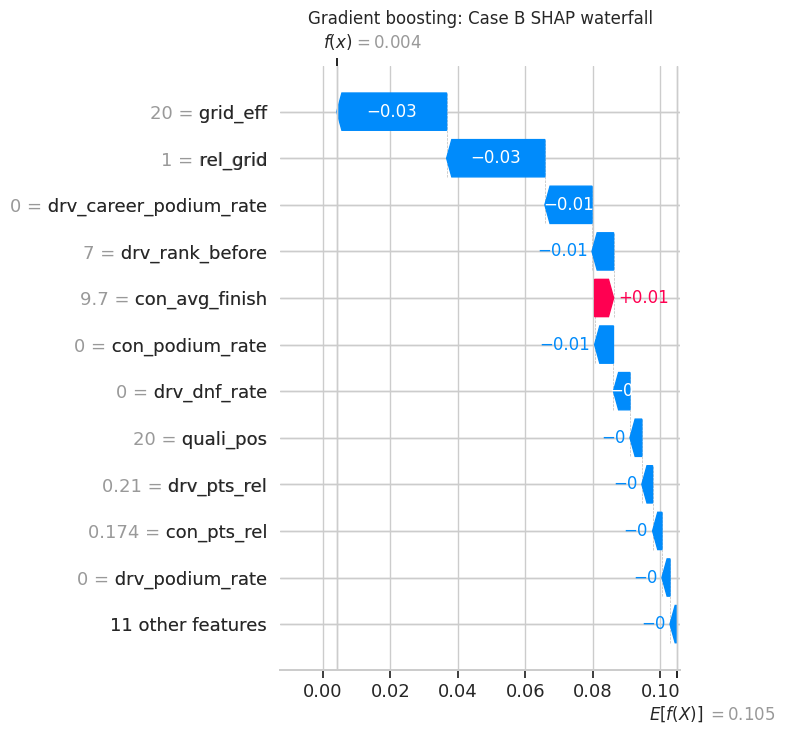


Case B:
Baseline probability: 0.1048
SHAP reconstructed prediction: 0.0041
Model predicted probability: 0.0041

LIME explanation for Case B:


,rule,LIME weight
0,rel_grid > 0.77,-0.0433
1,drv_career_podium_rate <= 0.00,-0.0339
2,grid_eff > 19.00,-0.0280
3,con_avg_finish <= 9.70,0.0259
4,drv_rank_before <= 7.00,0.0144
5,con_podium_rate <= 0.00,-0.0103
6,drv_podium_rate <= 0.00,-0.0099
7,drv_dnf_rate <= 0.20,-0.0082
8,0.10 < con_mech_dnf_rate <= 0.20,-0.0047
9,54.00 < drv_races_before <= 109.00,0.0045


LIME local R2: 0.228


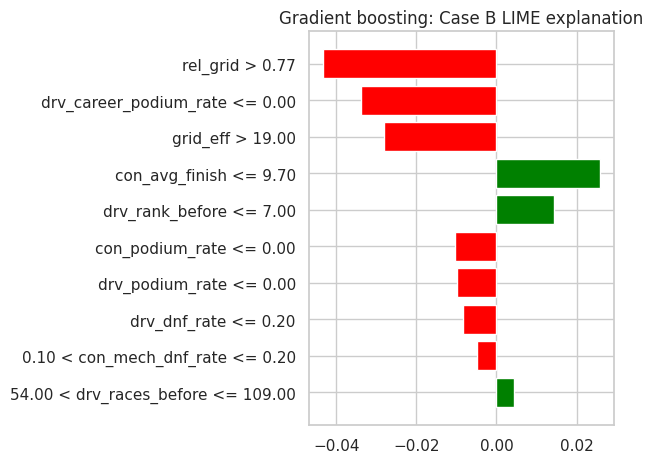

In [155]:

# PART 6 - X3: LOCAL EXPLANATIONS (SHAP waterfall + LIME)
# Explain individual validation predictions using Gradient Boosting

import shap
import lime
from lime.lime_tabular import LimeTabularExplainer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. SELECT THE MODEL TO EXPLAIN
# --------------------------------------------------

EXPLAIN_NAME = "Gradient boosting"
explain_model = XAI_MODELS[EXPLAIN_NAME]

# Create a SHAP explainer specifically for this model
predict_fn = lambda Z: predict_podium(explain_model, Z)

explainer = shap.Explainer(
    predict_fn,
    bg,
    algorithm="permutation",
    seed=42
)

# --------------------------------------------------
# 2. PREDICT PODIUM PROBABILITIES ON VALIDATION DATA
# --------------------------------------------------

p_val = pd.Series(
    explain_model.predict_proba(X["val"])[:, 1],
    index=X["val"].index
)

yv = y["val"]

# --------------------------------------------------
# 3. SELECT THREE CASES
# --------------------------------------------------

cases = {
    "A: confident hit (podium, highest probability)":
        p_val[yv == 1].idxmax(),

    "B: surprise podium (podium, lowest probability)":
        p_val[yv == 1].idxmin(),

    "C: false alarm (no podium, highest probability)":
        p_val[yv == 0].idxmax()
}

# --------------------------------------------------
# 4. DISPLAY INFORMATION ABOUT THE SELECTED DRIVERS
# --------------------------------------------------

names = CL["drivers"].set_index("driverId").pipe(
    lambda t: t.forename + " " + t.surname
)

info = d.loc[
    list(cases.values()),
    ["race_name", "year", "driverId", "grid", "positionOrder"]
].copy()

info["driver"] = info["driverId"].map(names)

info.insert(0, "case", list(cases.keys()))

info["p_podium"] = (
    p_val.loc[list(cases.values())].round(3).values
)

display(info.drop(columns="driverId"))

# Store the row indices for cases A and B
ROW_A = cases[
    "A: confident hit (podium, highest probability)"
]

ROW_B = cases[
    "B: surprise podium (podium, lowest probability)"
]

# --------------------------------------------------
# 5. LOCAL SHAP: WATERFALL PLOTS FOR CASES A AND B
# --------------------------------------------------

for label, idx in [("A", ROW_A), ("B", ROW_B)]:

    # Explain one driver's prediction
    sv1 = explainer(
        X["val"].loc[[idx]],
        max_evals=10 * len(FEATURES) + 1
    )

    # Display the SHAP waterfall plot
    shap.plots.waterfall(
        sv1[0],
        max_display=12,
        show=False
    )

    plt.title(
        f"{EXPLAIN_NAME}: Case {label} SHAP waterfall"
    )

    savefig(f"14_shap_waterfall_{label}")

    # Reconstruct the predicted probability
    reconstructed_prediction = (
        sv1.values[0].sum() + sv1.base_values[0]
    )

    actual_prediction = p_val.loc[idx]

    print(f"\nCase {label}:")
    print("Baseline probability:", round(float(sv1.base_values[0]), 4))
    print("SHAP reconstructed prediction:",
          round(float(reconstructed_prediction), 4))
    print("Model predicted probability:",
          round(float(actual_prediction), 4))

# --------------------------------------------------
# 6. PREPARE TRAINING DATA FOR LIME
# --------------------------------------------------

# Use training medians to fill missing feature values
med = X["train"].median()

X_train_lime = X["train"].fillna(med)

lime_exp = LimeTabularExplainer(
    X_train_lime.to_numpy(),
    feature_names=FEATURES,
    class_names=["no podium", "podium"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# --------------------------------------------------
# 7. LIME EXPLANATION FOR CASE B
# --------------------------------------------------

# Get the selected driver's feature values
case_B = X["val"].loc[ROW_B].fillna(med).to_numpy()

# Generate a local explanation using the same model
exp = lime_exp.explain_instance(
    case_B,
    lambda Z: explain_model.predict_proba(
        pd.DataFrame(Z, columns=FEATURES)
    ),
    num_features=10,
    num_samples=5000
)

# Display the LIME rules and their weights
print("\nLIME explanation for Case B:")

display(
    pd.DataFrame(
        exp.as_list(),
        columns=["rule", "LIME weight"]
    ).round(4)
)

# Check how well LIME's local model approximates
# the original model around Case B
print(
    "LIME local R2:",
    round(float(exp.score), 3)
)

# Display the LIME plot
exp.as_pyplot_figure()

plt.title(
    f"{EXPLAIN_NAME}: Case B LIME explanation"
)

savefig("15_lime_case_B")


,case,race_name,year,grid,positionOrder,driver,p_podium
23708,"A: confident hit (podium, highest probability)",Abu Dhabi Grand Prix,2018,1,1,Lewis Hamilton,0.896
24120,"B: surprise podium (podium, lowest probability)",Brazilian Grand Prix,2019,20,3,Carlos Sainz,0.004
23928,"C: false alarm (no podium, highest probability)",German Grand Prix,2019,1,9,Lewis Hamilton,0.880


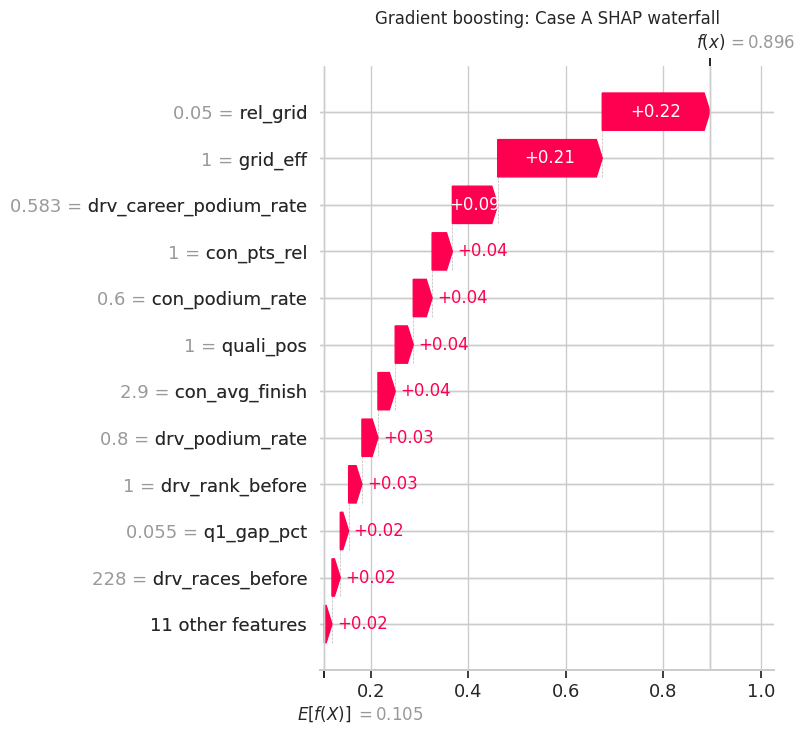


Case A:
Baseline probability: 0.1048
SHAP reconstructed prediction: 0.8957
Model predicted probability: 0.8957


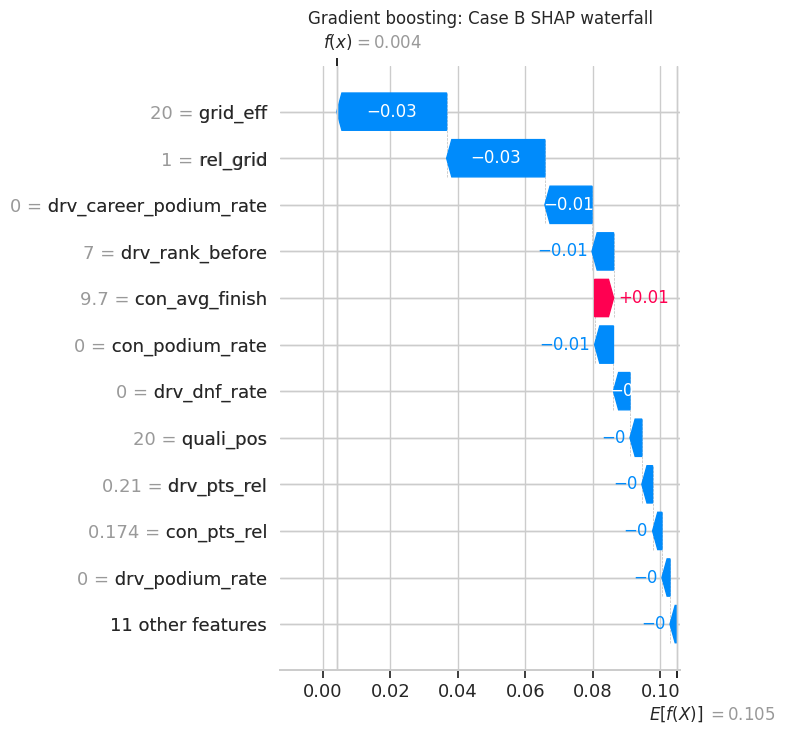


Case B:
Baseline probability: 0.1048
SHAP reconstructed prediction: 0.0041
Model predicted probability: 0.0041

LIME explanation for Case B: Gradient boosting
Model predicted podium probability: 0.004

LIME rules and weights:


,rule,LIME weight
0,rel_grid > 0.77,-0.0433
1,drv_career_podium_rate <= 0.00,-0.0339
2,grid_eff > 19.00,-0.0280
3,con_avg_finish <= 9.70,0.0259
4,drv_rank_before <= 7.00,0.0144
5,con_podium_rate <= 0.00,-0.0103
6,drv_podium_rate <= 0.00,-0.0099
7,drv_dnf_rate <= 0.20,-0.0082
8,0.10 < con_mech_dnf_rate <= 0.20,-0.0047
9,54.00 < drv_races_before <= 109.00,0.0045


LIME local R2: 0.228


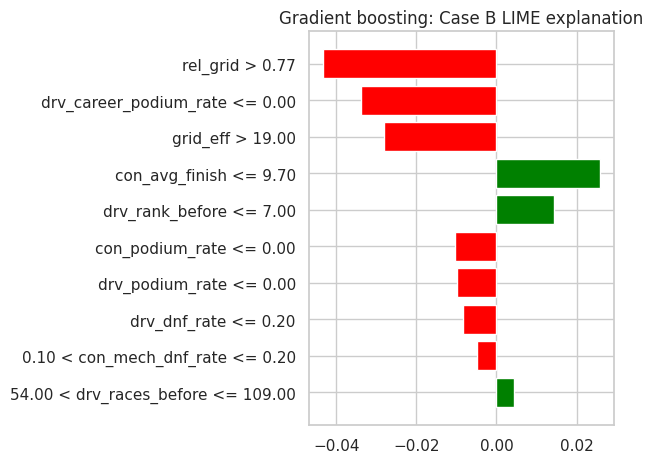


LIME explanation for Case B: Logistic regression
Model predicted podium probability: 0.0015

LIME rules and weights:


,rule,LIME weight
0,rel_grid > 0.77,-0.0510
1,grid_eff > 19.00,-0.0405
2,is_pitlane <= 0.00,0.0395
3,grid_minus_quali <= 0.00,-0.0365
4,drv_dnf_rate <= 0.20,-0.0218
5,con_avg_finish <= 9.70,0.0205
6,drv_avg_finish <= 9.40,0.0191
7,drv_rank_before <= 7.00,0.0147
8,drv_podium_rate <= 0.00,-0.0137
9,quali_pos > 11.00,-0.0096


LIME local R2: 0.284


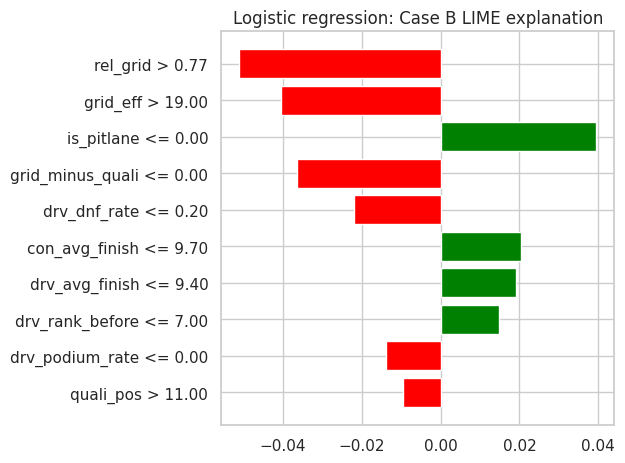


LIME explanation for Case B: Neural network
Model predicted podium probability: 0.0016

LIME rules and weights:


,rule,LIME weight
0,rel_grid > 0.77,-0.0607
1,grid_eff > 19.00,-0.0507
2,front_row <= 0.00,-0.0476
3,drv_career_podium_rate <= 0.00,-0.0336
4,grid_minus_quali <= 0.00,-0.0284
5,con_avg_finish <= 9.70,0.0271
6,quali_pos > 11.00,-0.0203
7,q1_gap_pct <= 1.55,0.0181
8,54.00 < drv_races_before <= 109.00,0.0138
9,round > 13.00,-0.0120


LIME local R2: 0.192


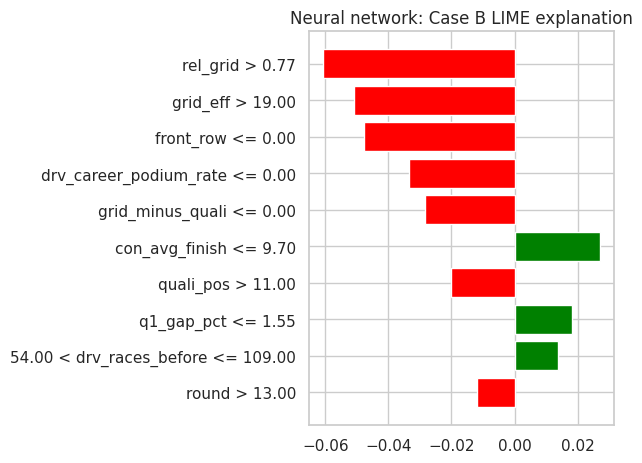


Comparison of LIME explanations for Case B:


,Model,Predicted podium probability,LIME local R2
0,Gradient boosting,0.0040,0.2279
1,Logistic regression,0.0015,0.2839
2,Neural network,0.0016,0.1916


In [156]:

# PART 6 - X3: LOCAL EXPLANATIONS (SHAP waterfall + LIME)
# SHAP waterfall for Gradient Boosting
# LIME explanations for Gradient Boosting, Logistic Regression, and Neural Network

import shap
import lime
from lime.lime_tabular import LimeTabularExplainer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. SELECT MODEL FOR SHAP
# --------------------------------------------------

EXPLAIN_NAME = "Gradient boosting"
explain_model = XAI_MODELS[EXPLAIN_NAME]

# Create a SHAP explainer specifically for Gradient Boosting
predict_fn = lambda Z: predict_podium(explain_model, Z)

explainer = shap.Explainer(
    predict_fn,
    bg,
    algorithm="permutation",
    seed=42
)

# --------------------------------------------------
# 2. PREDICT PODIUM PROBABILITIES ON VALIDATION DATA
# --------------------------------------------------

p_val = pd.Series(
    explain_model.predict_proba(X["val"])[:, 1],
    index=X["val"].index
)

yv = y["val"]

# --------------------------------------------------
# 3. SELECT THREE CASES USING GRADIENT BOOSTING
# --------------------------------------------------

cases = {
    "A: confident hit (podium, highest probability)":
        p_val[yv == 1].idxmax(),

    "B: surprise podium (podium, lowest probability)":
        p_val[yv == 1].idxmin(),

    "C: false alarm (no podium, highest probability)":
        p_val[yv == 0].idxmax()
}

# --------------------------------------------------
# 4. DISPLAY INFORMATION ABOUT THE SELECTED DRIVERS
# --------------------------------------------------

names = CL["drivers"].set_index("driverId").pipe(
    lambda t: t.forename + " " + t.surname
)

info = d.loc[
    list(cases.values()),
    ["race_name", "year", "driverId", "grid", "positionOrder"]
].copy()

info["driver"] = info["driverId"].map(names)
info.insert(0, "case", list(cases.keys()))

info["p_podium"] = (
    p_val.loc[list(cases.values())].round(3).values
)

display(info.drop(columns="driverId"))

# Store row indices for Cases A and B
ROW_A = cases[
    "A: confident hit (podium, highest probability)"
]

ROW_B = cases[
    "B: surprise podium (podium, lowest probability)"
]

# --------------------------------------------------
# 5. LOCAL SHAP: WATERFALL PLOTS FOR CASES A AND B
# --------------------------------------------------

for label, idx in [("A", ROW_A), ("B", ROW_B)]:

    sv1 = explainer(
        X["val"].loc[[idx]],
        max_evals=10 * len(FEATURES) + 1
    )

    shap.plots.waterfall(
        sv1[0],
        max_display=12,
        show=False
    )

    plt.title(
        f"{EXPLAIN_NAME}: Case {label} SHAP waterfall"
    )

    savefig(f"14_shap_waterfall_{label}")

    reconstructed_prediction = (
        sv1.values[0].sum() + sv1.base_values[0]
    )

    actual_prediction = p_val.loc[idx]

    print(f"\nCase {label}:")
    print(
        "Baseline probability:",
        round(float(sv1.base_values[0]), 4)
    )
    print(
        "SHAP reconstructed prediction:",
        round(float(reconstructed_prediction), 4)
    )
    print(
        "Model predicted probability:",
        round(float(actual_prediction), 4)
    )

# --------------------------------------------------
# 6. PREPARE TRAINING DATA FOR LIME
# --------------------------------------------------

# Use training medians to fill missing values
med = X["train"].median()

X_train_lime = X["train"].fillna(med)

lime_exp = LimeTabularExplainer(
    X_train_lime.to_numpy(),
    feature_names=FEATURES,
    class_names=["no podium", "podium"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Prepare the same Case B for all models
case_B = X["val"].loc[ROW_B].fillna(med).to_numpy()

# --------------------------------------------------
# 7. LIME EXPLANATIONS FOR ALL THREE MODELS
# --------------------------------------------------

lime_results = {}

for model_name, model in XAI_MODELS.items():

    print("\n" + "=" * 60)
    print(f"LIME explanation for Case B: {model_name}")
    print("=" * 60)

    # Get this model's probability for the actual Case B
    case_B_df = pd.DataFrame(
        [case_B],
        columns=FEATURES
    )

    model_probability = model.predict_proba(case_B_df)[0, 1]

    print(
        "Model predicted podium probability:",
        round(float(model_probability), 4)
    )

    # Generate a LIME explanation using this model
    exp = lime_exp.explain_instance(
        case_B,
        lambda Z: model.predict_proba(
            pd.DataFrame(Z, columns=FEATURES)
        ),
        num_features=10,
        num_samples=5000
    )

    lime_results[model_name] = {
        "explanation": exp,
        "probability": float(model_probability),
        "local_r2": float(exp.score)
    }

    # Display the rules and weights
    print("\nLIME rules and weights:")

    display(
        pd.DataFrame(
            exp.as_list(),
            columns=["rule", "LIME weight"]
        ).round(4)
    )

    # Display local fidelity score
    print(
        "LIME local R2:",
        round(float(exp.score), 3)
    )

    # Plot the LIME explanation
    exp.as_pyplot_figure()

    plt.title(
        f"{model_name}: Case B LIME explanation"
    )

    savefig(
        "15_lime_case_B_" +
        model_name.lower().replace(" ", "_")
    )

# --------------------------------------------------
# 8. COMPARE THE THREE LIME EXPLANATIONS
# --------------------------------------------------

lime_comparison = pd.DataFrame([
    {
        "Model": model_name,
        "Predicted podium probability": result["probability"],
        "LIME local R2": result["local_r2"]
    }
    for model_name, result in lime_results.items()
])

print("\nComparison of LIME explanations for Case B:")

display(
    lime_comparison.round(4)
)


## INFERENCE FUNCTION 

In [157]:
# INFERENCE FUNCTION 

import numpy as np, pandas as pd

MODEL = lr                                   # model chosen on validation PR-AUC (M5)
THRESHOLD = float(RESULTS["Logistic regression (baseline)"].threshold.iloc[0])   # F1 threshold chosen on validation

def predict_podium(record: dict, model=MODEL, threshold=THRESHOLD):
    """record: dict of pre-race feature values. Any missing feature is treated as NaN and imputed
    by the model pipeline (median imputation). Unknown keys (e.g. post-race fields) are rejected to avoid leakage."""
    forbidden = {"positionOrder","position","points","laps","time","milliseconds","fastestLap","status","statusId","podium"}
    bad = forbidden & set(record)
    if bad: raise ValueError(f"post-race fields not allowed at prediction time: {sorted(bad)}")
    row = pd.DataFrame([{f: record.get(f, np.nan) for f in FEATURES}], columns=FEATURES)
    p = float(model.predict_proba(row)[0, 1])
    return {"p_podium": round(p, 4), "predicted_podium": bool(p >= threshold),
            "threshold": round(threshold, 4), "n_missing_features": int(row.isna().sum(axis=1).iloc[0])}

# --- demo 1: COMPLETE record (a real test-set row)
complete = X["test"].iloc[0].to_dict()
print("complete record  :", predict_podium(complete))

# --- demo 2: PARTIALLY-MISSING record (qualifying and driver-form values unknown)
partial = {k: v for k, v in complete.items()
           if k not in FEATURE_GROUPS["qualifying"] + FEATURE_GROUPS["driver_form"]}
print("partial record   :", predict_podium(partial))

complete record  : {'p_podium': 0.4994, 'predicted_podium': True, 'threshold': 0.3518, 'n_missing_features': 1}
partial record   : {'p_podium': 0.1501, 'predicted_podium': False, 'threshold': 0.3518, 'n_missing_features': 10}
